# **1. WORKING WITH TEXT DATA**

## **i. Tokenisation**

In [ ]:
import urllib.request
import re
url = ("https://raw.githubusercontent.com/rasbt/LLMs-from-scratch/main/ch02/01_main-chapter-code/the-verdict.txt")
file_path = "the-verdict.txt"
urllib.request.urlretrieve(url, file_path)

# reading in a short story as text sample into python
with open("the-verdict.txt", "r", encoding="utf-8") as f:
  raw_text = f.read()
print("Total number of character:", len(raw_text))
print(raw_text[:99])

# splitting for tokenisation
preprocessed = re.split(r'([,.:;?_!"()\']|--|\s)', raw_text)
preprocessed = [item.strip() for item in preprocessed if item.strip()] # removing whitespaces
print(len(preprocessed))

Total number of character: 20479
I HAD always thought Jack Gisburn rather a cheap genius--though a good fellow enough--so it was no 
4690


#### eg1

In [ ]:
import re
text = "Hello, world. This, is a test."
result = re.split(r'(\s)', text)
print(result)

['Hello,', ' ', 'world.', ' ', 'This,', ' ', 'is', ' ', 'a', ' ', 'test.']


In [ ]:
result = re.split(r'([,.]|\s)', text)
print(result)

['Hello', ',', '', ' ', 'world', '.', '', ' ', 'This', ',', '', ' ', 'is', ' ', 'a', ' ', 'test', '.', '']


In [ ]:
text = "Hello, world. Is this-- a test?"
result2 = re.split(r'([,.:;?_!"()\']|--|\s)', text)
result3 = [item.strip() for item in result2 if item.strip()]
print(result3)

['Hello', ',', 'world', '.', 'Is', 'this', '--', 'a', 'test', '?']


In [ ]:
print(preprocessed)

['I', 'HAD', 'always', 'thought', 'Jack', 'Gisburn', 'rather', 'a', 'cheap', 'genius', '--', 'though', 'a', 'good', 'fellow', 'enough', '--', 'so', 'it', 'was', 'no', 'great', 'surprise', 'to', 'me', 'to', 'hear', 'that', ',', 'in', 'the', 'height', 'of', 'his', 'glory', ',', 'he', 'had', 'dropped', 'his', 'painting', ',', 'married', 'a', 'rich', 'widow', ',', 'and', 'established', 'himself', 'in', 'a', 'villa', 'on', 'the', 'Riviera', '.', '(', 'Though', 'I', 'rather', 'thought', 'it', 'would', 'have', 'been', 'Rome', 'or', 'Florence', '.', ')', '"', 'The', 'height', 'of', 'his', 'glory', '"', '--', 'that', 'was', 'what', 'the', 'women', 'called', 'it', '.', 'I', 'can', 'hear', 'Mrs', '.', 'Gideon', 'Thwing', '--', 'his', 'last', 'Chicago', 'sitter', '--', 'deploring', 'his', 'unaccountable', 'abdication', '.', '"', 'Of', 'course', 'it', "'", 's', 'going', 'to', 'send', 'the', 'value', 'of', 'my', 'picture', "'", 'way', 'up', ';', 'but', 'I', 'don', "'", 't', 'think', 'of', 'that', ',

In [ ]:
set(preprocessed)

{'like',
 'one',
 'such',
 'naive',
 'once',
 'forced',
 'becoming',
 'That',
 'kind',
 'circus-clown',
 'underlay',
 'Moon-dancers',
 'spaniel',
 'slightly',
 'Those',
 'called',
 'she',
 'object',
 'cried',
 'public',
 'pathos',
 'expected',
 'colour',
 'trade',
 'silent',
 'immediately',
 'into',
 'gradually',
 'came',
 'qualities',
 'cry',
 'technicalities',
 'looking',
 'absorbed',
 'now',
 'dozen',
 'known',
 'regrets',
 'welcome',
 'wall',
 'even',
 'felt',
 'hermit',
 'loathing',
 'queerly',
 'Oh',
 'muddling',
 'down',
 'just',
 'dress-closets',
 'drawn',
 'made',
 'accustomed',
 'brings',
 'lifted',
 'am',
 'pretty',
 'look',
 'forward',
 'let',
 'resolve',
 'history',
 'truth',
 'good',
 'tricks',
 'somebody',
 'ironic',
 'hot-house',
 'Florence',
 'seen',
 'shoulder',
 'threw',
 'wife',
 'happen',
 'very',
 'strolled',
 'ah',
 'deprecatingly',
 'tone',
 'crossed',
 'why',
 'tea',
 'vista',
 'swum',
 'all',
 'disease',
 'great',
 'Professional',
 'art',
 'sensitive',
 'terra

## **ii. Creating Token into Token IDs.**

### **a. Creating a vocab using python dictionary**

In [ ]:
all_words = sorted(set(preprocessed)) # sorting the vocab here improves consistency while furthe training.
vocab_size = len(all_words)
print(vocab_size)

vocab = {token:integer for integer , token in enumerate(all_words)} # creating "word to index" mapping.

1130


In [ ]:
all_words[:10]

['!', '"', "'", '(', ')', ',', '--', '.', ':', ';']

In [ ]:
vocab

{'!': 0,
 '"': 1,
 "'": 2,
 '(': 3,
 ')': 4,
 ',': 5,
 '--': 6,
 '.': 7,
 ':': 8,
 ';': 9,
 '?': 10,
 'A': 11,
 'Ah': 12,
 'Among': 13,
 'And': 14,
 'Are': 15,
 'Arrt': 16,
 'As': 17,
 'At': 18,
 'Be': 19,
 'Begin': 20,
 'Burlington': 21,
 'But': 22,
 'By': 23,
 'Carlo': 24,
 'Chicago': 25,
 'Claude': 26,
 'Come': 27,
 'Croft': 28,
 'Destroyed': 29,
 'Devonshire': 30,
 'Don': 31,
 'Dubarry': 32,
 'Emperors': 33,
 'Florence': 34,
 'For': 35,
 'Gallery': 36,
 'Gideon': 37,
 'Gisburn': 38,
 'Gisburns': 39,
 'Grafton': 40,
 'Greek': 41,
 'Grindle': 42,
 'Grindles': 43,
 'HAD': 44,
 'Had': 45,
 'Hang': 46,
 'Has': 47,
 'He': 48,
 'Her': 49,
 'Hermia': 50,
 'His': 51,
 'How': 52,
 'I': 53,
 'If': 54,
 'In': 55,
 'It': 56,
 'Jack': 57,
 'Jove': 58,
 'Just': 59,
 'Lord': 60,
 'Made': 61,
 'Miss': 62,
 'Money': 63,
 'Monte': 64,
 'Moon-dancers': 65,
 'Mr': 66,
 'Mrs': 67,
 'My': 68,
 'Never': 69,
 'No': 70,
 'Now': 71,
 'Nutley': 72,
 'Of': 73,
 'Oh': 74,
 'On': 75,
 'Once': 76,
 'Only': 77,
 '

In [ ]:
for i , item in enumerate(vocab):
  print(item)
  if i >=50:
    break

!
"
'
(
)
,
--
.
:
;
?
A
Ah
Among
And
Are
Arrt
As
At
Be
Begin
Burlington
But
By
Carlo
Chicago
Claude
Come
Croft
Destroyed
Devonshire
Don
Dubarry
Emperors
Florence
For
Gallery
Gideon
Gisburn
Gisburns
Grafton
Greek
Grindle
Grindles
HAD
Had
Hang
Has
He
Her
Hermia


### **b. Implementing a simple text tokenizer**

*--> This consist of creating a encoder and decoder system which will first output the encoded words to numeric values . And then output the decoded numeric values to words.*

In [ ]:
class SimpleTokenizerV1:

  def __init__(self, vocab):
    self.str_to_int = vocab #  Stores the vocabulary as a class attribute for access in the encode and decode methods
    self.int_to_str = {i:s for s,i in vocab.items()} #Creates an inverse vocabulary that maps token IDs back to the original text tokens

  def encode(self, text) : # Processes input text into token IDs
    preprocessed = re.split(r'([,.:;?_!"()\']|--|\s)', text)
    preprocessed = [item.strip() for item in preprocessed if item.strip()]
    ids = [self.str_to_int[s] for s in preprocessed]
    return ids

  def decode(self ,ids): #  Converts token IDs back into text
    text = " ".join ([self.int_to_str[i] for i in ids])
    text = re.sub(r'\s+([,.?!"()\'])', r'\\1', text) #Removes spaces before the specified punctuation
    return text

In [ ]:
vocab['struck']

943

In [ ]:
# eg . encoder
tokenizer = SimpleTokenizerV1(vocab)
text = """"It's the last he painted, you know,"
Mrs. Gisburn said with pardonable pride."""
ids = tokenizer.encode(text)
print(ids)

[1, 56, 2, 850, 988, 602, 533, 746, 5, 1126, 596, 5, 1, 67, 7, 38, 851, 1108, 754, 793, 7]


In [ ]:
#tokenizer decoder

print(tokenizer.decode(ids))

" It\1 s the last he painted\1 you know\1\1 Mrs\1 Gisburn said with pardonable pride\1


## **iii. Adding special context tokens.**

In [ ]:
all_tokens = sorted(list(set(preprocessed)))
all_tokens.extend(["<|endoftext|>", "<|unk|>"])
vocab = {token:integer for integer,token in enumerate(all_tokens)}
print(len(vocab.items()))

1132


In [ ]:
for i , item in enumerate(list(vocab.items())[-5:]):
  print(item)

('younger', 1127)
('your', 1128)
('yourself', 1129)
('<|endoftext|>', 1130)
('<|unk|>', 1131)


### **a. Simple Text tokenizer to handle unknown words**

In [ ]:
class SimpleTokenizerV2:
  def __init__(self, vocab):
    self.str_to_int = vocab
    self.int_to_str = { i:s for s,i in vocab.items()}
  def encode(self, text):
    preprocessed = re.split(r'([,.:;?_!"()\']|--|\s)', text)
    preprocessed = [item.strip() for item in preprocessed if item.strip()]
    preprocessed = [item if item in self.str_to_int else "<|unk|>" for item in preprocessed] # Replaces unknown words by <|unk|> tokens
    ids = [self.str_to_int[s] for s in preprocessed]
    return ids
  def decode(self, ids):
    text = " ".join([self.int_to_str[i] for i in ids])
    text = re.sub(r'\s+([,.:;?!"()\'])', r'\\1', text) # Replaces spaces before the specified punctuations
    return text

Eg.2

In [ ]:
text1 = "Hello, do you like tea?"
text2 = "In the sunlit terraces of the palace."
text3 = " <|endoftext|> ".join((text1, text2))
print(text3)

Hello, do you like tea? <|endoftext|> In the sunlit terraces of the palace.


In [ ]:
tokenizer

In [ ]:
text3

'Hello, do you like tea? <|endoftext|> In the sunlit terraces of the palace.'

In [ ]:
tokenizer = SimpleTokenizerV2(vocab)
print(tokenizer.encode(text3))

[1131, 5, 355, 1126, 628, 975, 10, 1130, 55, 988, 956, 984, 722, 988, 1131, 7]


In [ ]:
print(tokenizer.decode(tokenizer.encode(text3)))

<|unk|>\1 do you like tea\1 <|endoftext|> In the sunlit terraces of the <|unk|>\1


## **iv. Byte pair encoding**

In [ ]:
pip install tiktoken

In [ ]:
from importlib.metadata import version
import tiktoken

In [ ]:
tokenizer = tiktoken.get_encoding("gpt2") #gpt 2 encoder

In [ ]:
# The usage of this tokenizer is similar to the simpletokenizerv2 we implemented via an "encode" method.
text = (
 "Hello, do you like tea? <|endoftext|> In the sunlit terraces"
 "of someunknownPlace.")
integers = tokenizer.encode(text, allowed_special={"<|endoftext|>"})
print(integers)

[15496, 11, 466, 345, 588, 8887, 30, 220, 50256, 554, 262, 4252, 18250, 8812, 2114, 1659, 617, 34680, 27271, 13]


*--> BPE tokenizers break down unknown words into subwords and individual characters. This way, a BPE tokenizer can parse any word and doesn’t need to replace unknown words with special tokens, such as <|unk|>.*

In [ ]:
strings = tokenizer.decode(integers)
print(strings)

Hello, do you like tea? <|endoftext|> In the sunlit terracesof someunknownPlace.


## **v. Data Sampling(Creating Input-Target pairs) with a sliding window approach**

*--> The next step in creating the embeddings for the LLM is to generate the input–target pairs required for training an LLM. What do these input–target pairs look like? As we already learned, LLMs are pretrained by predicting the next word in a text.*

In [ ]:
#sliding window algorithm

def max_sum_subarray(arr, k):
  max_sum = sum(arr[:k])
  current_sum = max_sum
  for i in range(len(arr) - k):
    current_sum= current_sum - arr[i] + arr[i+k]
    max_sum = max(max_sum, current_sum)
  return max_sum

In [ ]:
### Implementing a data loader to fetch the input-target pairs from training dataset.

with open("the-verdict.txt", "r", encoding="utf-8") as f:
  raw_text = f.read()

enc_text = tokenizer.encode(raw_text)
print(len(enc_text))

5145


In [ ]:
# Removing first 50 tokens from dataset for the demo purposes
enc_sample = enc_text[50:]

In [ ]:
context_size = 4        #1  The context size determines how many tokens are included in the input.
x = enc_sample[:context_size]
y = enc_sample[1:context_size+1]
print(f"x: {x}")
print(f"y:     {y}")

x: [290, 4920, 2241, 287]
y:     [4920, 2241, 287, 257]


 *--> By processing the inputs along with the targets, which are
 the inputs shifted by one position, we can create the next
word prediction tasks*

In [ ]:
for i in range(1, context_size+1):
  context = enc_sample[:i]
  desired = enc_sample[i]
  print(context, "---->", desired)

[290] ----> 4920
[290, 4920] ----> 2241
[290, 4920, 2241] ----> 287
[290, 4920, 2241, 287] ----> 257


*--> Repeating the previous code but token ids into text*

In [ ]:
for i in range(1, context_size+1):
 context = enc_sample[:i]
 desired = enc_sample[i]
 print(tokenizer.decode(context), "---->", tokenizer.decode([desired]))

 and ---->  established
 and established ---->  himself
 and established himself ---->  in
 and established himself in ---->  a


*-->  There’s only one more task before we can turn the tokens
 into embeddings: implementing an efficient data loader that
 iterates over the input dataset and returns the inputs and
 targets as PyTorch tensors*

### **a. A Dataset for Batched Inputs and Targets**

 *--> To implement efficient data loaders, we collect the inputs in
 a tensor, x, where each row represents one input context. A second
 tensor, y, contains the corresponding prediction targets (next words),
 which are created by shifting the input by one position.*


In [ ]:
import torch
from torch.utils.data import Dataset, DataLoader

#--> max_length (Window Size for Tokenization) Example: If max_length = 10, each chunk contains 10 tokens.
#Defines the maximum sequence length for each training sample.

#-->stride (Step Size for Sliding Window)
#Controls how much the window moves when creating new chunks.
#Example: If stride = 5, the window shifts 5 tokens forward at each step.

class GPTDatasetV1(Dataset):

  def __init__(self, txt, tokenizer, max_length, stride):
    self.input_ids = []
    self.target_ids = []
    token_ids = tokenizer.encode(txt) # tokenize the entire text

    for i in range(0, len(token_ids) - max_length, stride): # uses sliding window to chunk the book into overlapping sequences of max_length
      input_chunk = token_ids[i:i + max_length]
      target_chunk = token_ids[i + 1: i + max_length + 1]

      self.input_ids.append(torch.tensor(input_chunk))
      self.target_ids.append(torch.tensor(target_chunk))

  def __len__(self):                  # returns total number of rows in dataset
    return len(self.input_ids)

  def __getitem__(self, idx):         # returns a single row from dataset
    return self.input_ids[idx], self.target_ids[idx]

*--> Most importantly , this dataset gives 2 outputs variables - Input ids , target ids.*.

*--> This property of it, matters in all further implementations also.*

*--> Input chunk here is a python list and will be of size (max length) like [tokenid1 ,tokenid2 ,,,,,,,,,,,.... 256 times] and same will be for target chunk*

*--> input_ids also will be a python list containing input_chunk as pytorch tensors.*

*--> __ len __ is a mandatory function to be put in dataset class for the dataloader class to implement and use dataset class.*

### **b. A Dataloader to generate batches with Input-with pairs**

In [ ]:
def create_dataloader_v1(txt ,batch_size =4 , max_length=256 ,stride=128,
                         shuffle =True, drop_last = True , num_workers=0):

  tokenizer = tiktoken.get_encoding("gpt2")                                  #initialize the tokenizer
  dataset = GPTDatasetV1(txt, tokenizer, max_length, stride)                 #create dataset

  dataloader = DataLoader(
      dataset,
      batch_size = batch_size,
      shuffle = shuffle,
      drop_last = drop_last, # drop_last=True drops the last batch if it's shorter than the specified batch_size
                             # to prevent loss spikes during training.
      num_workers = num_workers, # The number of CPU processes to use for preprocessing.
  )
  return dataloader

*--> Most importantly , this function outputs 2 variables as it gets 2 variables from dataset function and then dataloader function also works upon 2 datasets then.*

*--> Let’s test the dataloader with a batch size of 1 for an LLM
 with a context size of 4 to develop an intuition of how the
 GPTDatasetV1 class and the create_
 dataloader_v1 function work together:*

In [ ]:
##-----------------ROUGH-----------------##

import torch
from torch.utils.data import Dataset, DataLoader
import tiktoken  # make sure this is installed: pip install tiktoken

# ---------- 1. Define the Dataset class ----------

class GPTDatasetV1(Dataset):
    def __init__(self, txt, tokenizer, max_length, stride):
        self.input_ids = []
        self.target_ids = []

        # Tokenize the entire text into token IDs (a Python list of ints)
        token_ids = tokenizer.encode(txt)

        # Sliding window over token_ids
        for i in range(0, len(token_ids) - max_length, stride):
            input_chunk = token_ids[i : i + max_length]               # list of ints
            target_chunk = token_ids[i + 1 : i + max_length + 1]      # shifted by 1

            # Convert lists to tensors and store
            self.input_ids.append(torch.tensor(input_chunk))
            self.target_ids.append(torch.tensor(target_chunk))

    def __len__(self):
        return len(self.input_ids)

    def __getitem__(self, idx):
        return self.input_ids[idx], self.target_ids[idx]

# ---------- 2. Use the dataset + dataloader directly ----------

raw_text = "Once upon a time, there was a small GPT model learning from text. " * 50

# Configs
batch_size = 4
max_length = 16
stride = 16   # non-overlapping chunks

# Initialize tokenizer
tokenizer = tiktoken.get_encoding("gpt2")

# Create dataset
dataset = GPTDatasetV1(raw_text, tokenizer, max_length, stride)

# Print some info about input_ids
print("Number of chunks in dataset:", len(dataset))
print("\nFirst input_ids tensor:")
print(dataset.input_ids[0])
print("Shape of first input_ids:", dataset.input_ids[0].shape)

# Optionally print a few more
print("\nFirst 3 input_ids tensors:")
for i in range(min(3, len(dataset))):
    print(f"\nChunk {i}:")
    print(dataset.input_ids[i])
    print("Shape:", dataset.input_ids[i].shape)

# Create DataLoader
dataloader = DataLoader(
    dataset,
    batch_size=batch_size,
    shuffle=False,
    drop_last=False,
)

# Fetch one batch and print its shape
batch = next(iter(dataloader))
inp_batch, tgt_batch = batch
print("\nBatch input_ids shape:", inp_batch.shape)   # [batch_size, max_length]
print("Batch target_ids shape:", tgt_batch.shape)


Number of chunks in dataset: 50

First input_ids tensor:
tensor([ 7454,  2402,   257,   640,    11,   612,   373,   257,  1402,   402,
        11571,  2746,  4673,   422,  2420,    13])
Shape of first input_ids: torch.Size([16])

First 3 input_ids tensors:

Chunk 0:
tensor([ 7454,  2402,   257,   640,    11,   612,   373,   257,  1402,   402,
        11571,  2746,  4673,   422,  2420,    13])
Shape: torch.Size([16])

Chunk 1:
tensor([ 4874,  2402,   257,   640,    11,   612,   373,   257,  1402,   402,
        11571,  2746,  4673,   422,  2420,    13])
Shape: torch.Size([16])

Chunk 2:
tensor([ 4874,  2402,   257,   640,    11,   612,   373,   257,  1402,   402,
        11571,  2746,  4673,   422,  2420,    13])
Shape: torch.Size([16])

Batch input_ids shape: torch.Size([4, 16])
Batch target_ids shape: torch.Size([4, 16])


In [ ]:
with open("the-verdict.txt" ,"r", encoding="utf-8") as f:
  raw_text = f.read()

# below converts dataloader into a python iterator to fetch the next entry via python's builtin next function.
dataloader = create_dataloader_v1(
    raw_text, batch_size=1, max_length=4, stride=1, shuffle=False)

data_iter = iter(dataloader)
first_batch = next(data_iter)
print(first_batch)

[tensor([[  40,  367, 2885, 1464]]), tensor([[ 367, 2885, 1464, 1807]])]


*--> Here dataloader has 2 variable (remember from above-- input id and target id) and above that it can do iterations using iter.*

In [ ]:
 second_batch = next(data_iter)
 print(second_batch)

[tensor([[ 367, 2885, 1464, 1807]]), tensor([[2885, 1464, 1807, 3619]])]


In [ ]:
dataloader = create_dataloader_v1(
     raw_text, batch_size=8, max_length=4, stride=4,
     shuffle=False
)

data_iter = iter(dataloader)
inputs, targets = next(data_iter)
print("Inputs:\n", inputs)
print("\nTargets:\\n", targets)

Inputs:
 tensor([[   40,   367,  2885,  1464],
        [ 1807,  3619,   402,   271],
        [10899,  2138,   257,  7026],
        [15632,   438,  2016,   257],
        [  922,  5891,  1576,   438],
        [  568,   340,   373,   645],
        [ 1049,  5975,   284,   502],
        [  284,  3285,   326,    11]])

Targets:\n tensor([[  367,  2885,  1464,  1807],
        [ 3619,   402,   271, 10899],
        [ 2138,   257,  7026, 15632],
        [  438,  2016,   257,   922],
        [ 5891,  1576,   438,   568],
        [  340,   373,   645,  1049],
        [ 5975,   284,   502,   284],
        [ 3285,   326,    11,   287]])


In [ ]:
data_iter

## **vi. Creating token embeddings**

*--> Last step in preparing the input text for LLM training is to
 convert the token IDs into embedding vectors.*

*--> A continuous vector representation, or embedding, is
 necessary since GPT-like LLMs are deep neural networks
 trained with the backpropagation algorithm.*

In [ ]:
#eg
input_ids = torch.tensor([2,3,5,1])

In [ ]:
vocab_size = 6 # vocabualry size
output_dim = 3 # embedding size

In [ ]:
torch.manual_seed(123)
embedding_layer = torch.nn.Embedding(vocab_size, output_dim)
print(embedding_layer)
print(embedding_layer.weight)

Embedding(6, 3)
Parameter containing:
tensor([[ 0.3374, -0.1778, -0.1690],
        [ 0.9178,  1.5810,  1.3010],
        [ 1.2753, -0.2010, -0.1606],
        [-0.4015,  0.9666, -1.1481],
        [-1.1589,  0.3255, -0.6315],
        [-2.8400, -0.7849, -1.4096]], requires_grad=True)


*--> Embedding is just nothing but this structure and its elements are called "weights"/ "Embedding weights".*

*--> If you output the "Embedding" ,it will give you just the size of it and the inside elements will be printed as part of "weights".*

*--> Above output size is as per vocab size and output dimension which is embedding size i.e. 6 * 3.*

*--> So output_dim is making every token in vocab , a vector of its dimension. for eg. if there are 6 tokens in vocab, then every token is getting converted to a vector of size output_dim, i.e. 3.*

*--> That's why size embedding layer - 6 token by 3 dimension. 6 * 3.*



*Some properties of token embeddings -*

*--> The matrix is a learnable parameter.*

*--> Updated via backpropagation.*

*--> Only the rows corresponding to tokens used in the batch receive gradients.*

In [ ]:
### ROUGH ###
"""
vocab_size = 50257 # vocabualry size
output_dim = 768 # embedding size

embedding_layer = torch.nn.Embedding(vocab_size, output_dim)
print(embedding_layer)
# print(embedding_layer.weight)
"""

'\nvocab_size = 50257 # vocabualry size\noutput_dim = 768 # embedding size\n\nembedding_layer = torch.nn.Embedding(vocab_size, output_dim)\nprint(embedding_layer)\n# print(embedding_layer.weight)\n'

In [ ]:
### ROUGH ###
"""
test_token = embedding_layer(torch.tensor([15496,11, 314,716 ])) """

'\ntest_token = embedding_layer(torch.tensor([15496,11, 314,716 ])) '

In [ ]:
### ROUGH ###
"""
print(embedding_layer(torch.tensor([11])))
"""

'\nprint(embedding_layer(torch.tensor([11])))\n'

In [ ]:
### ROUGH ###
"""
print(embedding_layer(torch.tensor([314])))
"""

'\nprint(embedding_layer(torch.tensor([314])))\n'

In [ ]:
### ROUGH ###
"""
print(embedding_layer(torch.tensor([716])))
"""

'\nprint(embedding_layer(torch.tensor([716])))\n'

In [ ]:
"""
print(embedding_layer(torch.tensor([3])))
"""

'\nprint(embedding_layer(torch.tensor([3])))\n'

*--> If we compare the embedding vector for token ID 3 to the
 previous embedding matrix, we see that it is identical to the
 fourth row.*

 *--> In other words, the embedding
 layer is essentially a lookup operation that retrieves rows
 from the embedding layer’s weight matrix via a token ID.*

In [ ]:
"""
print(embedding_layer(input_ids))
"""

'\nprint(embedding_layer(input_ids))\n'

*--> The above will retrieve the vector from embedding_layer as per the no. of input_id passed..for eg. if input_id is '1' then it will pick up the 2nd record from embedding_layer defined above.*

## **vii. Encoding word positions.**

In [ ]:
vocab_size = 50257
output_dim = 256
token_embedding_layer = torch.nn.Embedding(vocab_size, output_dim)

*--> Using the previous token_embedding_layer, if we sample data
 from the data loader, we embed each token in each batch
 into a 256-dimensional vector. If we have a batch size of 8
 with four tokens each, the result will be an 8 × 4 × 256
 tensor.*

*--> Token embedding is based on vocab_size and output_dim*

In [ ]:
max_length = 4
dataloader = create_dataloader_v1(
    raw_text, batch_size=8, max_length=max_length,
    stride=max_length, shuffle=False
    )

data_iter = iter(dataloader)
inputs, targets = next(data_iter)
print("Token IDs:\n", inputs)
print("\nInputs shape:\\n", inputs.shape)

Token IDs:
 tensor([[   40,   367,  2885,  1464],
        [ 1807,  3619,   402,   271],
        [10899,  2138,   257,  7026],
        [15632,   438,  2016,   257],
        [  922,  5891,  1576,   438],
        [  568,   340,   373,   645],
        [ 1049,  5975,   284,   502],
        [  284,  3285,   326,    11]])

Inputs shape:\n torch.Size([8, 4])


*--> The token ID tensor is 8 × 4 dimensional,
 meaning that the data batch consists of eight text samples
 with four tokens each.*

*--> Let’s now use the embedding layer to embed these token
 IDs into 256-dimensional vectors:*

In [ ]:
token_embeddings = token_embedding_layer(inputs)
print(token_embeddings.shape)

torch.Size([8, 4, 256])


In [ ]:
token_embeddings

tensor([[[ 0.4913,  1.1239,  1.4588,  ..., -0.3995, -1.8735, -0.1445],
         [ 0.4481,  0.2536, -0.2655,  ...,  0.4997, -1.1991, -1.1844],
         [-0.2507, -0.0546,  0.6687,  ...,  0.9618,  2.3737, -0.0528],
         [ 0.9457,  0.8657,  1.6191,  ..., -0.4544, -0.7460,  0.3483]],

        [[ 1.5460,  1.7368, -0.7848,  ..., -0.1004,  0.8584, -0.3421],
         [-1.8622, -0.1914, -0.3812,  ...,  1.1220, -0.3496,  0.6091],
         [ 1.9847, -0.6483, -0.1415,  ..., -0.3841, -0.9355,  1.4478],
         [ 0.9647,  1.2974, -1.6207,  ...,  1.1463,  1.5797,  0.3969]],

        [[-0.7713,  0.6572,  0.1663,  ..., -0.8044,  0.0542,  0.7426],
         [ 0.8046,  0.5047,  1.2922,  ...,  1.4648,  0.4097,  0.3205],
         [ 0.0795, -1.7636,  0.5750,  ...,  2.1823,  1.8231, -0.3635],
         [ 0.4267, -0.0647,  0.5686,  ..., -0.5209,  1.3065,  0.8473]],

        ...,

        [[-1.6156,  0.9610, -2.6437,  ..., -0.9645,  1.0888,  1.6383],
         [-0.3985, -0.9235, -1.3163,  ..., -1.1582, -1.13

*--> While token embeddings provide consistent vector representations for each token, they lack a **sense of the token’s position** in a sequence.*

*-->To rectify this, two main types of positional embeddings exist: absolute and relative. OpenAI’s GPT models utilize absolute positional embeddings, which are added to the token embedding vectors and are optimized during the model training.*

*--> For a GPT model’s absolute embedding approach, we just
 need to **create another embedding layer** that has the same
 embedding dimension as the token_embedding_ layer.*

*--> **Embedding layers** in PyTorch function as a lookup operation, retrieving vectors corresponding to token IDs. The resulting embedding vectors provide continuous representations of tokens, which is crucial for training deep learning models like LLMs.*

In [ ]:
# Creating an embedding layer
context_length = max_length

pos_embedding_layer = torch.nn.Embedding(context_length, output_dim)

pos_embeddings = pos_embedding_layer(torch.arange(context_length))

print(pos_embeddings.shape)

torch.Size([4, 256])


In [ ]:
pos_embedding_layer

Embedding(4, 256)

In [ ]:
### ROUGH ###
"""
pos_embedding_layer = torch.nn.Embedding(4, 768)

pos_embeddings = pos_embedding_layer(torch.arange(4))

# print(embedding_layer(torch.tensor([15496])))
"""

'\npos_embedding_layer = torch.nn.Embedding(4, 768)\n\npos_embeddings = pos_embedding_layer(torch.arange(4))\n\n# print(embedding_layer(torch.tensor([15496])))\n'

In [ ]:
"""test_pos = pos_embeddings[0:4]
"""

'test_pos = pos_embeddings[0:4]\n'

In [ ]:
"""test_token_pos = test_token + test_pos
"""

'test_token_pos = test_token + test_pos\n'

*--> In above code ,*

*1. **Context length** - maximum number of tokens which can be passed to the model , it ultimately becomes the "Context window" of the model.*

*2. **pos_embedding_layer** - This is embedding layer in making with 'Context length' and the dimensions of 'each' token as 'output_dim'.*

*3. **pos_embeddings** - This gives you 2d output as vector for every position.*

*--> pos_embedding is based on **context_length & output_dim** whereas token_embedding was based on **vocab_size & output_dim**.*

*--> Basically token embeddings are made upon "Vocab and output dim" cz that makes sense of the word "token" in token embedding cz token is coming out of vocab only.*

*--> Pos_embedding is made from output dim and max length(introduced in the data loader) , as it defines the position of the token in that input_id wla loop.*

In [ ]:
torch.nn.Embedding(4, 256)

Embedding(4, 256)

In [ ]:
torch.arange(4)

tensor([0, 1, 2, 3])

In [ ]:
input_embeddings = token_embeddings + pos_embeddings
print(input_embeddings.shape)

torch.Size([8, 4, 256])


*--> Input embeddings are the embedded input examples that can now be processed by the main LLM modules.*

# **2. CODING ATTENTION MECHANISMS**

## **i. Attending to different parts of the input with self-attention.**

### **a. A simple self-attention mechanism without trainable weights.**

*-->let’s implement a simplified **self-attention
 mechanism** to compute weights and the resulting
 context vector one step at a time.*

In [ ]:
import torch
inputs = torch.tensor(
    [
    [0.43, 0.15, 0.89], # Your     (x^1)
    [0.55, 0.87, 0.66], # journey  (x^2)
    [0.57, 0.85, 0.64], # starts   (x^3)
    [0.22, 0.58, 0.33], # with     (x^4)
    [0.77, 0.25, 0.10], # one      (x^5)
    [0.05, 0.80, 0.55]] # step     (x^6)
    )

In [ ]:
inputs[1]

tensor([0.5500, 0.8700, 0.6600])

*--> Shape of input is 6 * 3.*

*--> The first step of implementing self-attention is to compute
 the **intermediate values w**, referred to as **attention scores***

*--> Calculate the intermediate
 attention scores between the query token and each input
 token by computing the dot
 product of the query, x(2), with every other input token.*

In [ ]:
query = inputs[1]  # The second input token serves as the query.(q)
attn_scores_2 = torch.empty(inputs.shape[0]) # 'w'
for i, x_i in enumerate(inputs):
  print(i, x_i)
  attn_scores_2[i] = torch.dot(x_i, query)
print("Attention Scores" , attn_scores_2)

0 tensor([0.4300, 0.1500, 0.8900])
1 tensor([0.5500, 0.8700, 0.6600])
2 tensor([0.5700, 0.8500, 0.6400])
3 tensor([0.2200, 0.5800, 0.3300])
4 tensor([0.7700, 0.2500, 0.1000])
5 tensor([0.0500, 0.8000, 0.5500])
Attention Scores tensor([0.9544, 1.4950, 1.4754, 0.8434, 0.7070, 1.0865])


*--> Shape of query is 1 * 3 , x_i for every  iteration is also 1 * 3.*

*--> dot product can be taken for both which will give 1 * 1 result and cz x_i iterate over all inputs , the total will be of 1 * 6 shape.*

*--> In the next step, we normalize each
 of the attention scores we computed previously. The main
 goal behind the normalization is to obtain attention weights
 that sum up to 1.*

 *-->This normalization is a convention that is
 useful for interpretation and maintaining training stability in
 an LLM.*

In [ ]:
attn_weights_2_tmp = attn_scores_2 / attn_scores_2.sum() # alpha(@)
print("Attention weights:", attn_weights_2_tmp)
print("Sum:", attn_weights_2_tmp.sum())

Attention weights: tensor([0.1455, 0.2278, 0.2249, 0.1285, 0.1077, 0.1656])
Sum: tensor(1.0000)


*--> attn weights ka shape will be same as attn scores as it is derived*

*--> In practice, it’s more common and advisable to use the
 softmax function for normalization. This approach is better
 at managing extreme values and offers more favorable
gradient properties during training.*

*-->  The following is a basic
 implementation of the softmax function for normalizing the
 attention scores:*

In [ ]:
def softmax_naive(x):
  return torch.exp(x) / torch.exp(x).sum(dim=0)

attn_weights_2_naive = softmax_naive(attn_scores_2)

print("Attention weights:", attn_weights_2_naive)
print("Sum:", attn_weights_2_naive.sum())

Attention weights: tensor([0.1385, 0.2379, 0.2333, 0.1240, 0.1082, 0.1581])
Sum: tensor(1.)


*--> This naive softmax implementation (softmax_naive)
 may encounter numerical instability problems, such as
 overflow and underflow, when dealing with large or small
 input values.*

*--> It’s advisable to use the PyTorch implementation of softmax, which has been extensively optimized for performance:*

In [ ]:
attn_weights_2 = torch.softmax(attn_scores_2, dim=0)
print("Attention weights:", attn_weights_2)
print("Sum:", attn_weights_2.sum())

Attention weights: tensor([0.1385, 0.2379, 0.2333, 0.1240, 0.1082, 0.1581])
Sum: tensor(1.)


*--> After computing the normalized attention
 weights, we are ready for the final step:*

*1. Calculating the context vector z(2) by multiplying the
 embedded input tokens, x(i), with the corresponding
 attention weights and then summing the resulting vectors.*

*2. Thus, context vector z(2) is the weighted sum of all input
 vectors, obtained by multiplying each input vector by its
 corresponding attention weight.*

 *3. In self-attention, our goal is to calculate context vectors z(i)
for each element x(i) in the input sequence. A context vector
can be interpreted as an **enriched embedding vector**.*

In [ ]:
query = inputs[1]  #The second input token is the query.
context_vec_2 = torch.zeros(query.shape)
for i,x_i in enumerate(inputs):
  context_vec_2 += attn_weights_2[i]*x_i
print(context_vec_2)

tensor([0.4419, 0.6515, 0.5683])


### **b. Computing attention weights for all input tokens.**

*--> Calculating the attention weights and context vectors for all inputs.*

In [ ]:
import torch
inputs = torch.tensor(
    [
    [0.43, 0.15, 0.89], # Your     (x^1)
    [0.55, 0.87, 0.66], # journey  (x^2)
    [0.57, 0.85, 0.64], # starts   (x^3)
    [0.22, 0.58, 0.33], # with     (x^4)
    [0.77, 0.25, 0.10], # one      (x^5)
    [0.05, 0.80, 0.55]] # step     (x^6)
    )

In [ ]:
attn_scores = torch.empty(6, 6)

for i, x_i in enumerate(inputs):
  for j, x_j in enumerate(inputs):
    attn_scores[i, j] = torch.dot(x_i, x_j)
print(attn_scores)

tensor([[0.9995, 0.9544, 0.9422, 0.4753, 0.4576, 0.6310],
        [0.9544, 1.4950, 1.4754, 0.8434, 0.7070, 1.0865],
        [0.9422, 1.4754, 1.4570, 0.8296, 0.7154, 1.0605],
        [0.4753, 0.8434, 0.8296, 0.4937, 0.3474, 0.6565],
        [0.4576, 0.7070, 0.7154, 0.3474, 0.6654, 0.2935],
        [0.6310, 1.0865, 1.0605, 0.6565, 0.2935, 0.9450]])


*--> The above is a normal code for matrix multiplication.*

*--> Achieving the same result as above by multiplying a matrix with its transpose.*

In [ ]:
attn_scores = inputs @ inputs.T
print(attn_scores)

tensor([[0.9995, 0.9544, 0.9422, 0.4753, 0.4576, 0.6310],
        [0.9544, 1.4950, 1.4754, 0.8434, 0.7070, 1.0865],
        [0.9422, 1.4754, 1.4570, 0.8296, 0.7154, 1.0605],
        [0.4753, 0.8434, 0.8296, 0.4937, 0.3474, 0.6565],
        [0.4576, 0.7070, 0.7154, 0.3474, 0.6654, 0.2935],
        [0.6310, 1.0865, 1.0605, 0.6565, 0.2935, 0.9450]])


*--> Normalize each row so that the
 values in each row sum to 1.*

In [ ]:
attn_weights = torch.softmax(attn_scores, dim=-1)
print(attn_weights)

tensor([[0.2098, 0.2006, 0.1981, 0.1242, 0.1220, 0.1452],
        [0.1385, 0.2379, 0.2333, 0.1240, 0.1082, 0.1581],
        [0.1390, 0.2369, 0.2326, 0.1242, 0.1108, 0.1565],
        [0.1435, 0.2074, 0.2046, 0.1462, 0.1263, 0.1720],
        [0.1526, 0.1958, 0.1975, 0.1367, 0.1879, 0.1295],
        [0.1385, 0.2184, 0.2128, 0.1420, 0.0988, 0.1896]])


In [ ]:
row_2_sum = sum([0.1385, 0.2379, 0.2333, 0.1240, 0.1082, 0.1581])
print("Row 2 sum:", row_2_sum)
print("All row sums:", attn_weights.sum(dim=-1))

Row 2 sum: 1.0
All row sums: tensor([1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000])


In [ ]:
all_context_vecs = attn_weights @ inputs
print(all_context_vecs)

tensor([[0.4421, 0.5931, 0.5790],
        [0.4419, 0.6515, 0.5683],
        [0.4431, 0.6496, 0.5671],
        [0.4304, 0.6298, 0.5510],
        [0.4671, 0.5910, 0.5266],
        [0.4177, 0.6503, 0.5645]])


In [ ]:
print("Previous 2nd context vector:", context_vec_2)

Previous 2nd context vector: tensor([0.4419, 0.6515, 0.5683])


## **ii. Implementing self-attention with trainable weights.**

*--> Compute context vectors as weighted sums over the input vectors specific to a certain input element.*

*--> Major difference is the introduction of weight
 matrices that are updated during model training. These
 trainable weight matrices are crucial so that the model
 (specifically, the attention module inside the model) can
 learn to produce “good” context vectors.*

### **a. Computing the attention weights step by step.**

*-->  implement the self-attention mechanism step by step
 by introducing the three trainable weight matrices Wq, Wk,
 and Wv. These three matrices are used to project the
 embedded input tokens, x(i), into query, key, and value
 vectors, respectively.*

In [ ]:
import torch
inputs = torch.tensor(
    [
    [0.43, 0.15, 0.89], # Your     (x^1)
    [0.55, 0.87, 0.66], # journey  (x^2)
    [0.57, 0.85, 0.64], # starts   (x^3)
    [0.22, 0.58, 0.33], # with     (x^4)
    [0.77, 0.25, 0.10], # one      (x^5)
    [0.05, 0.80, 0.55]] # step     (x^6)
    )

In [ ]:
x_2 = inputs[1]   #1 The second input element
d_in = inputs.shape[1]  #2 The input embedding size, d=3
d_out = 2   #3 The output embedding size, d_out=2

In [ ]:
torch.manual_seed(123)
W_query = torch.nn.Parameter(torch.rand(d_in, d_out), requires_grad=False)
W_key   = torch.nn.Parameter(torch.rand(d_in, d_out), requires_grad=False)
W_value = torch.nn.Parameter(torch.rand(d_in, d_out), requires_grad=False)

*--> The above will create weight matrices bit randomly so that all three are different.*

*--> Cz previously attention scores(w) was singled out and not much variation was there, like now we have 3 attention scores*

In [ ]:
W_key

Parameter containing:
tensor([[0.1366, 0.1025],
        [0.1841, 0.7264],
        [0.3153, 0.6871]])

In [ ]:
W_query

Parameter containing:
tensor([[0.2961, 0.5166],
        [0.2517, 0.6886],
        [0.0740, 0.8665]])

In [ ]:
x_2

tensor([0.5500, 0.8700, 0.6600])

In [ ]:
W_query

Parameter containing:
tensor([[0.2961, 0.5166],
        [0.2517, 0.6886],
        [0.0740, 0.8665]])

*--> Computing the query, key and value vectors*

In [ ]:
query_2 = x_2 @ W_query
key_2 = x_2 @ W_key
value_2 = x_2 @ W_value
print(query_2)

tensor([0.4306, 1.4551])


*--> We can obtain all keys and values via matrix multiplication:*

In [ ]:
keys = inputs @ W_key
values = inputs @ W_value
print("keys.shape:", keys.shape)
print("values.shape:", values.shape)

keys.shape: torch.Size([6, 2])
values.shape: torch.Size([6, 2])


In [ ]:
keys

tensor([[0.3669, 0.7646],
        [0.4433, 1.1419],
        [0.4361, 1.1156],
        [0.2408, 0.6706],
        [0.1827, 0.3292],
        [0.3275, 0.9642]])

In [ ]:
values

tensor([[0.1855, 0.8812],
        [0.3951, 1.0037],
        [0.3879, 0.9831],
        [0.2393, 0.5493],
        [0.1492, 0.3346],
        [0.3221, 0.7863]])

*--> lets compute the attention score w22*

In [ ]:
keys_2 = keys[1]            #1
attn_score_22 = query_2.dot(keys_2)
print(attn_score_22)

tensor(1.8524)


In [ ]:
attn_scores_2 = query_2 @ keys.T  #all attention scores for a given query
print(attn_scores_2) # 'dot T' is for transposing the matrix('keys')

tensor([1.2705, 1.8524, 1.8111, 1.0795, 0.5577, 1.5440])


*--> We compute
 the attention weights by scaling the attention scores and
 using the softmax function.*

*--> However, now we scale the
 attention scores by dividing them by the square root of the
 embedding dimension of the keys (taking the square root is
 mathematically the same as exponentiating by 0.5).*

In [ ]:
d_k = keys.shape[-1]
attn_weights_2 = torch.softmax(attn_scores_2 / d_k**0.5, dim=-1)
print(attn_weights_2)

tensor([0.1500, 0.2264, 0.2199, 0.1311, 0.0906, 0.1820])


In [ ]:
d_k

2

*-->  In the final step of the self-attention computation, we
 compute the context vector by combining all value vectors via the
 attention weights.*

 *-->Similar to when we computed the context vector as a
 weighted sum over the input vectors (see section 3.3), we
 now compute the context vector as a weighted sum over the
 value vectors.*

In [ ]:
context_vec_2 = attn_weights_2 @ values
print(context_vec_2)

tensor([0.3061, 0.8210])


***WHY QUERY, KEY, AND VALUE?***

*--> The terms “key,” “query,” and “value” in the context of
 attention mechanisms are borrowed from the domain of
 information retrieval and databases, where similar
 concepts are used to store, search, and retrieve
 information.*

*--> A query is analogous to a search query in a database. It
 represents the current item (e.g., a word or token in a
 sentence) the model focuses on or tries to understand.
 The query is used to probe the other parts of the input
 sequence to determine how much attention to pay to
 them.*

*--> The key is like a database key used for indexing and
 searching. In the attention mechanism, each item in the
 input sequence (e.g., each word in a sentence) has an
 associated key. These keys are used to match the query.*

*--> The value in this context is similar to the value in a key
value pair in a database. It represents the actual content
 or representation of the input items. Once the model
 determines which keys (and thus which parts of the input)
 are most relevant to the query (the current focus item), it
 retrieves the corresponding values.*

### **b. Implementing a compact self-attention Python class.**

#### **b.1 A compact self-attention class.**

In [ ]:
import torch.nn as nn
class SelfAttention_v1(nn.Module):
  def __init__(self, d_in, d_out):
    super().__init__()
    self.W_query = nn.Parameter(torch.rand(d_in, d_out))
    self.W_key   = nn.Parameter(torch.rand(d_in, d_out))
    self.W_value = nn.Parameter(torch.rand(d_in, d_out))

  def forward(self, x):
    keys = x @ self.W_key
    queries = x @ self.W_query
    values = x @ self.W_value

    attn_scores = queries @ keys.T # omega

    attn_weights = torch.softmax(
        attn_scores / keys.shape[-1]**0.5, dim=-1
    )

    context_vec = attn_weights @ values
    return context_vec

**In the above code,**

*--> **nn.module** - Parent/base class which is getting inherited to new class selfattention_V1. All neural network layers and models inherit from it — Linear layers, LSTMs, Transformers, etc.*

*--> **nn.module implements a special method __call__() which we will see later in code is used to call the "forward function" of the class from the class object.***

*--> **super()** - super() calls the constructor of the parent class (nn.Module) inside your child class.It initialises all the internal components.*




In [ ]:
import torch
inputs = torch.tensor(
    [
    [0.43, 0.15, 0.89], # Your     (x^1)
    [0.55, 0.87, 0.66], # journey  (x^2)
    [0.57, 0.85, 0.64], # starts   (x^3)
    [0.22, 0.58, 0.33], # with     (x^4)
    [0.77, 0.25, 0.10], # one      (x^5)
    [0.05, 0.80, 0.55]] # step     (x^6)
    )

In [ ]:
d_in = inputs.shape[1]  #2 The input embedding size, d=3
d_out = 2
torch.manual_seed(123)
sa_v1 = SelfAttention_v1(d_in, d_out)
print(sa_v1(inputs))

tensor([[0.2996, 0.8053],
        [0.3061, 0.8210],
        [0.3058, 0.8203],
        [0.2948, 0.7939],
        [0.2927, 0.7891],
        [0.2990, 0.8040]], grad_fn=<MmBackward0>)


*-->  Self-attention involves the trainable weight matrices Wq, Wk,
 and Wv. These matrices transform input data into queries,
 keys, and values, respectively, which are crucial components
 of the attention mechanism.*

*--> As the model is exposed to
 more data during training, it adjusts these trainable weights.*

#### **b.2 A self-attention class using PyTorch’s Linear layers.**

*--> We can improve the SelfAttention_v1 implementation further
 by utilizing PyTorch’s nn.Linear layers, which effectively
 perform matrix multiplication when the bias units are
 disabled.*

 *--> Additionally, a significant advantage of using
 nn.Linear instead of **manually implementing
 nn.Parameter(torch.rand(...))** is that **nn.Linear has an
 optimized weight initialization scheme**, contributing to more
 stable and effective model training.*

In [ ]:
class SelfAttention_v2(nn.Module):
  def __init__(self, d_in, d_out, qkv_bias=False):
    super().__init__()
    self.W_query = nn.Linear(d_in, d_out, bias=qkv_bias)
    self.W_key   = nn.Linear(d_in, d_out, bias=qkv_bias)
    self.W_value = nn.Linear(d_in, d_out, bias=qkv_bias)
  def forward(self, x):
    keys = self.W_key(x)
    queries = self.W_query(x)
    values = self.W_value(x)
    attn_scores = queries @ keys.T
    attn_weights = torch.softmax(
        attn_scores / keys.shape[-1]**0.5, dim=-1
        )
    context_vec = attn_weights @ values
    return context_vec

*--> Understanding the code above is that we have applied a linear layer here and in the forward we have just passed on the value of 'x' to the w_query ..... unlike 'selfattention_v1' ,where keys was equal to x * w_key ( direct multiplication) .. then how come both are same and producing the same shape of 'key' to be consumed.*

*--> We understand it for the v1..there is direct multiplication but here in v2 ..linear layer is defined (internal pytorch definition) as forward = x * weight.T , (where weight = [d_out,d_in] ) so this is also same then as above in v1..just that it is happening internally here.*

*--> Basically , **nn.linear** is a ready-made , optimized layer that creates, initializes, registers and applies weights,whereas, **nn.parameter** is just a raw trainable tensor where initialization , matrix multiplication ,bias are handled manually.*

In [ ]:
import torch
inputs = torch.tensor(
    [
    [0.43, 0.15, 0.89], # Your     (x^1)
    [0.55, 0.87, 0.66], # journey  (x^2)
    [0.57, 0.85, 0.64], # starts   (x^3)
    [0.22, 0.58, 0.33], # with     (x^4)
    [0.77, 0.25, 0.10], # one      (x^5)
    [0.05, 0.80, 0.55]] # step     (x^6)
    )

In [ ]:
d_in = inputs.shape[1]  #2 The input embedding size, d=3
d_out = 2
torch.manual_seed(789)
sa_v2 = SelfAttention_v2(d_in, d_out)
print(sa_v2(inputs))

tensor([[-0.0739,  0.0713],
        [-0.0748,  0.0703],
        [-0.0749,  0.0702],
        [-0.0760,  0.0685],
        [-0.0763,  0.0679],
        [-0.0754,  0.0693]], grad_fn=<MmBackward0>)


*--> Note that SelfAttention_v1 and SelfAttention_v2 give different
 outputs because they use different initial weights for the
 weight matrices since nn.Linear uses a more sophisticated
 weight initialization scheme.*


## **iii. Hiding future words with causal attention.**

*--> For many LLM tasks, you will want the self-attention
 mechanism to consider only the tokens that appear prior to
 the current position when predicting the next token in a
 sequence.*

*--> Causal attention, also known as masked
 attention, is a specialized form of self-attention. It restricts a
 model to only consider previous and current inputs in a
 sequence when processing any given token when computing
 attention scores.*
  
 *--> This is in contrast to the standard self
attention mechanism, which allows access to the entire input
 sequence at once.*

### **a.  Applying a Causal Attention Mask**

*--> One way to obtain the masked attention weight matrix in
 causal attention is to apply the softmax function to the attention scores,
 zeroing out the elements above the diagonal and normalizing the
 resulting matrix.*

*--> Attention scores(unnormalized) -> **1.Apply softmax** --> Attention weights(Normalized)-> **2.Mask with 0's above diagonal** --> Masked attention scores -> **3.Normalize rows** --> Masked attention weights(normalized).*

*--> In the **first step**, we compute the attention weights using the
 softmax function as we have done previously:*

In [ ]:
queries = sa_v2.W_query(inputs)    #1
keys = sa_v2.W_key(inputs)
attn_scores = queries @ keys.T
attn_weights = torch.softmax(attn_scores / keys.shape[-1]**0.5, dim=-1)
print(attn_weights)

tensor([[0.1921, 0.1646, 0.1652, 0.1550, 0.1721, 0.1510],
        [0.2041, 0.1659, 0.1662, 0.1496, 0.1665, 0.1477],
        [0.2036, 0.1659, 0.1662, 0.1498, 0.1664, 0.1480],
        [0.1869, 0.1667, 0.1668, 0.1571, 0.1661, 0.1564],
        [0.1830, 0.1669, 0.1670, 0.1588, 0.1658, 0.1585],
        [0.1935, 0.1663, 0.1666, 0.1542, 0.1666, 0.1529]],
       grad_fn=<SoftmaxBackward0>)


*--> In the above code , Reuses the query and key weight matrices of the SelfAttention_v2
 object from the previous section for convenience.*

*--> In the upcoming code , you will feel that causal masking makes logits predict next token ,however , causal masking only ensures position 't' cant see future tokens 't+1, t+2..'. It enforces information flow , not prediction meaning.*

*--> We can implement the **second step** using PyTorch’s tril
 function to create a mask where the values above the
 diagonal are zero.*

In [ ]:
context_length = attn_scores.shape[0] # basically shape is [6,3] so shape[0] will return '6'.
mask_simple = torch.tril(torch.ones(context_length, context_length))
print(mask_simple)

tensor([[1., 0., 0., 0., 0., 0.],
        [1., 1., 0., 0., 0., 0.],
        [1., 1., 1., 0., 0., 0.],
        [1., 1., 1., 1., 0., 0.],
        [1., 1., 1., 1., 1., 0.],
        [1., 1., 1., 1., 1., 1.]])


*--> We can multiply this mask with the attention weights to
 zero-out the values above the diagonal:*

In [ ]:
masked_simple = attn_weights*mask_simple
print(masked_simple)

tensor([[0.1921, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000],
        [0.2041, 0.1659, 0.0000, 0.0000, 0.0000, 0.0000],
        [0.2036, 0.1659, 0.1662, 0.0000, 0.0000, 0.0000],
        [0.1869, 0.1667, 0.1668, 0.1571, 0.0000, 0.0000],
        [0.1830, 0.1669, 0.1670, 0.1588, 0.1658, 0.0000],
        [0.1935, 0.1663, 0.1666, 0.1542, 0.1666, 0.1529]],
       grad_fn=<MulBackward0>)


*--> **Third step** is to renormalize the attention weights to sum
 up to 1 again in each row. We can achieve this by dividing
 each element in each row by the sum in each row:*

In [ ]:
row_sums = masked_simple.sum(dim=-1, keepdim=True)
masked_simple_norm = masked_simple / row_sums
print(masked_simple_norm)

tensor([[1.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000],
        [0.5517, 0.4483, 0.0000, 0.0000, 0.0000, 0.0000],
        [0.3800, 0.3097, 0.3103, 0.0000, 0.0000, 0.0000],
        [0.2758, 0.2460, 0.2462, 0.2319, 0.0000, 0.0000],
        [0.2175, 0.1983, 0.1984, 0.1888, 0.1971, 0.0000],
        [0.1935, 0.1663, 0.1666, 0.1542, 0.1666, 0.1529]],
       grad_fn=<DivBackward0>)


In [ ]:
mask = torch.triu(torch.ones(context_length, context_length), diagonal=1)
masked = attn_scores.masked_fill(mask.bool(), -torch.inf)
print(masked)

tensor([[0.2899,   -inf,   -inf,   -inf,   -inf,   -inf],
        [0.4656, 0.1723,   -inf,   -inf,   -inf,   -inf],
        [0.4594, 0.1703, 0.1731,   -inf,   -inf,   -inf],
        [0.2642, 0.1024, 0.1036, 0.0186,   -inf,   -inf],
        [0.2183, 0.0874, 0.0882, 0.0177, 0.0786,   -inf],
        [0.3408, 0.1270, 0.1290, 0.0198, 0.1290, 0.0078]],
       grad_fn=<MaskedFillBackward0>)


In [ ]:
attn_weights = torch.softmax(masked / keys.shape[-1]**0.5, dim=1)
print(attn_weights)

tensor([[1.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000],
        [0.5517, 0.4483, 0.0000, 0.0000, 0.0000, 0.0000],
        [0.3800, 0.3097, 0.3103, 0.0000, 0.0000, 0.0000],
        [0.2758, 0.2460, 0.2462, 0.2319, 0.0000, 0.0000],
        [0.2175, 0.1983, 0.1984, 0.1888, 0.1971, 0.0000],
        [0.1935, 0.1663, 0.1666, 0.1542, 0.1666, 0.1529]],
       grad_fn=<SoftmaxBackward0>)


### **b. Masking Additional Attention Weights with dropout.**

*--> Dropout in deep learning is a technique where randomly
 selected hidden layer units are ignored during training,
 effectively “dropping” them out.*

 *--> This method helps prevent
 overfitting by ensuring that a model does not become overly
 reliant on any specific set of hidden layer units.*

 *--> It’s
 important to emphasize that dropout is only used during
 training and is disabled afterward.*

*-->   In the transformer architecture, including models like GPT,
 dropout in the attention mechanism is typically applied at
 two specific times: after calculating the attention weights or
 after applying the attention weights to the value vectors.*

*--> In the following code example, we use a dropout rate of
 50%, which means masking out half of the attention
 weights.*

In [ ]:
torch.manual_seed(123)
dropout = torch.nn.Dropout(0.5)
example = torch.ones(6, 6)
print(dropout(example))

tensor([[2., 2., 0., 2., 2., 0.],
        [0., 0., 0., 2., 0., 2.],
        [2., 2., 2., 2., 0., 2.],
        [0., 2., 2., 0., 0., 2.],
        [0., 2., 0., 2., 0., 2.],
        [0., 2., 2., 2., 2., 0.]])


In [ ]:
dropout = torch.nn.Dropout(0.1)

In [ ]:
## test_dropout = dropout(test_token_pos)

*-->  To compensate for the reduction in active
 elements, the values of the remaining elements in the
 matrix are scaled up by a factor of 1/0.5 = 2.*

 *--> This scaling is
 crucial to maintain the overall balance of the attention
 weights, ensuring that the average influence of the attention
 mechanism remains consistent during both the training and
 inference phases.*

In [ ]:
torch.manual_seed(123)
print(dropout(attn_weights))

tensor([[1.1111, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000],
        [0.6130, 0.4981, 0.0000, 0.0000, 0.0000, 0.0000],
        [0.4222, 0.3441, 0.3448, 0.0000, 0.0000, 0.0000],
        [0.3065, 0.2734, 0.2736, 0.2576, 0.0000, 0.0000],
        [0.2417, 0.2203, 0.0000, 0.2097, 0.2189, 0.0000],
        [0.2150, 0.1848, 0.1851, 0.1713, 0.1851, 0.1699]],
       grad_fn=<MulBackward0>)


###**c. Implementing a compact causal attention class.**

*-->  We will now incorporate the causal attention and dropout
 modifications into the SelfAttention Python class we
 developed above.*

*--> We also need to ensure that the code can handle
 batches consisting of more than one input so that the
 CausalAttention class supports the batch outputs produced by
 the data loader.*

In [ ]:
batch = torch.stack((inputs, inputs), dim=0)
print(batch.shape)

torch.Size([2, 6, 3])


In [ ]:
batch

tensor([[[0.4300, 0.1500, 0.8900],
         [0.5500, 0.8700, 0.6600],
         [0.5700, 0.8500, 0.6400],
         [0.2200, 0.5800, 0.3300],
         [0.7700, 0.2500, 0.1000],
         [0.0500, 0.8000, 0.5500]],

        [[0.4300, 0.1500, 0.8900],
         [0.5500, 0.8700, 0.6600],
         [0.5700, 0.8500, 0.6400],
         [0.2200, 0.5800, 0.3300],
         [0.7700, 0.2500, 0.1000],
         [0.0500, 0.8000, 0.5500]]])

*--> 'stack' is a fundamental PyTorch operation that deals with how we build batches of data for neural networks.*

*--> It takes a sequence of tensors of the same shape
and adds a new dimension, stacking them along that new axis.*

*--> You’re stacking two copies of the same tensor along a new dimension at position 0.*

*--> The new 0th dimension (size = 2) corresponds to the number of tensors you stacked.*

#### **c.1 A Compact Causal Attention Class**

In [ ]:
class CausalAttention(nn.Module):

    def __init__(self, d_in, d_out, context_length, dropout, qkv_bias=False):
        super().__init__()

        self.d_out = d_out

        self.W_query = nn.Linear(d_in, d_out, bias=qkv_bias) #weight matrices
        self.W_key   = nn.Linear(d_in, d_out, bias=qkv_bias) #weight matrices
        self.W_value = nn.Linear(d_in, d_out, bias=qkv_bias) #weight matrices

        self.dropout = nn.Dropout(dropout)   # Compared to the previous SelfAttention_v1 class, we added a dropout layer.

        self.register_buffer(
           'mask',
           torch.triu(torch.ones(context_length, context_length),
           diagonal=1)
        )    # The register_buffer call is also a new addition (more information is provided in the following text).

    def forward(self, x):

        b, num_tokens, d_in = x.shape    # We transpose dimensions 1 and 2, keeping the batch dimension at the first position (0).

        keys = self.W_key(x)
        queries = self.W_query(x)
        values = self.W_value(x)

        attn_scores = queries @ keys.transpose(1, 2)
        attn_scores.masked_fill_(    # In PyTorch, operations with a trailing underscore are performed in place, avoiding unnecessary memory copies.
            self.mask.bool()[:num_tokens, :num_tokens], -torch.inf)

        attn_weights = torch.softmax(attn_scores / keys.shape[-1]**0.5, dim=-1)
        attn_weights = self.dropout(attn_weights)
        context_vec = attn_weights @ values
        return context_vec

*-->  The use of register_buffer in PyTorch is not strictly
 necessary for all use cases but offers several advantages
 here.*

 *--> For instance, when we use the CausalAttention class in
 our LLM, buffers are automatically moved to the appropriate
 device (CPU or GPU) along with our model, which will be
 relevant when training our LLM.*

*--> This means we don’t need
to manually ensure these tensors are on the same device as
 your model parameters, avoiding device mismatch errors.*

*--> We can use CausalAttention as follows , similar to SelfAttention*

In [ ]:
torch.manual_seed(123)
context_length = batch.shape[1]
ca = CausalAttention(d_in, d_out, context_length, 0.0)
context_vecs = ca(batch)
print("context_vecs.shape:", context_vecs.shape)

context_vecs.shape: torch.Size([2, 6, 2])


*--> Resulting context vector is a three-dimensional tensor
 where each token is now represented by a two-dimensional
 embedding.*

## **iv. Extending Single-head Attention to multi-head attention.**

*--> The term “multi-head” refers to dividing the attention
 mechanism into multiple “heads,” each operating
 independently.*

*--> In this context, a single causal attention
 module can be considered single-head attention, where
 there is only one set of attention weights processing the
 input sequentially.*

### **a. Stacking multiple single-head attention layers.**

*--> The multi-head attention module includes two single-head
 attention modules stacked on top of each other.*

*--> So, instead of using a
 single matrix Wv for computing the value matrices, in a multi-head
 attention module with two heads, we now have two value weight
 matrices: Wv1 and Wv2.*

*--> The same applies to the other weight matrices,
 WQ and Wk. We obtain two sets of context vectors Z1 and Z2 that we
 can combine into a single context vector matrix Z.*


*-->  the main idea behind multi-head
 attention is to run the attention mechanism multiple times
 (in parallel) with different, learned linear projections—the
 results of multiplying the input data (like the query, key, and
 value vectors in attention mechanisms) by a weight matrix.*

*-->  In code, we can achieve this by implementing a simple
 MultiHeadAttentionWrapper class that stacks multiple instances
 of our previously implemented CausalAttention module.*

**a.1 A wrapper class to implement multi-head attention.**

In [ ]:
class MultiHeadAttentionWrapper(nn.Module):
  def __init__(self, d_in, d_out, context_length,
               dropout, num_heads, qkv_bias=False):
    super().__init__()
    self.heads = nn.ModuleList(
        [CausalAttention(
            d_in, d_out, context_length, dropout, qkv_bias
            )
        for _ in range(num_heads)]
        )
  def forward(self, x):
    return torch.cat([head(x) for head in self.heads], dim=-1)

In [ ]:
torch.manual_seed(123)

context_length = batch.shape[1] # This is the number of tokens

d_in, d_out = 3, 2

mha = MultiHeadAttentionWrapper(
    d_in, d_out, context_length, 0.0, num_heads=2
    )
context_vecs = mha(batch)

print(context_vecs)
print("context_vecs.shape:", context_vecs.shape)

tensor([[[-0.4519,  0.2216,  0.4772,  0.1063],
         [-0.5874,  0.0058,  0.5891,  0.3257],
         [-0.6300, -0.0632,  0.6202,  0.3860],
         [-0.5675, -0.0843,  0.5478,  0.3589],
         [-0.5526, -0.0981,  0.5321,  0.3428],
         [-0.5299, -0.1081,  0.5077,  0.3493]],

        [[-0.4519,  0.2216,  0.4772,  0.1063],
         [-0.5874,  0.0058,  0.5891,  0.3257],
         [-0.6300, -0.0632,  0.6202,  0.3860],
         [-0.5675, -0.0843,  0.5478,  0.3589],
         [-0.5526, -0.0981,  0.5321,  0.3428],
         [-0.5299, -0.1081,  0.5077,  0.3493]]], grad_fn=<CatBackward0>)
context_vecs.shape: torch.Size([2, 6, 4])


*--> The first dimension of the resulting context_vecs tensor is 2
 since we have two input texts (the input texts are
 duplicated, which is why the context vectors are exactly the
 same for those).*

*--> The second dimension refers to the 6
 tokens in each input.*

*--> The third dimension refers to the four
dimensional embedding of each token.*

### **b.  Implementing multi-head attention with weight splits.**

**So lets understand why mulihead attention exists -**

**What multi-head attention is trying to achieve-**

***-->The key idea**: Let the model attend to different aspects of the same sequence in parallel.*

***-->Instead of**:“One big attention mechanism tries to understand everything”*

***we want:***

*“Multiple smaller attention mechanisms, each specializing in something different”*

***-->Each head:***

*-has its own projection parameters*

*-operates in its own subspace*

*-learns its own attention pattern*

*-has its own query/key/value mapping*

*-attends to tokens differently.*

*-produces a different context signal.*

**You are telling the model:**

*“These 768 features are not one monolithic concept —
they are **12 independent views of the same token**.”*

**Why splitting is conceptually necessary
Key insight (this is the core):**

*- Attention compares vectors using dot products.
Dot products mix all dimensions together.*

**If you don’t split:**

*- One dot product blends all 768 dimensions.*

*- You can’t force specialization.*

*- Different “types” of relationships interfere with each other.*

**By splitting:**

*- Each head sees only 64 dimensions.*

*- Each head learns a different projection.*

*- Each dot product focuses on a different feature subspace.*

*So splitting is not about shape convenience —
it’s about forcing representational diversity.*

**Each of the 4 token now has:**

*- Information from past tokens*

*- Aggregated across 12 attention heads*

*- Returned in the original embedding space*

In [ ]:
GPT_CONFIG_124M = {
    "vocab_size": 50257,     # Vocabulary size
    "context_length": 1024,  # Context length
    "emb_dim": 768,          # Embedding dimension
    "n_heads": 12,           # Number of attention heads
    "n_layers": 12,          # Number of layers
    "drop_rate": 0.1,        # Dropout rate
    "qkv_bias": False        # Query-Key-Value bias
 }

In [ ]:
class MultiHeadAttention(nn.Module):
  def __init__(self, d_in, d_out,
                 context_length, dropout, num_heads, qkv_bias=False):

    super().__init__()
    assert (d_out % num_heads == 0), \
            "d_out must be divisible by num_heads"
    self.d_out = d_out
    self.num_heads = num_heads
    self.head_dim = d_out // num_heads # Reduces the projection dim to match the desired output dim

    self.W_query = nn.Linear(d_in, d_out, bias=qkv_bias)
    self.W_key = nn.Linear(d_in, d_out, bias=qkv_bias)
    self.W_value = nn.Linear(d_in, d_out, bias=qkv_bias)

    self.out_proj = nn.Linear(d_out, d_out)  # Uses a Linear layer to combine head outputs

    self.dropout = nn.Dropout(dropout)

    self.register_buffer(
        "mask",
        torch.triu(torch.ones(context_length, context_length),
                       diagonal=1)
        )

  def forward(self, x):
    b, num_tokens, d_in = x.shape #1,4,768
    keys = self.W_key(x)         # Tensor shape: (b, num_tokens, d_out)
    queries = self.W_query(x)

    values = self.W_value(x)

    keys = keys.view(b, num_tokens, self.num_heads, self.head_dim)       #We implicitly split the matrix by adding a num_heads dimension.
    values = values.view(b, num_tokens, self.num_heads, self.head_dim)
    queries = queries.view(b, num_tokens,
                           self.num_heads, self.head_dim
                           )

    keys = keys.transpose(1, 2)          # Transposes from shape (b, num_tokens, num_heads, head_dim) to (b, num_heads, num_tokens, head_dim)
    queries = queries.transpose(1, 2)    #5
    values = values.transpose(1, 2)      #5

    attn_scores = queries @ keys.transpose(2, 3)   #  Computes dot product for each head, for each head,each token computes similarity with every token.
    mask_bool = self.mask.bool()[:num_tokens, :num_tokens] # Masks truncated to the number of tokens

    attn_scores.masked_fill_(mask_bool, -torch.inf)     # Uses the mask to fill attention scores
    attn_weights = torch.softmax(attn_scores / keys.shape[-1]**0.5, dim=-1)
    attn_weights = self.dropout(attn_weights)

    context_vec = (attn_weights @ values).transpose(1, 2)   # Tensor shape: (b, num_tokens, n_heads, head_dim)

 # Combines heads, where self.d_out = self.num_heads * self.head_dim
    context_vec = context_vec.contiguous().view(
        b, num_tokens, self.d_out
        )
    context_vec = self.out_proj(context_vec)    # Adds an optional linear projection
    return context_vec

In [ ]:
# from chapter03 import MultiHeadAttention
"""
class TransformerBlock(nn.Module):
  def __init__(self, cfg):
    super().__init__()

    self.att = MultiHeadAttention(
        d_in=cfg["emb_dim"],
        d_out=cfg["emb_dim"],
        context_length=cfg["context_length"],
        num_heads=cfg["n_heads"],
        dropout=cfg["drop_rate"],
        qkv_bias=cfg["qkv_bias"]
        )

    self.ff = FeedForward(cfg)
    self.norm1 = LayerNorm(cfg["emb_dim"]) #this creates an object of class layer_norm and call _init_, so after this line self.norm1 is a layernorm object.
    self.norm2 = LayerNorm(cfg["emb_dim"]) #these are not functions , but the callable objects
    self.drop_shortcut = nn.Dropout(cfg["drop_rate"])

  def forward(self, x):

    shortcut = x        # shortcut connection for attention block
    x = self.norm1(x) # as the class layernorm contains "nn.module", so self.norm1(x) will react as self.norm1.forward(x) and call the forward function of class Layernorm.
    x = self.att(x)
    x = self.drop_shortcut(x)
    x = x + shortcut      #Add the original input back

    shortcut = x         #Shortcut connection for feed forward block
    x = self.norm2(x)
    x = self.ff(x)
    x = self.drop_shortcut(x)
    x = x + shortcut      #Adds the original input back
    return x

    """

'\nclass TransformerBlock(nn.Module):\n  def __init__(self, cfg):\n    super().__init__()\n\n    self.att = MultiHeadAttention(\n        d_in=cfg["emb_dim"],\n        d_out=cfg["emb_dim"],\n        context_length=cfg["context_length"],\n        num_heads=cfg["n_heads"],\n        dropout=cfg["drop_rate"],\n        qkv_bias=cfg["qkv_bias"]\n        )\n\n    self.ff = FeedForward(cfg)\n    self.norm1 = LayerNorm(cfg["emb_dim"]) #this creates an object of class layer_norm and call _init_, so after this line self.norm1 is a layernorm object.\n    self.norm2 = LayerNorm(cfg["emb_dim"]) #these are not functions , but the callable objects\n    self.drop_shortcut = nn.Dropout(cfg["drop_rate"])\n\n  def forward(self, x):\n\n    shortcut = x        # shortcut connection for attention block\n    x = self.norm1(x) # as the class layernorm contains "nn.module", so self.norm1(x) will react as self.norm1.forward(x) and call the forward function of class Layernorm.\n    x = self.att(x)\n    x = self.dr

 *--> In the MultiHeadAttentionWrapper class with two attention heads,
 we initialized two weight matrices, Wq1 and Wq2, and computed two
 query matrices, Q1 and Q2 (top).*

 *--> In the MultiheadAttention class, we
 initialize one larger weight matrix Wq, only perform one matrix
 multiplication with the inputs to obtain a query matrix Q, and then split
 the query matrix into Q1 and Q2 (bottom).*

 *--> We do the same for the keys
 and values, which are not shown to reduce visual clutter.*

*-->  The splitting of the query, key, and value tensors is achieved
 through tensor reshaping and transposing operations using
 PyTorch’s .view and .transpose methods.*

*--> The input is first
 transformed (via linear layers for queries, keys, and values)
 and then reshaped to represent multiple heads.*

**At the view step,**

*--> the embeddings are sort of split/reshaped into multiple heads like keys would be (1,4,768) and in the "views" it would be splitted into (1,4,12,64).*

*--> No. of elements remain same in both ,just that now there are '12' heads with '64' dimensions each.*

**At the transpose step**

*--> we transpose to allow each heads compute attentoin independently, as right now the shape is (batch,tokens,heads,head_dim) ,but we want attention to be 'per head' , thats why we transpose the matrix to "move heads next to batch".For eg. shape will change from (1,4,12,64) to (1,12,4,64)*

*Till the time we calculate context vector using attention weights and values, the shape remains (b,heads, tokens,head_dim) , but we have to give the output of the same shape as the input so we combine the heads again.*

In [ ]:
batch = torch.stack((inputs, inputs), dim=0)
print(batch.shape)

torch.Size([2, 6, 3])


In [ ]:
batch

tensor([[[0.4300, 0.1500, 0.8900],
         [0.5500, 0.8700, 0.6600],
         [0.5700, 0.8500, 0.6400],
         [0.2200, 0.5800, 0.3300],
         [0.7700, 0.2500, 0.1000],
         [0.0500, 0.8000, 0.5500]],

        [[0.4300, 0.1500, 0.8900],
         [0.5500, 0.8700, 0.6600],
         [0.5700, 0.8500, 0.6400],
         [0.2200, 0.5800, 0.3300],
         [0.7700, 0.2500, 0.1000],
         [0.0500, 0.8000, 0.5500]]])

In [ ]:
batch.shape

torch.Size([2, 6, 3])

In [ ]:
a = torch.tensor([[[[0.2745, 0.6584, 0.2775, 0.8573], # The shape of this tensor is (b, num_heads, num_tokens, head_dim) = (1, 2, 3, 4).

 [0.8993, 0.0390, 0.9268, 0.7388],
 [0.7179, 0.7058, 0.9156, 0.4340]],
 [[0.0772, 0.3565, 0.1479, 0.5331],
 [0.4066, 0.2318, 0.4545, 0.9737],
 [0.4606, 0.5159, 0.4220, 0.5786]]]])

In [ ]:
first_head = a[0, 0, :, :]
first_res = first_head @ first_head.T
print("First head:\n", first_res)
second_head = a[0, 1, :, :]
second_res = second_head @ second_head.T
print("\nSecond head:\\n", second_res)

First head:
 tensor([[1.3208, 1.1631, 1.2879],
        [1.1631, 2.2150, 1.8424],
        [1.2879, 1.8424, 2.0402]])

Second head:\n tensor([[0.4391, 0.7003, 0.5903],
        [0.7003, 1.3737, 1.0620],
        [0.5903, 1.0620, 0.9912]])


*--> Continuing with MultiHeadAttention, after computing the
 attention weights and context vectors, the context vectors
 from all heads are transposed back to the shape (b,
 num_tokens, num_heads, head_dim).*

*--> These vectors are then
 reshaped (flattened) into the shape (b, num_tokens, d_out),
 effectively combining the outputs from all heads.*

In [ ]:
torch.manual_seed(123)
batch_size, context_length, d_in = batch.shape
d_out = 2

mha = MultiHeadAttention(d_in, d_out, context_length, 0.0, num_heads=2)
context_vecs = mha(batch)

print(context_vecs)
print("context_vecs.shape:", context_vecs.shape)

tensor([[[0.3190, 0.4858],
         [0.2943, 0.3897],
         [0.2856, 0.3593],
         [0.2693, 0.3873],
         [0.2639, 0.3928],
         [0.2575, 0.4028]],

        [[0.3190, 0.4858],
         [0.2943, 0.3897],
         [0.2856, 0.3593],
         [0.2693, 0.3873],
         [0.2639, 0.3928],
         [0.2575, 0.4028]]], grad_fn=<ViewBackward0>)
context_vecs.shape: torch.Size([2, 6, 2])


*--> The results show that the output dimension is directly
 controlled by the d_out argument*


# **3. IMPLEMENTING A GPT MODEL FROM SCRATCH TO GENERATE TEXT**

## **i. Coding an LLM architecture**

In [ ]:
GPT_CONFIG_124M = {
    "vocab_size": 50257,     # Vocabulary size
    "context_length": 1024,  # Context length
    "emb_dim": 768,          # Embedding dimension
    "n_heads": 12,           # Number of attention heads
    "n_layers": 12,          # Number of layers
    "drop_rate": 0.1,        # Dropout rate
    "qkv_bias": False        # Query-Key-Value bias
 }

#### **i.1  A placeholder GPT model architecture class**

In [ ]:
 import torch
 import torch.nn as nn
 class DummyGPTModel(nn.Module):
    def __init__(self, cfg):

        super().__init__()

        self.tok_emb = nn.Embedding(cfg["vocab_size"], cfg["emb_dim"])
        self.pos_emb = nn.Embedding(cfg["context_length"], cfg["emb_dim"])

        self.drop_emb = nn.Dropout(cfg["drop_rate"])

        self.trf_blocks = nn.Sequential(         # Uses a placeholder for Transformer Block
            *[DummyTransformerBlock(cfg)
              for _ in range(cfg["n_layers"])]
        )
        self.final_norm = DummyLayerNorm(cfg["emb_dim"])     # Uses a placeholder for LayerNorm
        self.out_head = nn.Linear(
            cfg["emb_dim"], cfg["vocab_size"], bias=False
        )
    def forward(self, in_idx):
        batch_size, seq_len = in_idx.shape
        tok_embeds = self.tok_emb(in_idx)
        pos_embeds = self.pos_emb(
            torch.arange(seq_len, device=in_idx.device)
        )

        x = tok_embeds + pos_embeds
        x = self.drop_emb(x)
        x = self.trf_blocks(x)
        x = self.final_norm(x)

        logits = self.out_head(x)
        return logits

 class DummyTransformerBlock(nn.Module): # A simple placeholder class that will be replaced by a real TransformerBlock later
    def __init__(self, cfg):
        super().__init__()

    def forward(self, x):     #This block does nothing and just returns its input
        return x

 class DummyLayerNorm(nn.Module):  # A simple placeholder class that will be replaced by a real LayerNorm later
    def __init__(self, normalized_shape, eps=1e-5):    # The parameters here are jut to mimic the LayerNorm interface.
        super().__init__()
    def forward(self, x):
        return x

*--> The DummyGPTModel class in this code defines a simplified
 version of a GPT-like model using PyTorch’s neural network
module (nn.Module).*

*-->The model architecture in the
 DummyGPTModel class consists of*

*1.Token and positional
 embeddings,*

*2. dropout,*

*3.Series of transformer blocks
 (DummyTransformerBlock),*

*4.A final layer normalization
 (DummyLayerNorm),*

*5.A linear output layer (out_head).*

 *--> The
 configuration is passed in via a Python dictionary, for
 instance, the GPT_CONFIG_124M dictionary we created earlier.*

*-->  The forward method describes the data flow through the
 model: it computes token and positional embeddings for the
 input indices, applies dropout, processes the data through
 the transformer blocks, applies normalization, and finally
 produces logits with the linear output layer.*

*--> High level overview of how data flows in & out of the GPT model.*

*--> **Input text** --> **Tokenized text** --> **Token ID** --> **Token Embedding**(For each embedding vector consists of 768 dimensions (only the first 2 dimensions are shown))  --> **GPT model**-->*

*--> **Outputs** (LLM returns one 768-dimensional output vector for each 768-dimensional input token embedding. --> **Pre-processing steps** --> **Output text** (Number of input tokens matches the output tokens).*

In [ ]:
 import tiktoken
 tokenizer = tiktoken.get_encoding("gpt2")
 batch = []

 txt1 = "Every effort moves you"
 txt2 = "Every day holds a"

 batch.append(torch.tensor(tokenizer.encode(txt1)))
 batch.append(torch.tensor(tokenizer.encode(txt2)))
 batch = torch.stack(batch, dim=0)

 print(batch)

tensor([[6109, 3626, 6100,  345],
        [6109, 1110, 6622,  257]])


In [ ]:
tokenizer

<Encoding 'gpt2'>

--> *In this code we are doing the same what we did in chapter 1 , however , in last we are stacking the thing into a batch.*

*--> Next we will initialize a new 124- Million parameter DummyGPT model instance and feed it the tokenized batch.*

In [ ]:
 torch.manual_seed(123)
 model = DummyGPTModel(GPT_CONFIG_124M)
 logits = model(batch)
 print("Output shape:", logits.shape)
 print(logits)

Output shape: torch.Size([2, 4, 50257])
tensor([[[-1.2034,  0.3201, -0.7130,  ..., -1.5548, -0.2390, -0.4667],
         [-0.1192,  0.4539, -0.4432,  ...,  0.2392,  1.3469,  1.2430],
         [ 0.5307,  1.6720, -0.4695,  ...,  1.1966,  0.0111,  0.5835],
         [ 0.0139,  1.6755, -0.3388,  ...,  1.1586, -0.0435, -1.0400]],

        [[-1.0908,  0.1798, -0.9484,  ..., -1.6047,  0.2439, -0.4530],
         [-0.7860,  0.5581, -0.0610,  ...,  0.4835, -0.0077,  1.6621],
         [ 0.3567,  1.2698, -0.6398,  ..., -0.0162, -0.1296,  0.3717],
         [-0.2407, -0.7349, -0.5102,  ...,  2.0057, -0.3694,  0.1814]]],
       grad_fn=<UnsafeViewBackward0>)


*--> The above code calls the DummyGPTModel which pass the "batch" in forward function of it calculating the token embed, pos embed etc. and getting us the model output as "logits".*

*--> The output we got above is in sort of stacked input or batch form . It will be called as having 2 rows , 4 tokens of 50257 dim each.*

*--> Logits is a word used commonly for model outputs.*

## **ii. Normalizing activations with layer normalization**

*-->  Training deep neural networks with many layers can
 sometimes prove challenging due to problems like vanishing
 or exploding gradients.*

*--> These problems lead to unstable
 training dynamics and make it difficult for the network to
 effectively adjust its weights, which means the learning
 process struggles to find a set of parameters (weights) for
 the neural network that minimizes the loss function.*

*-->  Let’s now implement layer normalization to improve the
 stability and efficiency of neural network training.*

 *--> The main
 idea behind layer normalization is to adjust the activations
 (outputs) of a neural network layer to have a mean of 0 and
 a variance of 1, also known as unit variance.*

*--> This
 adjustment speeds up the convergence to effective weights
 and ensures consistent, reliable training. In GPT-2 and
 modern transformer architectures, layer normalization is
 typically applied **before and after the multi-head attention
 module**, and, as we have seen with the DummyLayerNorm
 placeholder, before the final output layer.*

 *--> Below we implement a neural network layer
 with five inputs and six outputs that we apply to two input
 examples:*

In [ ]:
torch.manual_seed(123)
batch_example = torch.randn(2, 5) # Creates two training examples with five dimensions each.
layer = nn.Sequential(nn.Linear(5, 6), nn.ReLU()) # This is a small neural network with 2 layers(linear , Relu)
out = layer(batch_example)
print(out)

tensor([[0.2260, 0.3470, 0.0000, 0.2216, 0.0000, 0.0000],
        [0.2133, 0.2394, 0.0000, 0.5198, 0.3297, 0.0000]],
       grad_fn=<ReluBackward0>)


*--> The linear layer is a 5->6 mapping.As we can see, batch_example is of 5 dimensions and the "out" is of 6 dimension.*

In [ ]:
batch_example

tensor([[-0.1115,  0.1204, -0.3696, -0.2404, -1.1969],
        [ 0.2093, -0.9724, -0.7550,  0.3239, -0.1085]])

*--> Before we apply layer normalization to these outputs, let’s
 examine the mean and variance:*

In [ ]:
 mean = out.mean(dim=-1, keepdim=True)
 var = out.var(dim=-1, keepdim=True)
 print("Mean:\n", mean)
 print("Variance:\n", var)

Mean:
 tensor([[0.1324],
        [0.2170]], grad_fn=<MeanBackward1>)
Variance:
 tensor([[0.0231],
        [0.0398]], grad_fn=<VarBackward0>)


In [ ]:
out - mean

tensor([[ 0.0935,  0.2145, -0.1324,  0.0892, -0.1324, -0.1324],
        [-0.0038,  0.0224, -0.2170,  0.3028,  0.1127, -0.2170]],
       grad_fn=<SubBackward0>)

*--> -1 refers to the tensor’s last
 dimension, which corresponds to the columns in a two
dimensional tensor.*

*--> Later, when adding layer normalization
 to the GPT model, which produces three-dimensional tensors
 with the shape [batch_size, num_tokens, embedding_size], we
 can still use dim=-1 for normalization across the last
 dimension, avoiding a change from dim=1 to dim=2.*

In [ ]:
#eg.
mean1 = out.mean(dim=-1, keepdim=False)
var1 = out.var(dim=-1, keepdim=False)
print("Mean1:\n", mean1)
print("Variance:\n", var1)

Mean1:
 tensor([0.1324, 0.2170], grad_fn=<MeanBackward1>)
Variance:
 tensor([0.0231, 0.0398], grad_fn=<VarBackward0>)


In [ ]:
mean1.size()

torch.Size([2])

In [ ]:
mean.size()

torch.Size([2, 1])

*--> Now applying layer normalization to the layer outputs we
 obtained earlier. The operation consists of subtracting the
 mean and dividing by the square root of the variance (also
 known as the standard deviation).*

In [ ]:
 out_norm = (out - mean) / torch.sqrt(var)
 mean = out_norm.mean(dim=-1, keepdim=True)
 var = out_norm.var(dim=-1, keepdim=True)
 print("Normalized layer outputs:\n", out_norm)
 print("Mean:\n", mean)
 print("Variance:\n", var)

Normalized layer outputs:
 tensor([[ 0.6159,  1.4126, -0.8719,  0.5872, -0.8719, -0.8719],
        [-0.0189,  0.1121, -1.0876,  1.5173,  0.5647, -1.0876]],
       grad_fn=<DivBackward0>)
Mean:
 tensor([[9.9341e-09],
        [1.9868e-08]], grad_fn=<MeanBackward1>)
Variance:
 tensor([[1.0000],
        [1.0000]], grad_fn=<VarBackward0>)


In [ ]:
 torch.set_printoptions(sci_mode=False)
 print("Mean:\n", mean)
 print("Variance:\n", var)

Mean:
 tensor([[0.0000],
        [0.0000]], grad_fn=<MeanBackward1>)
Variance:
 tensor([[1.0000],
        [1.0000]], grad_fn=<VarBackward0>)


#### **ii.1 A layer Normalization class.**

**What layernorm does in LLM**

*--> Normalizes each token’s embedding vector independently*

**Why do we need this in LLMs?**

*When training deep models (like Transformers), activations can:*

*-> explode (very large values)*

*-> vanish (very small values)*

*-> become unstable*

**LayerNorm fixes this by:**

*👉 Keeping values centered (mean ≈ 0)*
*👉 Keeping values scaled (variance ≈ 1)*

**This makes training:**

*-> more stable*

*-> faster to converge*

*-> less sensitive to initialization*

In [ ]:
GPT_CONFIG_124M = {
    "vocab_size": 50257,     # Vocabulary size
    "context_length": 1024,  # Context length
    "emb_dim": 768,          # Embedding dimension
    "n_heads": 12,           # Number of attention heads
    "n_layers": 12,          # Number of layers
    "drop_rate": 0.1,        # Dropout rate
    "qkv_bias": False        # Query-Key-Value bias
 }

In [ ]:
class LayerNorm(nn.Module):
  def __init__(self, emb_dim):
    super().__init__()
    self.eps = 1e-5
    self.scale = nn.Parameter(torch.ones(emb_dim))
    self.shift = nn.Parameter(torch.zeros(emb_dim))

  def forward(self, x):
    mean = x.mean(dim=-1, keepdim=True)     # mean is calculated over the embedding dimension cz we normalize features inside a token , not across the token .
    var = x.var(dim=-1, keepdim=True, unbiased=False)  # this is to measure spread of values per token
    norm_x = (x - mean) / torch.sqrt(var + self.eps)
    return self.scale * norm_x + self.shift

**Mean and variance**

*--> x is the embedding vector lets say of shape 1,4,768 (batch, seq_len,emb_dim).*

*--> Here ,*

*dim=0 means --> batch,*

*dim=1 means -->seq_len,*

*dim=2 or dim=-1 means --> emb_dim*

*--> So with dim=-1 , mean will be calculated across the emb_dim and hence for every row containing 768 value,there will only be 1 value.*

*--> Hence the shape of mean will be (1,4,1).*

*--> Same concepts will be applicable to "var".*

**Norm_x**

*--> Output of it will again become (1,4,768) as you see in the equation "( x - mean)".. x is of shape (1,4,768) and mean is of shape (1,4,1) , here the broadcasting will work and expand the shape of mean to match of x by repeating the same rows again.*

**Scale and shift**

*Layernorm is basically this-*

*  *output=γ⋅normalized_x+β*

*--> scale is gamma(y) which is about stretching and compressing each feature, how strong the feature should be.*

*--> shift is beta(B) for moving features up and down., where should the feature be centered. *



In [ ]:
torch.manual_seed(42)
sample_data = torch.randn(5, 10) # 5 samples, 10 features
print("Original sample data mean (per feature):", sample_data.mean(dim=0))
print("Original sample data variance (per feature):", sample_data.var(dim=0, unbiased=False))

# Initialize LayerNorm with the feature dimension
ln_test = LayerNorm(emb_dim=10)
normalized_output = ln_test(sample_data)

print("\nNormalized output mean (per sample):", normalized_output.mean(dim=-1))
print("Normalized output variance (per sample):", normalized_output.var(dim=-1, unbiased=False))

Original sample data mean (per feature): tensor([-0.0625,  0.2199, -0.0949, -0.2360,  0.2338,  0.6389,  0.1074,  0.4291,
        -0.6995,  0.4204])
Original sample data variance (per feature): tensor([1.0373, 1.3387, 0.7717, 1.7015, 0.4860, 1.0848, 0.9311, 1.3590, 0.1057,
        0.6145])

Normalized output mean (per sample): tensor([ 0.0000, -0.0000, -0.0000, -0.0000,  0.0000], grad_fn=<MeanBackward1>)
Normalized output variance (per sample): tensor([1.0000, 1.0000, 1.0000, 1.0000, 1.0000], grad_fn=<VarBackward0>)


*--> Mean and variance are needed to perform layer normalisation ,i.e. it is used to normalize the input.*

*--> Without computing it , we cannot center the data, layernorm cannot work, training becomes unstable.*

*-->This specific implementation of layer normalization operates
on the last dimension of the input tensor x, which represents
the embedding dimension (emb_dim).*

*--> The variable eps is a
small constant (epsilon) added to the variance to prevent
division by zero during normalization.*

*--> The scale and shift are
two trainable parameters (of the same dimension as the
input) that the LLM automatically adjusts during training if it
is determined that doing so would improve the model’s
performance on its training task. This allows the model to
learn appropriate scaling and shifting that best suit the data
it is processing.*

In [ ]:
torch.manual_seed(123)
batch_example = torch.randn(2, 5)
batch_example

tensor([[-0.1115,  0.1204, -0.3696, -0.2404, -1.1969],
        [ 0.2093, -0.9724, -0.7550,  0.3239, -0.1085]])

In [ ]:
ln = LayerNorm(emb_dim=5)
out_ln = ln(batch_example)
mean = out_ln.mean(dim=-1, keepdim=True)
var = out_ln.var(dim=-1, unbiased=False, keepdim=True)
print("Mean:\n", mean)
print("Variance:\n", var)

Mean:
 tensor([[-0.0000],
        [ 0.0000]], grad_fn=<MeanBackward1>)
Variance:
 tensor([[1.0000],
        [1.0000]], grad_fn=<VarBackward0>)


In [ ]:
batch_example.mean(dim=-1, keepdim=True)

tensor([[-0.3596],
        [-0.2606]])

In [ ]:
out_ln.mean(dim=-1, keepdim=True)

tensor([[-0.0000],
        [ 0.0000]], grad_fn=<MeanBackward1>)

## **iii.Implementing a feed forward network with GELU activations.**

#### **iii.1  An implementation of the GELU activation function.**

In [ ]:
GPT_CONFIG_124M = {
    "vocab_size": 50257,     # Vocabulary size
    "context_length": 1024,  # Context length
    "emb_dim": 768,          # Embedding dimension
    "n_heads": 12,           # Number of attention heads
    "n_layers": 12,          # Number of layers
    "drop_rate": 0.1,        # Dropout rate
    "qkv_bias": False        # Query-Key-Value bias
 }

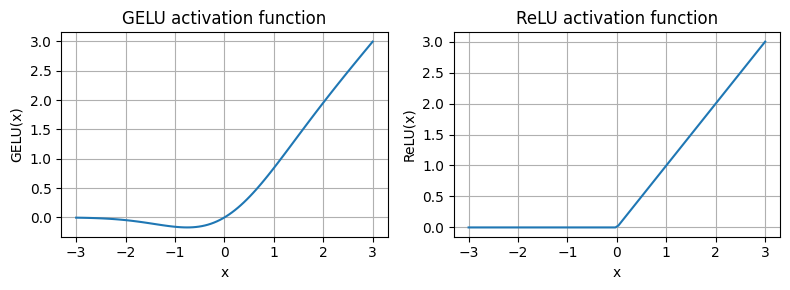

In [ ]:
class GELU(nn.Module):
  def __init__(self):
    super().__init__()

  def forward(self, x):
    return 0.5 * x * (1 + torch.tanh(
        torch.sqrt(torch.tensor(2.0 / torch.pi)) *
         (x + 0.044715 * torch.pow(x, 3))
         ))


import matplotlib.pyplot as plt
gelu, relu = GELU(), nn.ReLU()  #1

x = torch.linspace(-3, 3, 100)
y_gelu, y_relu = gelu(x), relu(x)
plt.figure(figsize=(8, 3))

for i, (y, label) in enumerate(zip([y_gelu, y_relu], ["GELU", "ReLU"]), 1):
  plt.subplot(1, 2, i)
  plt.plot(x, y)
  plt.title(f"{label} activation function")
  plt.xlabel("x")
  plt.ylabel(f"{label}(x)")
  plt.grid(True)
plt.tight_layout()
plt.show()

*--> **ReLU**
is a piecewise linear function that outputs the input directlyif it is positive; otherwise, it outputs zero.*

*--> **GELU** is a smooth, nonlinear function that approximates ReLU but witha non-zero gradient for almost all negative values.*

 *--> The smoothness of GELU can lead to better optimization
 properties during training, as it allows for more nuanced
 adjustments to the model’s parameters.*

*--> ReLU
 has a sharp corner at zero, which can
 sometimes make optimization harder, especially in networks
 that are very deep or have complex architectures.*

 *--> Moreover,
 unlike ReLU, which outputs zero for any negative input,
 GELU allows for a small, non-zero output for negative
 values.*

*--> This characteristic means that during the training
 process, neurons that receive negative input can still
 contribute to the learning process, albeit to a lesser extent
 than positive inputs.*


*--> Let’s use the GELU function to implement the small neural network module, FeedForward.*

#### **iii.2 A feed forward neural network module.**

In [ ]:
GPT_CONFIG_124M = {
    "vocab_size": 50257,     # Vocabulary size
    "context_length": 1024,  # Context length
    "emb_dim": 768,          # Embedding dimension
    "n_heads": 12,           # Number of attention heads
    "n_layers": 12,          # Number of layers
    "drop_rate": 0.1,        # Dropout rate
    "qkv_bias": False        # Query-Key-Value bias
 }

In [ ]:
class FeedForward(nn.Module):       # it processes each token independently and make it smarter
  def __init__(self, cfg):
    super().__init__()
    self.layers = nn.Sequential(nn.Linear(cfg["emb_dim"], 4 * cfg["emb_dim"]), # here the expansion is happening for eg nn.linear(768,3042), it gives more space to think.
                                GELU(),                                        # this adds non-linearity and lets model learn complex pattern
                                nn.Linear(4 * cfg["emb_dim"], cfg["emb_dim"]), # compression to original size
                                )
  def forward(self, x):
    return self.layers(x)

*--> The feed forward is a 2 layer MLP.*

*--> You see the 2 layers defined above , the embedding dimension suddenly changes to "4 * ..".*

*--> The FeedForward module plays a crucial role in enhancing the
model’s ability to learn from and generalize the data.*

*--> Although the input and output dimensions of this module are
the same, it internally expands the embedding dimension
into a higher-dimensional space through the first linear layer.*

*--> This expansion is followed by a
nonlinear GELU activation and then a contraction back to the
original dimension with the second linear transformation.*

*Input*

  ↓

*Self-Attention   ← (tokens talk to each other)*

  ↓

*FeedForward      ← (each token thinks individually)*

In [ ]:
ffn = FeedForward(GPT_CONFIG_124M)
x = torch.rand(2, 3, 768)
out = ffn(x)
print(out.shape)

torch.Size([2, 3, 768])


## **iv. Adding shortcut connections**

*--> Shortcut
 connections were proposed for deep networks in computer
vision (specifically, in residual networks) to mitigate the
 challenge of vanishing gradients.*

*--> The vanishing gradient
 problem refers to the issue where gradients (which guide
 weight updates during training) become progressively
 smaller as they propagate backward through the layers,
 making it difficult to effectively train earlier layers.*



 *--> Shortcut connection creates an
 alternative, shorter path for the gradient to flow through the
 network by skipping one or more layers, which is achieved
 by **adding the output of one layer to the output of a later
 layer**.*

 *--> This is why these connections are also known as **skip
 connections**. They play a crucial role in preserving the flow
 of gradients during the backward pass in training.*

#### **iv.1 A neural network to illustrate shortcut connections.**

In [ ]:
class ExampleDeepNeuralNetwork(nn.Module):
  def __init__(self, layer_sizes, use_shortcut):
    super().__init__()
    self.use_shortcut = use_shortcut
    self.layers = nn.ModuleList([       #1
        nn.Sequential(nn.Linear(layer_sizes[0], layer_sizes[1]),
                      GELU()),
        nn.Sequential(nn.Linear(layer_sizes[1], layer_sizes[2]),
                      GELU()),
        nn.Sequential(nn.Linear(layer_sizes[2], layer_sizes[3]),
                      GELU()),
        nn.Sequential(nn.Linear(layer_sizes[3], layer_sizes[4]),
                      GELU()),
        nn.Sequential(nn.Linear(layer_sizes[4], layer_sizes[5]),
                      GELU())
        ])
  def forward(self, x):
    for layer in self.layers:
      layer_output = layer(x)        # Compute the output of the current layer
      if self.use_shortcut and x.shape == layer_output.shape: #Check if shortcut can be applied
        x = x + layer_output
      else:
        x = layer_output
    return x

*--> The code implements a deep neural network with five layers,
 each consisting of a Linear layer and a GELU activation
 function. In the forward pass, we iteratively pass the input
 through the layers and optionally add the shortcut
 connections if the self.use_ shortcut attribute is set to True.*

**Why add input back??**

*->"Don’t forget the original input — just improve it"*

**❌ Without shortcut**

*-> You rewrite the entire paragraph every time*

**✅ With shortcut**

*You say:*

*“Keep the original paragraph, just add improvements”*

*✅ LayerNorm → stabilizes*

*✅ Attention → mixes tokens*

*✅ FeedForward → transforms tokens*

*✅ Residual → preserves + improves information*

*--> Let’s use this code to initialize a neural network without
 shortcut connections. Each layer will be initialized such that
 it accepts an example with three input values and returns
 three output values. The last layer returns a single output
 value:*

In [ ]:
layer_sizes = [3, 3, 3, 3, 3, 1]
sample_input = torch.tensor([[1., 0., -1.]])
torch.manual_seed(123)   #1
model_without_shortcut = ExampleDeepNeuralNetwork(
    layer_sizes, use_shortcut=False
    )

In [ ]:
def print_gradients(model, x):
  output = model(x)   # Forward pass
  target = torch.tensor([[0.]])

  loss = nn.MSELoss()
  loss = loss(output, target) # Calculates loss based on how close the target and output are

  loss.backward() #  Backward pass to calculate the gradients

  for name, param in model.named_parameters():
    if 'weight' in name:
      print(f"{name} has gradient mean of {param.grad.abs().mean().item()}")


.*--> This code specifies a loss function that computes how close
 the model output and a user-specified target (here, for
 simplicity, the value 0) are. Then, when calling
 loss.backward(), PyTorch computes the loss gradient for each
 layer in the model.*

*--> We can iterate through the weight
parameters via model.named_parameters(). Suppose we have a
 3 × 3 weight parameter matrix for a given layer.*

 *--> In that
 case, this layer will have 3 × 3 gradient values, and we print
 the mean absolute gradient of these 3 × 3 gradient values to
 obtain a single gradient value per layer to compare the
 gradients between layers more easily.*

*--> The .backward() method is a convenient method in
PyTorch that computes loss gradients, which are required
during model training.*

In [ ]:
print_gradients(model_without_shortcut, sample_input)

layers.0.0.weight has gradient mean of 0.00020173584925942123
layers.1.0.weight has gradient mean of 0.00012011159560643137
layers.2.0.weight has gradient mean of 0.0007152040489017963
layers.3.0.weight has gradient mean of 0.0013988736318424344
layers.4.0.weight has gradient mean of 0.005049645435065031


In [ ]:
torch.manual_seed(123)
model_with_shortcut = ExampleDeepNeuralNetwork(
    layer_sizes, use_shortcut=True
    )
print_gradients(model_with_shortcut, sample_input)

layers.0.0.weight has gradient mean of 0.22169791162014008
layers.1.0.weight has gradient mean of 0.20694105327129364
layers.2.0.weight has gradient mean of 0.32896995544433594
layers.3.0.weight has gradient mean of 0.2665732204914093
layers.4.0.weight has gradient mean of 1.3258540630340576


## **v. Transformer block - Connecting attention and linear layers.**

*Here we will implement the transformer block.*

*--> It is repeated a dozen times in the 124-million
parameter GPT-2 architecture, combines several concepts we have previously covered: multi-head attention, layer normalization, dropout, feed forward layers, and GELU activations.*

*--> When a
 transformer block processes an input sequence, each
 element in the sequence (for example, a word or subword
 token) is represented by a fixed-size vector (in this case,
 768 dimensions).*

*--> The operations within the transformer
 block,are divided into 2 major parts - **multi-head attention** & **feed forward
 layers**, are designed to transform these vectors along with
 preserving its  dimensionality at the end (output).*

***--> Transformer must learn 2 different things -***

*- **Token interaction** - Self-attention mechanism in the multi
head attention block identifies and analyzes relationships
 between elements in the input sequence.*

*--> **Token transformation** - Feed forward network modifies the data individually at each
 position. This enables a more nuanced
 understanding of the input & enhances
 the model’s overall capacity for handling complex data
 patterns.*

In [ ]:
GPT_CONFIG_124M = {
    "vocab_size": 50257,     # Vocabulary size
    "context_length": 1024,  # Context length
    "emb_dim": 768,          # Embedding dimension
    "n_heads": 12,           # Number of attention heads
    "n_layers": 12,          # Number of layers
    "drop_rate": 0.1,        # Dropout rate
    "qkv_bias": False        # Query-Key-Value bias
 }

In [ ]:
# from chapter03 import MultiHeadAttention

class TransformerBlock(nn.Module):
  def __init__(self, cfg):
    super().__init__()

    self.att = MultiHeadAttention(              # this is where tokens look at other tokens and gather context
        d_in=cfg["emb_dim"],
        d_out=cfg["emb_dim"],
        context_length=cfg["context_length"],
        num_heads=cfg["n_heads"],
        dropout=cfg["drop_rate"],
        qkv_bias=cfg["qkv_bias"]
        )

    self.ff = FeedForward(cfg)
    self.norm1 = LayerNorm(cfg["emb_dim"]) #this creates an object of class layer_norm and call _init_, so after this line self.norm1 is a layernorm object.
    self.norm2 = LayerNorm(cfg["emb_dim"]) #these are not functions , but the callable objects
    self.drop_shortcut = nn.Dropout(cfg["drop_rate"])

  def forward(self, x):

    shortcut = x        # shortcut connection for attention block
    x = self.norm1(x) # as the class layernorm contains "nn.module", so self.norm1(x) will react as self.norm1.forward(x) and call the forward function of class Layernorm.
                       #also, this is called pre-layer norm architecture
    x = self.att(x)
    x = self.drop_shortcut(x) #dropout in the shortcut block
    x = x + shortcut      #Add the original input back

    shortcut = x         #Shortcut connection for feed forward block
    x = self.norm2(x)
    x = self.ff(x)
    x = self.drop_shortcut(x)
    x = x + shortcut      #Adds the original input back
    return x

*--> Transformer block expects an embedding vector as x -*

*- Saved as shortcut as same and then passed into layer normalisation (norm1)*

*- Layernorm gives back a  tensor after calculating mean, var, norm and then output multiplication with scale and shift. Its shape is for eg.(1,4,768).*

*- MHA gives back the context vector for those embeddings.*

*- Passed to the feedforward block for the transformations without changing the shape and all.*

In [ ]:
torch.manual_seed(123)
x = torch.rand(2, 4, 768)  #1
block = TransformerBlock(GPT_CONFIG_124M)
output = block(x)

print("Input shape:", x.shape)
print("Output shape:", output.shape)

Input shape: torch.Size([2, 4, 768])
Output shape: torch.Size([2, 4, 768])


*--> Transformer block maintains the input
dimensions in its output, indicating that the transformer
architecture processes sequences of data without altering
their shape throughout the network.*

*--> This design enables its effective application across a
wide range of sequence-to-sequence tasks, where each
output vector directly corresponds to an input vector,
maintaining a one-to-one relationship. However, the output
is a context vector that encapsulates information from the
entire input sequence.*

*--> This means that while
the physical dimensions of the sequence (length and feature
size) remain unchanged as it passes through the transformer
block, the content of each output vector is re-encoded to
integrate contextual information from across the entire input
sequence.*

## **vi. Coding the GPT Model.**

*-->  Starting from the bottom, tokenized text
is first converted into token embeddings, which are then augmented
with positional embeddings.*

*--> This combined information forms a tensor
that is passed through a series of transformer blocks shown in the
center (each containing multi-head attention and feed forward neural
network layers with dropout and layer normalization), which are stacked
on top of each other and repeated 12 times.*

*--> Transformer block is repeated many times throughout a GPT
model architecture. In the case of the 124-million-parameter
GPT-2 model, it’s repeated 12 times, which we specify via
the n_layers entry in the GPT_CONFIG_124M dictionary. This
transform block is repeated 48 times in the largest GPT-2
model with 1,542 million parameters.*

*--> The output from the final transformer block then goes
through a final layer normalization step before reaching the
linear output layer. This layer maps the transformer’s output
to a high-dimensional space (in this case, 50,257
dimensions, corresponding to the model’s vocabulary size) to
predict the next token in the sequence.*


#### **vii.1 The GPT model architecture implementation**

In [ ]:
GPT_CONFIG_124M = {
    "vocab_size": 50257,     # Vocabulary size
    "context_length": 1024,  # Context length
    "emb_dim": 768,          # Embedding dimension
    "n_heads": 12,           # Number of attention heads
    "n_layers": 12,          # Number of layers
    "drop_rate": 0.1,        # Dropout rate
    "qkv_bias": False        # Query-Key-Value bias
 }

In [ ]:
class GPTModel(nn.Module):
  def __init__(self, cfg):
    super().__init__()
    self.tok_emb = nn.Embedding(cfg["vocab_size"], cfg["emb_dim"])
    self.pos_emb = nn.Embedding(cfg["context_length"], cfg["emb_dim"])
    self.drop_emb = nn.Dropout(cfg["drop_rate"])
    self.trf_blocks = nn.Sequential(
        *[TransformerBlock(cfg) for _ in range(cfg["n_layers"])])
    self.final_norm = LayerNorm(cfg["emb_dim"])
    self.out_head = nn.Linear(
        cfg["emb_dim"], cfg["vocab_size"], bias=False)

  def forward(self, in_idx):
    batch_size, seq_len = in_idx.shape
    tok_embeds = self.tok_emb(in_idx) #1 test_token
    pos_embeds = self.pos_emb(torch.arange(
        seq_len, device=in_idx.device))   #test_pos
    x = tok_embeds + pos_embeds
    x = self.drop_emb(x) #This will not change the shape from tok_embed + pos_embed
    x = self.trf_blocks(x)
    x = self.final_norm(x)
    logits = self.out_head(x) #shape of (b,seq_len,vocab_size)
    return logits

**Your model combines:**

*1️⃣ Embeddings → understanding words*

*2️⃣ Positional encoding → understanding order*

*3️⃣ Attention → understanding relationships*

*4️⃣ FeedForward → deep processing*

*5️⃣ Residual + Norm → stable learning*

*6️⃣ Output head → prediction*

*--> The __ init __ constructor of this GPTModel class initializes the
token and positional embedding layers using the
configurations passed in via a Python dictionary, cfg. These
embedding layers are responsible for converting input token
indices into dense vectors and adding positional information.*

*--> The forward method takes , a batch of input token indices-->
computes their embeddings --> applies the positional
embeddings -->passes the sequence through the transformer
blocks--> normalizes the final output -->and then computes the
logits, representing the next token’s unnormalized
probabilities.*

*--> At this point , the model has no idea about "next token", there is nothing in this model that says: "this predicts token t+1".*

*--> The model does not know what the logit mean. Meaning is only assigned only by the loss function during training , where the inputs are put against the target values and then forced to realign the proababilities in the logits generated at the last step.*

***Explaination of tok_embeds***

*-->Initially , tok_embeds is an embedding table only as initialised under the init function( "Vocab_size" by "Emb_dim").*

*Now in_idx is passed into this token_Embedding , so what it will do is*

*--> It will look up the token id in the embedding table created (remember this thing from initial chapters ?? that it is just a "look up" operation in the embedding table)*

*--> Just for example if in_idx has a array or tensor which contains a value [[1,4,5]], then it will get the "1st" , "4th" and "5th" row value from that tok embedding table created in the init function.*

*--> Input shape which enters into the token_embeding function is (batch, seq_len) which in this case is (1,4) and output shape is along with embedding and becomes (batch,seq_len,emb_dim) which in this case is (1,4,768)*.

***Explaination of pos_embed***

*--> Like in tok_embed , we have made an embeddding table in pos embed of (context length and emb_dim).*

*--> We will look up the corresponding row for numbers in sequence length(i.e. 1,2,3,4..) from the in_idx shape , in the embedding table.*

*--> We will add tok_embed & pos_embed , like for eg. if vector in row1 of tok_embed is [[-0.37, 0.95,.....]] and pos_embed is [[0.02, 0.11,...]], then addition will be x= [[-0.37, 0.95,.....]] + [[0.02, 0.11,...]] = [[-0.35, 1.06,..]]*

*--> Position embedding is passed the "sequence length" of the input (like in this case it was only 4) unlike the token embedding where full vocab is passed.*

*--> Input shape which enters into the pos_embeding function is (seq_len) which in this case is (4) and output shape is along with embedding and becomes (seq_len,emb_dim) which in this case is (4,768)*.

*Addition of both take place without batch shape change-*

*--> tok_embeds: (1, 4, 768)*

*--> pos_embeds:    (4, 768)*

*(1, 4, 768)*

*+(4, 768)*

*(1, 4, 768)*

*--> Then in **dropout** shape remains same i.e. batch, seq_len,emb_dim*

*--> Then in **transformer block**, mha and ff are used to transform the vector.*

*--> In the out_head line ,**logits** are calcuted , for each token position in the sequence: GPT outputs one score per vocab token , like 1 token(1 value) which is distributed into 768 values to make a vector is used to score the next token(single value)from 50k+ vocab tokens and then mention the score against them , which makes a row having 50k+ values (vocab_size).*

In [ ]:
torch.manual_seed(123)
model = GPTModel(GPT_CONFIG_124M) # this is a constructor basically and object is created here.

out = model(batch)
print("Input batch:\n", batch)
print("\nOutput shape:", out.shape)
print(out)

Input batch:
 tensor([[6109, 3626, 6100,  345],
        [6109, 1110, 6622,  257]])

Output shape: torch.Size([2, 4, 50257])
tensor([[[ 0.3613,  0.4222, -0.0711,  ...,  0.3483,  0.4661, -0.2838],
         [-0.1792, -0.5660, -0.9485,  ...,  0.0477,  0.5181, -0.3168],
         [ 0.7120,  0.0332,  0.1085,  ...,  0.1018, -0.4327, -0.2553],
         [-1.0076,  0.3418, -0.1190,  ...,  0.7195,  0.4023,  0.0532]],

        [[-0.2564,  0.0900,  0.0335,  ...,  0.2659,  0.4454, -0.6806],
         [ 0.1230,  0.3653, -0.2074,  ...,  0.7705,  0.2710,  0.2246],
         [ 1.0558,  1.0318, -0.2800,  ...,  0.6936,  0.3205, -0.3178],
         [-0.1565,  0.3926,  0.3288,  ...,  1.2630, -0.1858,  0.0388]]],
       grad_fn=<UnsafeViewBackward0>)


*--> Lets initialize a 124 million parameter GPT model using GPT_CONFIG_124M dictionary.*

*--> The output tensor has the shape [2, 4, 50257],
since we passed in two input texts with four tokens each.
The last dimension, 50257, corresponds to the vocabulary size
of the tokenizer.*

In [ ]:
total_params = sum(p.numel() for p in model.parameters())
print(f"Total number of parameters: {total_params:,}")

Total number of parameters: 163,009,536


*-->  Earlier, we
spoke of initializing a 124-million-parameter GPT model, so
why is the actual number of parameters 163 million?*

*--> The reason is a concept called weight tying, which was used
in the original GPT-2 architecture. It means that the original
GPT-2 architecture reuses the weights from the token
embedding layer in its output layer.*


*-->  To understand better,
let’s take a look at the shapes of the token embedding layer
and linear output layer that we initialized on the model via the
GPTModel earlier:*

In [ ]:
print("Token embedding layer shape:", model.tok_emb.weight.shape)
print("Output layer shape:", model.out_head.weight.shape)

Token embedding layer shape: torch.Size([50257, 768])
Output layer shape: torch.Size([50257, 768])


*--> As we can see from the print outputs, the weight tensors for
both these layers have the same shape:*

*--> The token embedding and output layers are very large due
to the number of rows for the 50,257 in the tokenizer’s
vocabulary. Let’s remove the output layer parameter count
from the total GPT-2 model count according to the weight
tying:*

In [ ]:
total_params_gpt2 = (
    total_params - sum(p.numel()
    for p in model.out_head.parameters())
    )

print(f"Number of trainable parameters "
      f"considering weight tying: {total_params_gpt2:,}"
      )

Number of trainable parameters considering weight tying: 124,412,160


*--> Model is now only 124 million
parameters large, matching the original size of the GPT-2
model.*

*--> Weight tying reduces the overall memory footprint and
computational complexity of the model.*

*--> However , using separate token embedding and output
layers results in better training and model performance.*

*--> let’s compute the memory requirements of the 163
million parameters in our GPTModel object:*

In [ ]:
total_size_bytes = total_params * 4
 #1
total_size_mb = total_size_bytes / (1024 * 1024)
 #2
print(f"Total size of the model: {total_size_mb:.2f} MB")

Total size of the model: 621.83 MB


## **vii. Generating Text**

*--> The process by which a GPT model goes from output tensors
to generated text involves several steps like decoding the output
tensors, selecting tokens based on a probability distribution,
and converting these tokens into human-readable text.*


Encodes .
.
.
..

.


*--> In the next token generation process , the model outputs a
matrix with vectors representing potential next tokens.*

*--> The
vector corresponding to the next token is extracted and
converted into a probability distribution via the softmax
function.*

*--> Within the vector containing the resulting
probability scores, the index of the highest value is located,
which translates to the token ID.*

*--> This token ID is then
decoded back into text, producing the next token in the
sequence.*

*--> Finally, this token is appended to the previous
inputs, forming a new input sequence for the subsequent
iteration.*

*--> This step-by-step process enables the model to
generate text sequentially, building coherent phrases and
sentences from the initial input context.*

#### **vii.1  A function for the GPT model to generate text**

In [ ]:
GPT_CONFIG_124M = {
    "vocab_size": 50257,     # Vocabulary size
    "context_length": 1024,  # Context length
    "emb_dim": 768,          # Embedding dimension
    "n_heads": 12,           # Number of attention heads
    "n_layers": 12,          # Number of layers
    "drop_rate": 0.1,        # Dropout rate
    "qkv_bias": False        # Query-Key-Value bias
 }

In [ ]:
def generate_text_simple(model, idx,  # idx is a (batch, n_tokens) array of indices in the current context.
                         max_new_tokens, context_size):
  for _ in range(max_new_tokens):
    idx_cond = idx[:, -context_size:] #context cropping , if text is too long , use the last part only.
    with torch.no_grad():
      logits = model(idx_cond) # here we call "forward from the GPT_Model"

    logits = logits[:, -1, :]       #  Focuses only on the last time step/token, so that (batch, n_token,vocab_size) becomes (batch, vocab_size)
    probas = torch.softmax(logits, dim=-1)  # probas has shape (batch, vocab_size).
    idx_next = torch.argmax(probas, dim=-1, keepdim=True) # idx_next has shape (batch, 1).
    idx = torch.cat((idx, idx_next), dim=1)  # Appends sampled index to the running sequence, where idx has shape (batch, n_tokens+1)

  return idx

*--> The above code iterates for a specified number of new tokens to be
generated, crops the current context to fit the model’s
maximum context size, computes predictions, and then
selects the next token based on the highest probability
prediction.*


*--> To code the generate_text_simple function, we use a softmax
function to convert the logits into a probability distribution
from which we identify the position with the highest value
via torch.argmax.*

**Key mental model -**

*--> GPT generation is not "generate n no. of tokens(depending upon "max_new_token" parameter) , it is generate 1 token -> append -> repeat*.

*--> So for the existing tokens 4 and max_new_token value=10, it will produce total of 4 + 10 tokens = 14 tokens.These 14 tokens will be taken forward for the training and all purposes.*

*--> Let’s now try out the generate_text_simple function with the
"Hello, I am" context as model input. First, we encode the
input context into token IDs:*

In [ ]:
start_context = "Hello, I am"
encoded = tokenizer.encode(start_context)
print("encoded:", encoded)
encoded_tensor = torch.tensor(encoded).unsqueeze(0)
print("encoded_tensor.shape:", encoded_tensor.shape)

encoded: [15496, 11, 314, 716]
encoded_tensor.shape: torch.Size([1, 4])


*--> Next, we put the model into .eval() mode. This disables
random components like dropout, which are only used
during training, and use the generate_text_simple function on
the encoded input tensor:*

In [ ]:
model.eval()               # Disables dropout since we are not training the model
out = generate_text_simple(
    model=model,
    idx=encoded_tensor,
    max_new_tokens=6,
    context_size=GPT_CONFIG_124M["context_length"] #1024
    )
print("Output:", out)
print("Output length:", len(out[0]))

Output: tensor([[15496,    11,   314,   716, 27018, 24086, 47843, 30961, 42348,  7267]])
Output length: 10


In [ ]:
out.shape

torch.Size([1, 10])

*--> Also one thing more that, tensors have the dimension, unlike any other object like list etc.*

*--> Using the .decode method of the tokenizer, we can convert
the IDs back into text--*

In [ ]:
decoded_text = tokenizer.decode(out.squeeze(0).tolist())
print(decoded_text)

Hello, I am Featureiman Byeswickattribute argue


#**4. PRETRAINING ON UNLABELLED DATA**

##**i.  Evaluating generative text models**

**An overview of the topics covered -**

*1. Text generation*-

*2. Text evaluation*

*3.Training and validation losses(evaluate how well the model performs)*

*4.LLM training function(Train the model to generate human-like text)*

*5.Text generation strategies(Implement additional LLM text generation strategies to reduce the training data memorization).*

*6.Weight saving and loading(Implement functions to save and load the LLM weights to use or continue training the LLM later)*

*7.Pretrained weights from OpenAI(Load pretrained weights from OpenAI into our LLM model).*

###**a. Using GPT to generate text**

In [ ]:
import torch
# from chapter04 import GPTModel

GPT_CONFIG_124M = {
    "vocab_size": 50257,
    "context_length": 256, # We've shorten the context length from 1024 to 256
    "emb_dim": 768,
    "n_heads": 12,
    "n_layers": 12,
    "drop_rate": 0.1,      # Its possible and common to set dropout rate to 0.
    "qkv_bias": False
    }

torch.manual_seed(123)
model = GPTModel(GPT_CONFIG_124M)
model.eval()

GPTModel(
  (tok_emb): Embedding(50257, 768)
  (pos_emb): Embedding(256, 768)
  (drop_emb): Dropout(p=0.1, inplace=False)
  (trf_blocks): Sequential(
    (0): TransformerBlock(
      (att): MultiHeadAttention(
        (W_query): Linear(in_features=768, out_features=768, bias=False)
        (W_key): Linear(in_features=768, out_features=768, bias=False)
        (W_value): Linear(in_features=768, out_features=768, bias=False)
        (out_proj): Linear(in_features=768, out_features=768, bias=True)
        (dropout): Dropout(p=0.1, inplace=False)
      )
      (ff): FeedForward(
        (layers): Sequential(
          (0): Linear(in_features=768, out_features=3072, bias=True)
          (1): GELU()
          (2): Linear(in_features=3072, out_features=768, bias=True)
        )
      )
      (norm1): LayerNorm()
      (norm2): LayerNorm()
      (drop_shortcut): Dropout(p=0.1, inplace=False)
    )
    (1): TransformerBlock(
      (att): MultiHeadAttention(
        (W_query): Linear(in_features

*--> Originally, the GPT-2 model with 124 million parameters was
configured to handle up to 1,024 tokens.*

*--> After the training
process, we will update the context size setting and load
pretrained weights to work with a model configured for a
1,024-token context length.*

####**a.1 Utility functions for text to token ID conversion**

In [ ]:
import tiktoken
# from chapter04 import generate_text_simple

def text_to_token_ids(text, tokenizer):
    encoded = tokenizer.encode(text, allowed_special={'<|endoftext|>'})
    encoded_tensor = torch.tensor(encoded).unsqueeze(0)    #.unsqueeze(0) adds the batch dimension which is required by GPT2 model even if batch dim is 1.
    return encoded_tensor

def token_ids_to_text(token_ids, tokenizer):
    flat = token_ids.squeeze(0)                #Removes batch dimension
    return tokenizer.decode(flat.tolist())

start_context = "Every effort moves you"

tokenizer = tiktoken.get_encoding("gpt2")
token_ids = generate_text_simple(
    model=model,
    idx=text_to_token_ids(start_context, tokenizer),
    max_new_tokens=10,
    context_size=GPT_CONFIG_124M["context_length"] #256
)

print("Output text:\n", token_ids_to_text(token_ids, tokenizer))

Output text:
 Every effort moves you rentingetic wasnم refres RexMeCHicular stren


*Three-step text generation process
using a GPT model.*

*--> First, the tokenizer converts input text
into a series of token IDs (see chapter 2).*

*--> Second, the
model receives these token IDs and generates corresponding
logits, which are vectors representing the probability
distribution for each token in the vocabulary (see chapter 4).*

*--> Third, these logits are converted back into token IDs, which
the tokenizer decodes into human-readable text, completing
the cycle from textual input to textual output.*

### **b.Calculating the text generation loss**

**Overall flow from input text to LLM generated text using five step procedure.**

*--> 1. Use vocab to map the input text to token IDs.*

*--> 2. Obtain seven dimensional probability row vector for each input token via the softmax function.*

*--> 3. Locate the index position with the highest probability value in each row vector , which is done via the argmax function.*

*--> 4. Obtain all predicted token IDs as the index positions with the highest probabilities.*

*--> 5. Map index positions back into text via the inverse vocabulary.*

In [ ]:
inputs = torch.tensor([[16833, 3626, 6100],   # ["every effort moves",
[40,    1107, 588]])   #  "I really like"]

targets = torch.tensor([[3626, 6100, 345  ],  # [" effort moves you",
[1107, 588, 11311]])  #  " really like chocolate"]

***In the above code***

*--> Consider these two input examples, which have already
been mapped to token IDs.(Step-1).*

*--> Matching these inputs, the targets contain the token IDs we
want the model to produce.(Step-1).*

*-->  targets are the inputs but shifted one position
forward, a concept we covered in chapter 2 during the
implementation of the data loader. This shifting strategy is
crucial for teaching the model to predict the next token in a
sequence.*

***In the below code -***

*--> Now we feed the inputs into the model to calculate logits
vectors for the two input examples, each comprising three
tokens. Then we **apply the softmax function to transform
these logits into probability scores** (probas) (step-2)*

In [ ]:
with torch.no_grad(): # Disables gradient tracking since we are not training yet
  logits = model(inputs) # logits are a raw unnormalized scores for every word in the vocabulary, For each position, scores for every possible next word

probas = torch.softmax(logits, dim=-1) # Probability of each token in vocab , here logits become probability and meaningful as they are waste as a raw unnormalized score
print(probas.shape) # tensor dimension of probability score

torch.Size([2, 3, 50257])


***In the above code***

*--> The first number, 2, corresponds to the two examples (rows)
in the inputs, also known as batch size. Basically , 2 rows in the "Input" are considered as 2 batches ,and same with the "target".*

*--> The second number,
3, corresponds to the number of tokens in each input (row).*

*--> Finally, the last number corresponds to the embedding
dimensionality, which is determined by the vocabulary size ,i.e. for each token position ,GPT predicts a probability for every possible token in the GPT-2 vocabulary.*

*--> So at each (batch,position): 50257 probabilities that sum to 1.*

***Working of probas -***

*-> lets interpret probas[0,1]*

*--> Probability distribution over all 50,257 tokens for batch 0, position 1 , which for the batch "every effort moves" , corresponds to predicting next token after "effort".*

*--> What this tensor represents: probas[batch,time_step,token_id] -- "The probability that token_id is the next token given everything up to time_step."*

***--> Concrete interpretation with your data***

*Batch 0: "Every effort moves" -*

*Index	 Meaning*

*- probas[0, 0, :]	P(next token | "every")*

*- probas[0, 1, :]	P(next token | "every effort")*

*- probas[0, 2, :]	P(next token | "every effort moves")*


*--> Following the conversion from logits to probabilities via the
softmax function, **the generate_text_simple function then
converts the resulting probability scores back into text.(step 3-5)***

*Why we usually DON’T use all probas during generation -*

***In training:***

*-->We use all (batch, seq_len) positions.*

*-->Compute loss against targets.*

***In generation:***

*--> We only care about last token*

*--> In the below code , We are completing steps 3 and 4 by applying the argmax
function to the probability scores to obtain the corresponding
token IDs:*

In [ ]:
token_ids = torch.argmax(probas, dim=-1, keepdim=True)
print("Token IDs:\n", token_ids)

Token IDs:
 tensor([[[16657],
         [  339],
         [42826]],

        [[49906],
         [29669],
         [41751]]])


**In above code**,

*--> We have 2 input batches, each containing 3
tokens, applying the argmax function to the probability scores
(step 3) yields 2 sets of outputs, each with
3 predicted token IDs:*

*--> argmax function picks the token Id with the highest probability for each batch and time step.*

In [ ]:
print(f"Targets batch 1: {token_ids_to_text(targets[0], tokenizer)}")
print(f"Outputs batch 1:"f" {token_ids_to_text(token_ids[0].flatten(), tokenizer)}")

Targets batch 1:  effort moves you
Outputs batch 1:  Armed heNetflix


*--> When we decode these tokens, we find that these output
tokens are quite different from the target tokens we want
the model to generate:*

*--> The model produces random text that is different from the
target text because it has not been trained yet.*

**Outputs** -

*--> Come from argmax over randomly initialized weights.*

*--> Have no learned language structure yet.*

*--> Decode to random or odd-looking tokens.*


*We now
want to evaluate the performance of the model’s generated
text numerically via a loss. Not only is this
useful for measuring the quality of the generated text, but
it’s also a building block for implementing the training
function.*

In [ ]:
text_idx = 0
target_probas_1 = probas[text_idx, [0, 1, 2], targets[text_idx]]
## print("Text 1:", target_probas_1)

text_idx = 1
target_probas_2 = probas[text_idx, [0, 1, 2], targets[text_idx]]

torch.set_printoptions(precision=10, sci_mode=True)

print("Text 1:", target_probas_1)
print("Text 2:", target_probas_2)

Text 1: tensor([7.4540497735e-05, 3.1060561014e-05, 1.1562784493e-05])
Text 2: tensor([1.0336677406e-05, 5.6775919802e-05, 4.7559287850e-06])


***In the above code -***

*--> Basically probas is 3D tensor already initialised before the above code as you could also see which has probabilities mentioned all over in it , so in the above code we are just tracking down the probabilies , like give me the value of probability at position Probas[0,1,1].And this thing is done for 3 positions thats why 3 outputs are there.*


*--> For each of the two input texts, we printed the initial
softmax probability scores corresponding to the target
tokens.*

*--> probas[batch,time_step,token_id] = P(token_id | context up to time_step)*

In [ ]:
log_probas = torch.log(torch.cat((target_probas_1, target_probas_2)))
torch.set_printoptions(precision=4)
print(log_probas)

tensor([ -9.5042, -10.3796, -11.3677, -11.4798,  -9.7764, -12.2561])


***In the above code -***

*--> Calculate the **loss for the probability scores/ log probabilties** of
the two example batches, target_probas_1 and target_probas_2.*

*--> torch.cat(..) concatenates both (target_probas1 and target_probas2) along dimesion 0:
tensor([
  7.4541e-05,
  3.1061e-05,
  1.1563e-05,
  1.0337e-05,
  5.6776e-05,
  4.7559e-06
]) with shape (6,).*

*--> Post above, torch.log(..) converts the probs into log probs.*
  
*--> So now ,we have all correct-token probabilities in the batch, flattened.*

**Also ,**

*--> Because 0 < p <= 1 , so log(p) <= 0.*

*--> It means **High probability → log closer to 0** and **Low probability → large negative number**.*

*Thats why Wrong predictions are punished heavily*

**Calculating the loss also involves these steps of probabilities -**

*Logits -> Probabilities -> Target probabilities -> Log probabilities -> Average log probability -> Negative average log probability*

***In the below code***

*--> We combine these log probabilities into a single score by computing the average.*

In [ ]:
avg_log_probas = torch.mean(log_probas)
print(avg_log_probas)

tensor(-10.7940)


*Basically , average log probability is directly related to loss. As much the average probability increases or move towards 0 , the loss decreases and move towards 0.*

**In the below code -**

*Before we apply the cross_entropy function, let’s briefly recall
the shape of the logits and target tensors:*

In [ ]:
print("Logits shape:", logits.shape)
print("Targets shape:", targets.shape)

Logits shape: torch.Size([2, 3, 50257])
Targets shape: torch.Size([2, 3])


**As we can see,**

*-->The logits tensor has three dimensions:
batch size, number of tokens, and vocabulary size.*

*--> The
targets tensor has two dimensions: batch size and number of
tokens.*

*--> For the cross_entropy loss function in PyTorch, we want to
flatten these tensors by combining them over the batch
dimension.*

In [ ]:
logits_flat = logits.flatten(0, 1)
targets_flat = targets.flatten()
print("Flattened logits:", logits_flat.shape)
print("Flattened targets:", targets_flat.shape)

Flattened logits: torch.Size([6, 50257])
Flattened targets: torch.Size([6])


In the above code -

*--> logits.flatten merges the (2,3,50257) into (6,50257).*

*--> targets.flatten merges the (2,3) into (6,).*

*--> **flattening has been done because cross entropy expects this shape only , i.e. input  → (N, C) and target → (N).***

*--> Previously in the above code,  we applied the softmax function, selected the
probability scores corresponding to the target IDs, and
computed the negative average log probabilities.*

*--> PyTorch’s
cross_entropy function will take care of all these steps for us.*

In [ ]:
loss = torch.nn.functional.cross_entropy(logits_flat, targets_flat)
print(loss)

tensor(10.7940)


*--> The resulting loss is the same that we obtained previously
when applying the individual steps in manually.*

###**c. Calculating the training and validation set losses**

In [ ]:
file_path = "the-verdict.txt"
with open(file_path, "r", encoding="utf-8") as file:
    text_data = file.read()

In [ ]:
total_characters = len(text_data)
total_tokens = len(tokenizer.encode(text_data))
print("Characters:", total_characters)
print("Tokens:", total_tokens)

Characters: 20479
Tokens: 5145


**When preparing the data loaders -**

*-> We split the input text into training and validation set portions.*

*-> Then we tokenize the text (only
shown for the training set portion for simplicity) and divide the
tokenized text into chunks of a user-specified length (here, 6).*

*-> Finally,
we shuffle the rows and organize the chunked text into batches (here,
batch size 2), which we can use for model training.*

**Note -**

*We are training the model with training data
presented in similarly sized chunks for simplicity and
efficiency. However, in practice, it can also be beneficial
to train an LLM with variable-length inputs to help the
LLM to better generalize across different types of inputs
when it is being used.*

*To implement the data splitting and loading, we first define a
train_ratio to use 90% of the data for training and the
remaining 10% as validation data for model evaluation
during training.*

In [ ]:
train_ratio = 0.90
split_idx = int(train_ratio * len(text_data))
train_data = text_data[:split_idx]
val_data = text_data[split_idx:]

*--> Using the train_data and val_data subsets, we can now create
the respective data loader reusing the create_dataloader_v1
code.*

In [ ]:
GPT_CONFIG_124M = {
    "vocab_size": 50257,
    "context_length": 256, # We've shorten the context length from 1024 to 256
    "emb_dim": 768,
    "n_heads": 12,
    "n_layers": 12,
    "drop_rate": 0.1,      # Its possible and common to set dropout rate to 0.
    "qkv_bias": False
    }

In [ ]:
# from chapter02 import create_dataloader_v1
torch.manual_seed(123)
train_loader = create_dataloader_v1(
    train_data,
    batch_size=2,
    max_length=GPT_CONFIG_124M["context_length"],
    stride=GPT_CONFIG_124M["context_length"],
    drop_last=True,
    shuffle=True,
    num_workers=0
)
val_loader = create_dataloader_v1(
    val_data,
    batch_size=2,
    max_length=GPT_CONFIG_124M["context_length"],
    stride=GPT_CONFIG_124M["context_length"],
    drop_last=False,
    shuffle=False,
    num_workers=0
)


*--> The above data loader will be producing token sequences like in previous chapter.*

*--> Data loader is about stacking batches upon each other so that computation can be applied over the big batches level which internally will process token by token or sequence by sequence.*

*For eg . at the end -*

*Dataloader = [*
  
*batch_0 ,*

*batch_1,*

*batch_2,*

*...*

*]*

*--> **Max length = 256** means each training example is 256 tokens long and GPT will predict 256 next tokens per sequence. This exactly matches the models attention window.*

*--> **Stride = max length** means no overlap between consecutive sequence and Each token is used only once per epoch.*

*Eg. tokens[0 : 256]
tokens[256 : 512]
tokens[512 : 768]
...*

**--> What create_dataloader_v1 is doing conceptually**

1. Tokenizes the input text.

2. Uses a sliding window over tokens

3. Creates (input, target) pairs where: target = input shifted by one token.

4. Wraps everything in a PyTorch DataLoader.

So each batch contains:

x: (batch_size, max_length)
y: (batch_size, max_length)


**Training loader choices**

**-> shuffle=True**

*--> Shuffles sequences, not tokens & Prevents learning order-specific artifacts.*

*--> Standard practice for training.*

**-> drop_last=True**

*--> This means:If the last batch has fewer than 2 samples → discard it.*

**Validation order choices**

**-> shuffle=False**

*--> Preserves text order & makes validation deterministic.*

*--> Easier to debug and compare losses.*

**drop_last=False**

*--> Keeps all validation samples & You don’t care about batch-size consistency here.*

*--> You want all validation data evaluated.*

**In the below code:-**

*As an optional check, we can iterate through the data
loaders to ensure that they were created correctly.*

In [ ]:
print("Train loader:")

for x, y in train_loader:
  print(x.shape, y.shape)

print("\nValidation loader:")

for x, y in val_loader:
  print(x.shape, y.shape)

Train loader:
torch.Size([2, 256]) torch.Size([2, 256])
torch.Size([2, 256]) torch.Size([2, 256])
torch.Size([2, 256]) torch.Size([2, 256])
torch.Size([2, 256]) torch.Size([2, 256])
torch.Size([2, 256]) torch.Size([2, 256])
torch.Size([2, 256]) torch.Size([2, 256])
torch.Size([2, 256]) torch.Size([2, 256])
torch.Size([2, 256]) torch.Size([2, 256])
torch.Size([2, 256]) torch.Size([2, 256])

Validation loader:
torch.Size([2, 256]) torch.Size([2, 256])


**--> The above output means -**

*9 training batches and each batch has:2 sequences*

*256 tokens per sequence*

**Each batch produces:** 2 × 256 = 512 next-token predictions

**In the below code:-**

*We implement a utility function to calculate the cross
entropy loss of a given batch returned via the training and
validation loader.*

In [ ]:
def calc_loss_batch(input_batch, target_batch, model, device):
  input_batch = input_batch.to(device)        #1
  target_batch = target_batch.to(device)
  logits = model(input_batch) #Returns logits.shape(batch_size,context_length,vocab_size)
  loss = torch.nn.functional.cross_entropy(
      logits.flatten(0, 1), target_batch.flatten()
  )
  return loss  # returns a scalar tensor

**In the above code:-**

*--> This was a one full GPT learning step(forward + loss) which returns a scalar tensor at the end.*

*--> Transfer to device thing moves tensors to: "cpu" or "cuda" (GPU) and ensures: Model parameters inputs,Targets are all on the same device.*

*--> logits = model(input_batch) returns 2,256,50257 which means For every token position, the model predicts scores for all 50,257 possible next tokens.*

*--> the loss calculated can be backpropagated , logged and averaged across batches.*

####**c.1 Function to compute the training and validation loss**

In [ ]:
def calc_loss_loader(data_loader, model, device, num_batches=None):
  total_loss = 0.

  if len(data_loader) == 0:
    return float("nan")
  elif num_batches is None:
    num_batches = len(data_loader) # Iterate over all batches if no fixed num_batches is specified.
  else:
    num_batches = min(num_batches, len(data_loader))

  for i, (input_batch, target_batch) in enumerate(data_loader):
    if i < num_batches:
      loss = calc_loss_batch(
          input_batch, target_batch, model, device
          )
      total_loss += loss.item()  #sums loss for each batch.
    else:
      break

  return total_loss / num_batches   #averages the loss over all batches.

**In the above code:-**

*--> What this function does is Computes the average cross-entropy loss over a DataLoader (batches by batches) ,
optionally using only the first num_batches batches.*

*--> num_batches = min(num_batches, len(data_loader)) -> Reduces the number of batches to match the total number of batches
in the data loader if num_batches exceeds the number of batches in the
data loader.*

*--> Num_batches is also used cz full evaluation can be slow so we would want for eg.“Just look at the first 5 batches and give me an approximate loss.”.*

*--> By default, the calc_loss_loader function iterates over all
batches in a given data loader, accumulates the loss in the
total_loss variable, and then computes and averages the loss
over the total number of batches. Alternatively, we can
specify a smaller number of batches via num_batches to speed
up the evaluation during model training.
.*

**In the below code-:**

*--> Let’s now see this calc_loss_loader function in action,
applying it to the training and validation set loaders.*

In [ ]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model.to(device)

with torch.no_grad():
  train_loss = calc_loss_loader(train_loader, model, device)
  val_loss = calc_loss_loader(val_loader, model, device)

print("Training loss:", train_loss)
print("Validation loss:", val_loss)

Training loss: 10.987583584255642
Validation loss: 10.98110580444336


*--> The loss values are relatively high because the model has
not yet been trained. For comparison, the loss approaches 0
if the model learns to generate the next tokens as they
appear in the training and validation sets.*

##**ii. Training an LLM**

**8 steps for training deep neural networks**

*1. Iterate over training epochs.*

*2. Iterate over batches in each training epoch*

*3. Reset loss gradients from previous batch iteration*

*4. Calculate loss on current batch.*

*5. Backward pass to calculate loss gradients*

*6. Update model weights using loss gradients*

*7. Print training and validation set losses.*

*8. Generate sample text for visual inspection.*

#### **ii.1 The main function for pretraining LLMs.**

In [ ]:
GPT_CONFIG_124M = {
    "vocab_size": 50257,
    "context_length": 256, # We've shorten the context length from 1024 to 256
    "emb_dim": 768,
    "n_heads": 12,
    "n_layers": 12,
    "drop_rate": 0.1,      # Its possible and common to set dropout rate to 0.
    "qkv_bias": False
    }

In [ ]:
def train_model_simple(model, train_loader, val_loader,
                       optimizer, device, num_epochs,
                       eval_freq, eval_iter, start_context, tokenizer):
    train_losses, val_losses, track_tokens_seen = [], [], []  #Initializes list to track losses and tokens seen
    tokens_seen, global_step = 0, -1

    for epoch in range(num_epochs):  #Starts the main training loop
        model.train() #enables dropout & training-specific behaviour
        for input_batch, target_batch in train_loader:
            optimizer.zero_grad()  #  Resets loss gradients from the previous batch iteration
            loss = calc_loss_batch(
                input_batch, target_batch, model, device
            )
            loss.backward()   # Calculates loss gradients
            optimizer.step()  # Updates model weights using loss gradients
            tokens_seen += input_batch.numel()
            global_step += 1

            if global_step % eval_freq == 0:  #Optional evaluation step
                train_loss, val_loss = evaluate_model(
                    model, train_loader, val_loader, device, eval_iter)
                train_losses.append(train_loss)
                val_losses.append(val_loss)
                track_tokens_seen.append(tokens_seen)
                print(f"Ep {epoch+1} (Step {global_step:06d}): "
                      f"Train loss {train_loss:.3f}, "
                      f"Val loss {val_loss:.3f}"
                )

        generate_and_print_sample(                       # Prints a sample text after each epoch
            model, tokenizer, device, start_context
        )
    return train_losses, val_losses, track_tokens_seen

**In the above code:-**

*--> It handles: Training, Periodic evaluation, Loss tracking, Token counting, Text generation sanity checks.*

*--> Tracks training progress through train_losses, val_losses etc...*

*-> tokens_seen is critical in llm training:llm performance correlates more strongly with tokens seen than epochs.*

**--> Token accounting(very important)**

*tokens_seen += input_batch.nume1()*

**--> Why input_batch.numel()?**

**For GPT:** input_batch.shape = (batch_size, context_length)

So: numel = batch_size × context_length

*Each token contributes one prediction target, so counting tokens like this is correct. This is how large-scale LLM papers report training progress:*

**“Model trained on X billion tokens”**





**Mental model**

Pretraining = repeat:

predict next token --> measure surprise --> reduce surprise -->check text quality



**In the below code-:**

*--> Prints the training and validation set losses after
each model update so we can evaluate whether the training
improves the model.*

*--> More specifically, the evaluate_model
function calculates the loss over the training and validation
set while ensuring the model is in evaluation mode with
gradient tracking and dropout disabled when calculating the
loss over the training and validation sets.*

In [ ]:
def evaluate_model(model, train_loader, val_loader, device, eval_iter):
  model.eval() #model switches into evaluation mode.
  with torch.no_grad():
    train_loss = calc_loss_loader(
        train_loader, model, device, num_batches=eval_iter
        )
    val_loss = calc_loss_loader(
        val_loader, model, device, num_batches=eval_iter
        )
  model.train()
  return train_loss, val_loss

**In the above code:-**

*--> This function evaluates the model on a small, fixed number of batches from both
training and validation sets, without updating weights.*

*--> torch.no_grad() disables gradient tracking, which is not required during evaluation,
to reduce the computational overhead.*

**Training loss computation**

*This tells us - How well the model fits the training data*

*--> Whether optimization is working*

*--> Whether loss is decreasing as expected*

**Validation loss computation**

*--> Generalization*

*--> Overfitting behavior*

*--> Whether learning transfers beyond training data*

**--> Key mental model (lock this in 🔒)**

*model.train() → learn*

*model.eval()  → measure*



**In the below code-:**

*--> Generate_and_print_sample
function is used inside the train simple function  and is a convenience function used to track
whether the model improves during the training.*

*--> In
particular, the generate_and_print_sample function takes a text
snippet (start_context) as input, converts it into token IDs,
and feeds it to the LLM to generate a text sample using the
generate_text_simple function we used earlier.*

In [ ]:
def generate_and_print_sample(model, tokenizer, device, start_context):
  model.eval() #switches the model to inference mode.
  context_size = model.pos_emb.weight.shape[0] #get the context size
  encoded = text_to_token_ids(start_context, tokenizer).to(device)

  with torch.no_grad(): #disable gradient for generation as not required.
    token_ids = generate_text_simple(
        model=model, idx=encoded,
        max_new_tokens=50, context_size=context_size
        )

  decoded_text = token_ids_to_text(token_ids, tokenizer)
  print(decoded_text.replace("\n", " "))
  model.train() #very critical

**In the above code -**

*The function generates a short text sample from the current model weights and prints it.*

*context_size = number of positional embeddings*

**Why context_length is important in this case (256):**

*--> GPT cannot attend beyond this length*

*--> During generation, you must truncate context to this size*

*--> You already implemented this correctly in generate_text_simple*

✔️ This line makes the function model-config aware, not hard-coded.

*-> encoded = text_to_token_ids(start_context, tokenizer).to(device) --> it is about encoding the starting prompt.*

*if start_context = "Every effort moves you"*

*then encode.shape = (1,T)*

*--> model.train is very critical at last cz we had called model.eval() and If you don’t switch back: Dropout stays OFF and Training behavior is silently wrong. so this function correctly restores training mode.*

*--> loss and text generation , both are needed.*

**In the below code -**

*--> Let’s see this all in action by training a GPTModel instance for
10 epochs using an AdamW optimizer and the train_model_simple
function we defined earlier:*

**AdamW optimizer is used as the standard optimizer for transformers, because:**

*Adam → adaptive learning rates*

*W → correct decoupled weight decay*

*Stable for attention-heavy models*

This is what GPT, BERT, and modern LLMs use.

In [ ]:
GPT_CONFIG_124M = {
    "vocab_size": 50257,
    "context_length": 256, # We've shorten the context length from 1024 to 256
    "emb_dim": 768,
    "n_heads": 12,
    "n_layers": 12,
    "drop_rate": 0.1,      # Its possible and common to set dropout rate to 0.
    "qkv_bias": False
    }

In [ ]:
breakk;;

SyntaxError: invalid syntax (ipython-input-3426128202.py, line 1)

####**ii.2 Training the model**

In [ ]:
torch.manual_seed(123)
model = GPTModel(GPT_CONFIG_124M)
model.to(device)

GPTModel(
  (tok_emb): Embedding(50257, 768)
  (pos_emb): Embedding(256, 768)
  (drop_emb): Dropout(p=0.1, inplace=False)
  (trf_blocks): Sequential(
    (0): TransformerBlock(
      (att): MultiHeadAttention(
        (W_query): Linear(in_features=768, out_features=768, bias=False)
        (W_key): Linear(in_features=768, out_features=768, bias=False)
        (W_value): Linear(in_features=768, out_features=768, bias=False)
        (out_proj): Linear(in_features=768, out_features=768, bias=True)
        (dropout): Dropout(p=0.1, inplace=False)
      )
      (ff): FeedForward(
        (layers): Sequential(
          (0): Linear(in_features=768, out_features=3072, bias=True)
          (1): GELU()
          (2): Linear(in_features=3072, out_features=768, bias=True)
        )
      )
      (norm1): LayerNorm()
      (norm2): LayerNorm()
      (drop_shortcut): Dropout(p=0.1, inplace=False)
    )
    (1): TransformerBlock(
      (att): MultiHeadAttention(
        (W_query): Linear(in_features

In [ ]:
optimizer = torch.optim.AdamW(
     model.parameters(),
    lr=0.0004, weight_decay=0.1
     )

In [ ]:
num_epochs = 10
train_losses, val_losses, tokens_seen = train_model_simple(
    model, train_loader, val_loader, optimizer, device,
    num_epochs=num_epochs, eval_freq=5, eval_iter=5,
    start_context="Every effort moves you", tokenizer=tokenizer
)

**In the above code:-**

*weight decay=0.1 which Penalizes large weights & Slows overfitting.It is common in GPT-style training.*

**-> Training loop**

*--> This train_model_simple function will now:*

*Train on all batches and Every eval_freq=5 steps:*

*Evaluate train & val loss (using eval_iter=5 batches)*

*Print losses*

*Generate text from
"Every effort moves you"*

**-> tokens_seen meaning**

*--> You’ll see tokens_seen grow like:*

512 → 1024 → 1536 → ...

*This is how real LLM training is tracked:*

**“Model trained on X tokens”**

Not epochs.

Not batches.

Tokens.



*--> The training loss improves drastically, starting
with a value of 9.781 and converging to 0.391. The language
skills of the model have improved quite a lot.*

*--> In the
beginning, the model is only able to append commas to the
start context (Every effort moves you,,,,,,,,,,,,) or repeat the
word and. At the end of the training, it can generate
grammatically correct text.*

--> The progression of text generation in the above output tell us that -

* The model is learning syntax

* Then semantics

* Then memorization

**In the below code:-**

*--> Create a simple plot that shows the training and validation
set losses side by side:*


Key observations from the output seen in steps:-

**-> Early phase (Steps 0–15)**

* Both losses drop fast

* Model is learning: **tokenization , syntax ,short-range dependencies**

* This is real learning, not memorization

**⚠️ Middle phase (Steps 20–40)**

* Train loss keeps dropping & Validation loss plateaus and now Model has extracted most general patterns

🔥 Late phase (Steps 50–85)

* Train loss → near zero with Validation loss → flat or rising

* This is classic overfitting

**Epoch 1–2: repetition & collapse.**

* Greedy decoding (argmax)

* Model has learned:commas,conjunction frequency but not long-range coherence yet

*This is called mode collapse — totally normal early on.*

**Epoch 3–4: syntax emerges**

* **Grammar improves , Quotation marks appear correctly.**

* **Sentence shape is learned, Semantics still shaky**

This is a major milestone.

**Epoch 5–7: narrative structure appears**

Now the model has learned:

* dialogue structure , narrative flow , clause chaining , punctuation rhythm

*At this point ,Your model “sounds like a book”*

**Epoch 8–10: memorization (expected)**

* verbatim-style reproduction of The Verdict.

Why?

* Dataset ≈ 5,145 tokens , Model ≈ 124 million parameters

* Capacity ≫ data , So the model memorizes.

*This is not a bug — it’s proof the model can fit the data.*

*There are repition in initial epochs which is due to greedy encoding arising out of argmax function. Real llms avoid this using-*

* temperature, top-k , top-p

**Final mental model -**


**LLM training always follows this order:**

1. Token statistics
2. Syntax
3. Local semantics
4. Long-range structure
5. Memorization (if data is small)

In [ ]:
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator

def plot_losses(epochs_seen, tokens_seen, train_losses, val_losses):
  fig, ax1 = plt.subplots(figsize=(5, 3))
  ax1.plot(epochs_seen, train_losses, label="Training loss")
  ax1.plot(
      epochs_seen, val_losses, linestyle="-.", label="Validation loss"
      )
  ax1.set_xlabel("Epochs")
  ax1.set_ylabel("Loss")
  ax1.legend(loc="upper right")
  ax1.xaxis.set_major_locator(MaxNLocator(integer=True))
  ax2 = ax1.twiny()
  ax2.plot(tokens_seen, train_losses, alpha=0)
  ax2.set_xlabel("Tokens seen")
  fig.tight_layout()
  plt.show()

epochs_tensor = torch.linspace(0, num_epochs, len(train_losses))
plot_losses(epochs_tensor, tokens_seen, train_losses, val_losses)

**In the above graph:-**

*--> As we can see, both the training and validation
losses start to improve for the first epoch. However, the
losses start to diverge past the second epoch.*

*--> This
divergence and the fact that the validation loss is much
larger than the training loss indicate that the model is
overfitting to the training data.*

*--> We can confirm that the
model memorizes the training data verbatim by searching
for the generated text snippets, such as quite insensible to
the irony in the “The Verdict” text file.*


*This memorization is expected since we are working with a
very, very small training dataset and training the model for
multiple epochs. Usually, it’s common to train a model on a
much larger dataset for only one epoch.*

## **iii. Decoding strategies to control randomness**

In [ ]:
model.to("cpu")
model.eval()

In [ ]:
GPT_CONFIG_124M = {
    "vocab_size": 50257,
    "context_length": 256, # We've shorten the context length from 1024 to 256
    "emb_dim": 768,
    "n_heads": 12,
    "n_layers": 12,
    "drop_rate": 0.1,      # Its possible and common to set dropout rate to 0.
    "qkv_bias": False
    }

**In the below code-**

*--> there is the baseline decoding strategy against which all randomness-controlled methods are compared. Let’s break it down and then place it in the bigger picture of decoding strategies.*

In [ ]:
tokenizer = tiktoken.get_encoding("gpt2")

token_ids = generate_text_simple(
    model=model,
    idx=text_to_token_ids("Every effort moves you", tokenizer),
    max_new_tokens=25,
    context_size=GPT_CONFIG_124M["context_length"]
    )

print("Output text:\n", token_ids_to_text(token_ids, tokenizer))

Output text:
 Every effort moves you know," was one of the axioms he laid down across the Sevres and silver of an exquisitely appointed lun


**Output of above is -**

*Output text:*

*Every effort moves you know," was one of the axioms he laid down across the Sevres and silver of an exquisitely appointed lun*

**In the above code-**

*--> We have applied **Greedy encoding** which at each step, pick the token with the highest probability.*

**Properties of greedy decoding**

✅**Advantages**

* Deterministic (same input → same output)

* Good for: Sanity checks , Early training inspection , Verifying that learning is happening.

❌**Disadvantages**

* Very low diversity

* Tends to: Repeat phrases,
Get stuck in loops,Produce bland, generic text.

**Why this is perfect right now**

At this stage, greedy decoding is exactly what you want because:

* You want to see what the model thinks is most likely

* You want to track improvements across training

* You want reproducible outputs while debugging

👉 Greedy decoding is the “microscope” of language models.

**Why this does NOT control randomness**

--> There is zero randomness in your current generation code.

Even though you hear “LLMs are stochastic”, your setup is:

* argmax → deterministic

* model.eval() → dropout off

* No sampling involved

So:

Same model + same prompt → identical output forever

**How randomness is normally introduced**

--> Randomness is introduced by sampling, not by the model itself.

Instead of: argmax(probas)

We use:torch.multinomial(probas, num_samples=1)

But raw sampling is dangerous — it leads to gibberish.

### **a.Temperature scaling**

*This technique adds a probabilistic selection process to the next-token generation
task.*

*Previously, inside the generate_text_simple function, we
always sampled the token with the highest probability as the
next token using torch.argmax, also known as greedy
decoding.*

*To generate text with more variety, we can replace
argmax with a function that samples from a probability
distribution.*

**In the below code-**

*To illustrate the probabilistic sampling with a concrete
example, let’s briefly discuss the next-token generation
process using a very small vocabulary for illustration
purposes:*

In [ ]:
vocab = {
    "closer": 0,
    "every": 1,
    "effort": 2,
    "forward": 3,
    "inches": 4,
    "moves": 5,
    "pizza": 6,
    "toward": 7,
    "you": 8,
}
inverse_vocab = {v: k for k, v in vocab.items()}

**In the below code-**

*Next, assume the LLM is given the start context "every effort
moves you" and generates the following next-token logits:*

In [ ]:
next_token_logits = torch.tensor(
    [4.51, 0.89, -1.90, 6.75, 1.63, -1.62, -1.89, 6.28, 1.79]
)

*As discussed above inside generate_text_simple, we
convert the logits into probabilities via the softmax function
and obtain the token ID corresponding to the generated
token via the argmax function, which we can then map back
into text via the inverse vocabulary:*

In [ ]:
probas = torch.softmax(next_token_logits, dim=0)
next_token_id = torch.argmax(probas).item()
print(inverse_vocab[next_token_id])

forward


*In the above code /function - Since the largest logit value and, correspondingly, the
largest softmax probability score are in the fourth position
(index position 3 since Python uses 0 indexing), the
generated word is "forward".*


*To implement a probabilistic sampling process, we can now
replace argmax with the multinomial function in PyTorch:*

In [ ]:
torch.manual_seed(123)
next_token_id = torch.multinomial(probas, num_samples=1).item()
print(inverse_vocab[next_token_id])

forward


*The printed output is "forward" just like before. What
happened? The multinomial function samples the next token
proportional to its probability score.*

*In other words, "forward"
is still the most likely token and will be selected by
multinomial most of the time but not all the time. To illustrate
this, let’s implement a function that repeats this sampling
1,000 times.*

In [ ]:
def print_sampled_tokens(probas):
  torch.manual_seed(123)
  sample = [torch.multinomial(probas, num_samples=1).item()
          for i in range(1_000)]
  sampled_ids = torch.bincount(torch.tensor(sample))
  for i, freq in enumerate(sampled_ids):
    print(f"{freq} x {inverse_vocab[i]}")

print_sampled_tokens(probas)

73 x closer
0 x every
0 x effort
582 x forward
2 x inches
0 x moves
0 x pizza
343 x toward


*As we can see, the word forward is sampled most of the time
(582 out of 1,000 times), but other tokens such as closer,
inches, and toward will also be sampled some of the time.*

*This
means that if we replaced the argmax function with the
multinomial function inside the generate_and_print_sample
function, the LLM would sometimes generate texts such as
every effort moves you toward, every effort moves you inches, and
every effort moves you closer instead of every effort moves you
forward.*

*We can further control the distribution and selection process
via a concept called temperature scaling. Temperature
scaling is just a fancy description for dividing the logits by a
number greater than 0:*

In [ ]:
def softmax_with_temperature(logits, temperature):
  scaled_logits = logits / temperature
  return torch.softmax(scaled_logits, dim=0)

**Why dividing by temperature works**

🔹 Temperature < 1 (sharpening)

* Dividing by a small number → logits get larger in magnitude

* Differences between logits grow

* Distribution becomes peaky

*This doesn't add randomness.
Temperature reshapes probabilities, it does not sample.*

**How this plugs into your GPT generation**

-> Your current generate_text_simple does:

*probas = torch.softmax(logits, dim=-1)*
*idx_next = torch.argmax(probas)*


*-> To add temperature sampling:*

*probas = softmax_with_temperature(logits, temperature)
idx_next = torch.multinomial(probas, num_samples=1)*


**That’s the only change needed.**

**Key mental model (lock this in 🔒)**

Temperature = confidence knob

Lower → conservative

Higher → creative

Sampling = randomness switch

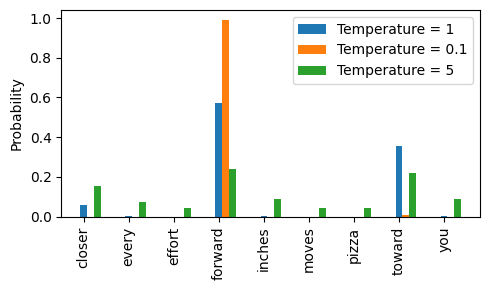

In [ ]:
temperatures = [1, 0.1, 5]  # Original, lower, and higher confidence
scaled_probas = [softmax_with_temperature(next_token_logits, T)
                for T in temperatures]
x = torch.arange(len(vocab))
bar_width = 0.15
fig, ax = plt.subplots(figsize=(5, 3))

for i, T in enumerate(temperatures):
  rects = ax.bar(x + i * bar_width, scaled_probas[i],
                 bar_width, label=f'Temperature = {T}')
ax.set_ylabel('Probability')
ax.set_xticks(x)
ax.set_xticklabels(vocab.keys(), rotation=90)
ax.legend()

plt.tight_layout()
plt.show()

**In the above charts -**

*--> A temperature of 1 represents the unscaled probability
scores for each token in the vocabulary. Decreasing the temperature to
0.1 sharpens the distribution, so the most likely token (here, “forward”)
will have an even higher probability score.*

*--> Applying very small temperatures will result in the behaviour of multinomial function similar to the argmax function.*

*--> Likewise, increasing the
temperature to 5 makes the distribution more uniform*

### **b. Top-k sampling**

*--> Top-k sampling, when combined with probabilistic sampling
and temperature scaling, can improve the text generation
results.*

*--> In top-k sampling, we can restrict the sampled
tokens to the top-k most likely tokens and exclude all other
tokens from the selection process by masking their
probability scores.*

*--> Using top-k sampling with k = 3, we focus on the three
tokens associated with the highest logits and mask out all other tokens
with negative infinity (–inf) before applying the softmax function.*

*--> This
results in a probability distribution with a probability value 0 assigned to
all non-top-k tokens.*

In [ ]:
top_k = 3
top_logits, top_pos = torch.topk(next_token_logits, top_k)
print("Top logits:", top_logits)
print("Top positions:", top_pos)

Top logits: tensor([6.7500, 6.2800, 4.5100])
Top positions: tensor([3, 7, 0])


**In the above code-**

*-> torch.topk gives you 2 things -*

1. top_logits → the values of the largest logits

2. top_pos → the indices (token IDs) of those logits in the original vector.

**Due to top-k sampling-**

* Softmax is applied only over the top-k tokens

* Sampling happens within that restricted set

* The chosen index is mapped back to the original vocabulary

*--> Temperature controls confidence ,top-k controls choice set size.*

*--> Both together controls quality + diversity.*

**In the below code -**

* We apply PyTorch’s where function to set the logit values of tokens that are below the lowest logit value within our top-three selection to negative infinity (-inf):

In [ ]:
new_logits = torch.where(
    condition=next_token_logits < top_logits[-1],
    input=torch.tensor(float('-inf')),
    other=next_token_logits
)
print(new_logits)

tensor([4.5100,   -inf,   -inf, 6.7500,   -inf,   -inf,   -inf, 6.2800,   -inf])


**In the below code -**

*We apply the softmax function to turn these into next
token probabilities:*


In [ ]:
topk_probas = torch.softmax(new_logits, dim=0)
print(topk_probas)

tensor([0.0615, 0.0000, 0.0000, 0.5775, 0.0000, 0.0000, 0.0000, 0.3610, 0.0000])


### **c. Modifying the text generation function**

 #### **c.1 A modified text generation function with more diversity**

In [ ]:
def generate(model, idx, max_new_tokens, context_size,
             temperature=0.0, top_k=None, eos_id=None):
    for _ in range(max_new_tokens):       #same for loop to get logits and only focus on last time step.
        idx_cond = idx[:, -context_size:]
        with torch.no_grad():
            logits = model(idx_cond)
        logits = logits[:, -1, :]
        if top_k is not None:  # filter logits bais top-k
            top_logits, _ = torch.topk(logits, top_k)
            min_val = top_logits[:, -1]
            logits = torch.where(
                logits < min_val,
                torch.tensor(float('-inf')).to(logits.device),
                logits
            )
        if temperature > 0.0:     #temperature scaling
            logits = logits / temperature
            probs = torch.softmax(logits, dim=-1)
            idx_next = torch.multinomial(probs, num_samples=1)
        else:    #greedy next token selection as before when temp scaling is disabled.
            idx_next = torch.argmax(logits, dim=-1, keepdim=True)
        if idx_next == eos_id:   #Stops generating early if end-of-sequence token is encountered
            break
        idx = torch.cat((idx, idx_next), dim=1)
    return idx

**In the above code-**

--> Function Generates text autoregressively with controllable diversity

**It has -**


✅ Greedy decoding

✅ Temperature sampling

✅ Top-k sampling

✅ Early stopping via EOS

This is exactly how real LLM inference works.

**In the below code-**

*Lets now see this new generate function in action-*

In [ ]:
torch.manual_seed(123)
token_ids = generate(
    model=model,
    idx=text_to_token_ids("Every effort moves you", tokenizer),
    max_new_tokens=15,
    context_size=GPT_CONFIG_124M["context_length"],
    top_k=25,
    temperature=1.4
)
print("Output text:\n", token_ids_to_text(token_ids, tokenizer))

Output text:
 Every effort moves youlit terrace.



" he said deprecating laugh


**Output of above is -**  

Output text:

Every effort moves you stand to work on surprise, a one of us had gone with random-

In [ ]:
breakk;;;

SyntaxError: invalid syntax (ipython-input-1277478617.py, line 1)

## **iv. Loading and saving model weights in PyTorch.**

*--> Pretraining LLMs is computationally
expensive.*

*--> Thus, it is important to be able to save the LLM
so that we don’t have to rerun the training every time we
want to use it in a new session.*

In [ ]:
torch.save(model.state_dict(), "model.pth")

**In the above code-**

*Saving a PyTorch model is relatively
straightforward. The recommended way is to save a model’s
state_dict, a dictionary mapping each layer to its
parameters, using the torch.save function.*

*"model.pth" is the filename where the state_dict is saved. The
.pth extension is a convention for PyTorch files, though we
could technically use any file extension.*

**In the below code-**

*After saving the model weights via the state_dict, we can load the model weights into a new GPTModel model instance.*

In [ ]:
model = GPTModel(GPT_CONFIG_124M)
model.load_state_dict(torch.load("model.pth", map_location=device))

* Dropout helps prevent the model
from overfitting to the training data by randomly “dropping
out” of a layer’s neurons during training.

* However, during
inference, we don’t want to randomly drop out any of the
information the network has learned.

* Using model.eval()
switches the model to evaluation mode for inference,
disabling the dropout layers of the model.

* If we plan to
continue pretraining a model later—for example, using the
train_model_simple function we defined earlier in this chapter
—saving the optimizer state is also recommended.

**In the below code -**

* Adaptive optimizers such as AdamW store additional
parameters for each model weight. AdamW uses historical
data to adjust learning rates for each model parameter
dynamically.

* Without it, the optimizer resets, and the model
may learn suboptimally or even fail to converge properly,
which means it will lose the ability to generate coherent text.

* Using torch.save, we can save both the model and optimizer
state_dict contents.

In [ ]:
# run the below code if you are doing from scratch and need to save the model
""" torch.save({
    "model_state_dict": model.state_dict(),
    "optimizer_state_dict": optimizer.state_dict(),
    },
    "model_and_optimizer.pth"
)

MODEL_PATH = "/content/drive/MyDrive/Colab Notebooks/model_and_optimizer.pth"
checkpoint = torch.load(MODEL_PATH, map_location=device)
model = GPTModel(GPT_CONFIG_124M)
model.load_state_dict(checkpoint["model_and_optimizer.pth"])
optimizer = torch.optim.AdamW(model.parameters(), lr=5e-4, weight_decay=0.1)
optimizer.load_state_dict(checkpoint["optimizer_state_dict"])
model.train();

*--> We can restore the model and optimizer states by first
loading the saved data via torch.load and then using the
load_state_dict method.*

In [ ]:
# run this code if you want to load the file and move forward

MODEL_PATH = "/content/drive/MyDrive/Colab Notebooks/model_and_optimizer.pth"
# Load the checkpoint file
checkpoint = torch.load(MODEL_PATH, map_location=device)
#Recreate the model
model = GPTModel(GPT_CONFIG_124M)
model.to(device)
# Load model weights
model.load_state_dict(checkpoint["model_state_dict"])
#Recreate optimizer
optimizer = torch.optim.AdamW(model.parameters(), lr=5e-4, weight_decay=0.1)
# Load optimizer state
optimizer.load_state_dict(checkpoint["optimizer_state_dict"])
# Set training mode if you want to continue training
model.train();

## **v. Loading pretrained weights from OpenAI**

In [ ]:
import urllib.request
url = (
    "https://raw.githubusercontent.com/rasbt/"
    "LLMs-from-scratch/main/ch05/"
    "01_main-chapter-code/gpt_download.py"
)
filename = url.split('/')[-1]
urllib.request.urlretrieve(url, filename)

('gpt_download.py', <http.client.HTTPMessage at 0x7c977192e900>)

**In the below code -**

-> Import the download_and_load_gpt2 function from
the gpt_download .py file as follows, which will load the GPT-2
architecture settings (settings) and weight parameters
(params) into our Python session.

In [ ]:
from gpt_download import download_and_load_gpt2
settings, params = download_and_load_gpt2(
    model_size="124M", models_dir="gpt2"
)

checkpoint: 100%|██████████| 77.0/77.0 [00:00<00:00, 122kiB/s]
encoder.json: 100%|██████████| 1.04M/1.04M [00:00<00:00, 2.72MiB/s]
hparams.json: 100%|██████████| 90.0/90.0 [00:00<00:00, 225kiB/s]
model.ckpt.data-00000-of-00001: 100%|██████████| 498M/498M [01:21<00:00, 6.13MiB/s]
model.ckpt.index: 100%|██████████| 5.21k/5.21k [00:00<00:00, 8.60MiB/s]
model.ckpt.meta: 100%|██████████| 471k/471k [00:00<00:00, 1.67MiB/s]
vocab.bpe: 100%|██████████| 456k/456k [00:00<00:00, 1.55MiB/s]


In [ ]:
print("Settings:", settings)
print("Parameter dictionary keys:", params.keys())

Settings: {'n_vocab': 50257, 'n_ctx': 1024, 'n_embd': 768, 'n_head': 12, 'n_layer': 12}
Parameter dictionary keys: dict_keys(['blocks', 'b', 'g', 'wpe', 'wte'])


*--> Both settings and params are Python dictionaries. The settings
dictionary stores the LLM architecture settings similarly to
our manually defined GPT_CONFIG_124M settings.*

*--> The params
dictionary contains the actual weight tensors. Note that we only printed the dictionary keys because printing the weight
contents would take up too much screen space.*

*--> However, we can inspect these weight tensors by printing the whole dictionary via print(params) or by selecting individual tensors
via the respective dictionary keys, for example, the
embedding layer weights.*

In [ ]:
print(params["wte"])
print("Token embedding weight tensor dimensions:", params["wte"].shape)

[[-0.11010301 -0.03926672  0.03310751 ... -0.1363697   0.01506208
   0.04531523]
 [ 0.04034033 -0.04861503  0.04624869 ...  0.08605453  0.00253983
   0.04318958]
 [-0.12746179  0.04793796  0.18410145 ...  0.08991534 -0.12972379
  -0.08785918]
 ...
 [-0.04453601 -0.05483596  0.01225674 ...  0.10435229  0.09783269
  -0.06952604]
 [ 0.1860082   0.01665728  0.04611587 ... -0.09625227  0.07847701
  -0.02245961]
 [ 0.05135201 -0.02768905  0.0499369  ...  0.00704835  0.15519823
   0.12067825]]
Token embedding weight tensor dimensions: (50257, 768)


*--> We downloaded and loaded the weights of the smallest GPT
2 model via the download_ and_load_gpt2(model_size="124M", ...)
setting.*

*--> OpenAI also shares the weights of larger models:
355M, 774M,& 1558M. The overall architecture of these differently sized GPT models is the same, except that different architectural elements are
repeated different numbers of times and the embedding size differs.*

*--> GPT-2 LLMs come in several different model sizes, ranging
from 124 million to 1,558 million parameters.*

*--> The core architecture is the same, with the only difference being the embedding sizes and the
number of times individual components like the attention heads and
transformer blocks are repeated.*

*--> After loading the GPT-2 model weights into Python, we still
need to transfer them from the settings and params
dictionaries into our GPTModel instance. First, we create a
dictionary that lists the differences between the different
GPT model sizes.*

In [ ]:
model_configs = {
    "gpt2-small (124M)": {"emb_dim": 768, "n_layers": 12, "n_heads": 12},
    "gpt2-medium (355M)": {"emb_dim": 1024, "n_layers": 24, "n_heads": 16},
    "gpt2-large (774M)": {"emb_dim": 1280, "n_layers": 36, "n_heads": 20},
    "gpt2-xl (1558M)": {"emb_dim": 1600, "n_layers": 48, "n_heads": 25},
}

*--> Suppose we are interested in loading the smallest model,
"gpt2-small (124M)". We can use the corresponding settings
from the model_configs table to update our full-length
GPT_CONFIG_124M we defined and used earlier:*

In [ ]:
model_name = "gpt2-small (124M)"
NEW_CONFIG = GPT_CONFIG_124M.copy()
NEW_CONFIG.update(model_configs[model_name])

*--> We used a 256-token
length earlier, but the original GPT-2 models from OpenAI were trained with a 1,024-token length,so we have to update the NEW_CONFIG accordingly:*

In [ ]:
NEW_CONFIG.update({"context_length": 1024})

*--> OpenAI used bias vectors in the multi-head attention
module’s linear layers to implement the query, key, and
value matrix computations.*

*--> Bias vectors are not commonly
used in LLMs anymore as they don’t improve the modeling
performance and are thus unnecessary. However, since we are working with pretrained weights, we need to match the
settings for consistency and enable these bias vectors:*


In [ ]:
NEW_CONFIG.update({"qkv_bias": True})

*--> We can now use the updated NEW_CONFIG dictionary to initialize
a new GPTModel instance:*

In [ ]:
gpt = GPTModel(NEW_CONFIG)
gpt.eval()

GPTModel(
  (tok_emb): Embedding(50257, 768)
  (pos_emb): Embedding(1024, 768)
  (drop_emb): Dropout(p=0.1, inplace=False)
  (trf_blocks): Sequential(
    (0): TransformerBlock(
      (att): MultiHeadAttention(
        (W_query): Linear(in_features=768, out_features=768, bias=True)
        (W_key): Linear(in_features=768, out_features=768, bias=True)
        (W_value): Linear(in_features=768, out_features=768, bias=True)
        (out_proj): Linear(in_features=768, out_features=768, bias=True)
        (dropout): Dropout(p=0.1, inplace=False)
      )
      (ff): FeedForward(
        (layers): Sequential(
          (0): Linear(in_features=768, out_features=3072, bias=True)
          (1): GELU()
          (2): Linear(in_features=3072, out_features=768, bias=True)
        )
      )
      (norm1): LayerNorm()
      (norm2): LayerNorm()
      (drop_shortcut): Dropout(p=0.1, inplace=False)
    )
    (1): TransformerBlock(
      (att): MultiHeadAttention(
        (W_query): Linear(in_features=7

*--> By default, the GPTModel instance is initialized with random
weights for pretraining.*

*--> The last step to using OpenAI’s
model weights is to override these random weights with the
weights we loaded into the params dictionary.*

*--> For this, we will
first define a small assign utility function that checks whether
two tensors or arrays (left and right) have the same
dimensions or shape and returns the right tensor as
trainable PyTorch parameters:*

In [ ]:
def assign(left, right):
  if left.shape != right.shape:
    raise ValueError(f"Shape mismatch. Left: {left.shape}, "
    "Right: {right.shape}"
    )
  return torch.nn.Parameter(torch.tensor(right))

*--> Next, we define a load_weights_into_gpt function that loads
the weights from the params dictionary into a GPTModel
instance gpt.*

#### **v.1  Loading OpenAI weights into our GPT model code**

In [ ]:
import numpy as np
def load_weights_into_gpt(gpt, params):           #1
    gpt.pos_emb.weight = assign(gpt.pos_emb.weight, params['wpe'])
    gpt.tok_emb.weight = assign(gpt.tok_emb.weight, params['wte'])
    for b in range(len(params["blocks"])):     #2
        q_w, k_w, v_w = np.split(                            #3
            (params["blocks"][b]["attn"]["c_attn"])["w"], 3, axis=-1)
        gpt.trf_blocks[b].att.W_query.weight = assign(
            gpt.trf_blocks[b].att.W_query.weight, q_w.T)
        gpt.trf_blocks[b].att.W_key.weight = assign(
            gpt.trf_blocks[b].att.W_key.weight, k_w.T)
        gpt.trf_blocks[b].att.W_value.weight = assign(
            gpt.trf_blocks[b].att.W_value.weight, v_w.T)
        q_b, k_b, v_b = np.split(
            (params["blocks"][b]["attn"]["c_attn"])["b"], 3, axis=-1)
        gpt.trf_blocks[b].att.W_query.bias = assign(
            gpt.trf_blocks[b].att.W_query.bias, q_b)
        gpt.trf_blocks[b].att.W_key.bias = assign(
            gpt.trf_blocks[b].att.W_key.bias, k_b)
        gpt.trf_blocks[b].att.W_value.bias = assign(
            gpt.trf_blocks[b].att.W_value.bias, v_b)
        gpt.trf_blocks[b].att.out_proj.weight = assign(
            gpt.trf_blocks[b].att.out_proj.weight,
            params["blocks"][b]["attn"]["c_proj"]["w"].T)
        gpt.trf_blocks[b].att.out_proj.bias = assign(
            gpt.trf_blocks[b].att.out_proj.bias,
            params["blocks"][b]["attn"]["c_proj"]["b"])
        gpt.trf_blocks[b].ff.layers[0].weight = assign(
            gpt.trf_blocks[b].ff.layers[0].weight,
            params["blocks"][b]["mlp"]["c_fc"]["w"].T)
        gpt.trf_blocks[b].ff.layers[0].bias = assign(
            gpt.trf_blocks[b].ff.layers[0].bias,
            params["blocks"][b]["mlp"]["c_fc"]["b"])
        gpt.trf_blocks[b].ff.layers[2].weight = assign(
            gpt.trf_blocks[b].ff.layers[2].weight,
            params["blocks"][b]["mlp"]["c_proj"]["w"].T)
        gpt.trf_blocks[b].ff.layers[2].bias = assign(
            gpt.trf_blocks[b].ff.layers[2].bias,
            params["blocks"][b]["mlp"]["c_proj"]["b"])
        gpt.trf_blocks[b].norm1.scale = assign(
            gpt.trf_blocks[b].norm1.scale,
            params["blocks"][b]["ln_1"]["g"])
        gpt.trf_blocks[b].norm1.shift = assign(
            gpt.trf_blocks[b].norm1.shift,
            params["blocks"][b]["ln_1"]["b"])
        gpt.trf_blocks[b].norm2.scale = assign(
            gpt.trf_blocks[b].norm2.scale,
            params["blocks"][b]["ln_2"]["g"])
        gpt.trf_blocks[b].norm2.shift = assign(
            gpt.trf_blocks[b].norm2.shift,
            params["blocks"][b]["ln_2"]["b"])
    gpt.final_norm.scale = assign(gpt.final_norm.scale, params["g"])
    gpt.final_norm.shift = assign(gpt.final_norm.shift, params["b"])
    gpt.out_head.weight = assign(gpt.out_head.weight, params["wte"])

**In the above code-**

*1. Sets the model’s positional and token embedding weights to those
specified in params.*

*2. Iterates over each transformer block in the model.*

*3. The np.split function is used to divide the attention and bias weights
into three equal parts for the query, key, and value components.*

*4. The original GPT-2 model by OpenAI reused the token embedding
weights in the output layer to reduce the total number of parameters,
which is a concept known as weight tying.*

**In the below code -**

*--> In the load_weights_into_gpt function, we carefully match the
weights from OpenAI’s implementation with our GPTModel
implementation.*

*--> To pick a specific example, OpenAI stored
the weight tensor for the output projection layer for the first
transformer block as params["blocks"][0]["attn"]["c_proj"]
["w"].*

*--> In our implementation, this weight tensor corresponds
to gpt.trf_blocks[b].att.out_proj .weight, where gpt is a
GPTModel instance.*

In [ ]:
load_weights_into_gpt(gpt, params)
gpt.to(device)

GPTModel(
  (tok_emb): Embedding(50257, 768)
  (pos_emb): Embedding(1024, 768)
  (drop_emb): Dropout(p=0.1, inplace=False)
  (trf_blocks): Sequential(
    (0): TransformerBlock(
      (att): MultiHeadAttention(
        (W_query): Linear(in_features=768, out_features=768, bias=True)
        (W_key): Linear(in_features=768, out_features=768, bias=True)
        (W_value): Linear(in_features=768, out_features=768, bias=True)
        (out_proj): Linear(in_features=768, out_features=768, bias=True)
        (dropout): Dropout(p=0.1, inplace=False)
      )
      (ff): FeedForward(
        (layers): Sequential(
          (0): Linear(in_features=768, out_features=3072, bias=True)
          (1): GELU()
          (2): Linear(in_features=3072, out_features=768, bias=True)
        )
      )
      (norm1): LayerNorm()
      (norm2): LayerNorm()
      (drop_shortcut): Dropout(p=0.1, inplace=False)
    )
    (1): TransformerBlock(
      (att): MultiHeadAttention(
        (W_query): Linear(in_features=7

**In the below code -**

*--> If the model is loaded correctly, we can now use it to generate new text using our previous generate function.*


In [ ]:
torch.manual_seed(123)
token_ids = generate(
    model=gpt,
    idx=text_to_token_ids("Every effort moves you", tokenizer).to(device),
    max_new_tokens=25,
    context_size=NEW_CONFIG["context_length"],
    top_k=50,
    temperature=1.5
)
print("Output text:\n", token_ids_to_text(token_ids, tokenizer))

Output text:
 Every effort moves you toward finding an ideal new way to practice something!

What makes us want to be on top of that?




**We can be confident that we loaded the model weights
correctly because the model can produce coherent text. A
tiny mistake in this process would cause the model to fail.**

In [ ]:
breakk

# **5.FINE TUNING ON CLASSIFICATION**

**The below chapter will cover -**

* Introducing different LLM fine-tuning approaches

* Preparing a dataset for text classification

* Modifying a pretrained LLM for fine-tuning

* Fine-tuning an LLM to identify spam messages

* Evaluating the accuracy of a fine-tuned LLM classifier

* Using a fine-tuned LLM to classify new data

## **i. Different categories of fine-tuning**

*--> Most common ways to fine-tune language models are instruction fine-tuning and classification fine-tuning.*

*--> **Instruction fine-tuning** involves training a language model on
a set of tasks using specific instructions to improve its ability
to understand and execute tasks described in natural
language prompts.*

*--> In **classification fine-tuning**, a concept you might already be
acquainted with if you have a background in machine
learning, the model is trained to recognize a specific set of
class labels, such as “spam” and “not spam.”*

*--> The key point is that a classification fine-tuned model is
restricted to predicting classes it has encountered during its
training. For instance, it can determine whether something is
“spam” or “not spam,”*

## **ii. Preparing the dataset**

The **three-stage** process for classification fine-tuning an LLM.

**Stage 1 - Dataset preparation**

1. Download the dataset

2. Preprocess dataset

3. Create data loaders

**Stage 2 - Model setup**

4. Initialize model

5. Load pretrained weights

6. Modify model for fine tuning

7. Implement evaluation utilities

**Stage 3 - Model fine-tuning and usage**

8. Fine-tune model

9. Evaluate fine-tuned model

10. Use model on new data

#### **ii.1 Downloading and unzipping the dataset**

In [ ]:
import urllib.request
import zipfile
import os
from pathlib import Path
url = "https://archive.ics.uci.edu/static/public/228/sms+spam+collection.zip"
zip_path = "sms_spam_collection.zip"
extracted_path = "sms_spam_collection"
data_file_path = Path(extracted_path) / "SMSSpamCollection.tsv"
def download_and_unzip_spam_data(
        url, zip_path, extracted_path, data_file_path):
    if data_file_path.exists():
        print(f"{data_file_path} already exists. Skipping download "
              "and extraction."
        )
        return
    with urllib.request.urlopen(url) as response:    #1
        with open(zip_path, "wb") as out_file:
            out_file.write(response.read())
    with zipfile.ZipFile(zip_path, "r") as zip_ref:    #2
        zip_ref.extractall(extracted_path)
    original_file_path = Path(extracted_path) / "SMSSpamCollection"
    os.rename(original_file_path, data_file_path)               #3
    print(f"File downloaded and saved as {data_file_path}")
download_and_unzip_spam_data(url, zip_path, extracted_path, data_file_path)

File downloaded and saved as sms_spam_collection/SMSSpamCollection.tsv


In [ ]:
import pandas as pd
df = pd.read_csv(
    data_file_path, sep="\t", header=None, names=["Label", "Text"]
)
df      #1

,Label,Text
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."
...,...,...
5567,spam,This is the 2nd time we have tried 2 contact u...
5568,ham,Will ü b going to esplanade fr home?
5569,ham,"Pity, * was in mood for that. So...any other s..."
5570,ham,The guy did some bitching but I acted like i'd...


In [ ]:
print(df["Label"].value_counts())

Label
ham     4825
spam     747
Name: count, dtype: int64


#### **ii.2 Creating a balanced dataset**

In [ ]:
def create_balanced_dataset(df):
  num_spam = df[df["Label"] == "spam"].shape[0] #  Counts the instances of “spam”
  ham_subset = df[df["Label"] == "ham"].sample(
      num_spam, random_state=123
      )

  balanced_df = pd.concat([
      ham_subset, df[df["Label"] == "spam"]
      ])
  return balanced_df

balanced_df = create_balanced_dataset(df)
print(balanced_df["Label"].value_counts())

Label
ham     747
spam    747
Name: count, dtype: int64


**In the above code -**

*--> Create a balanced dataset with similar number of samples for both the classes.*

*--> Prevents the model from being biased toward ham.*

*--> Forces equal gradient contribution from spam & ham*

*--> Makes learning spam patterns unavoidable*

**What you are trading off**

**Benefit - >  - >  Cost**

1.Fair learning	 - > Lose 4,000+ ham samples

2.Better recall	Less exposure to ham diversity

3.Cleaner loss curves	Slightly less real-world realism

**This is fine for learning, prototyping, and baselines.**

**In the below code -**

*-> We convert the “string” class labels "ham" and "spam"
into integer class labels 0 and 1, respectively:*

In [ ]:
balanced_df["Label"] = balanced_df["Label"].map({"ham": 0, "spam": 1})

#### **ii.3 Splitting the dataset**

**In the below code -**

*-->  We create a random_split function to split the dataset
into three parts: 70% for training, 10% for validation, and
20% for testing.*

In [ ]:
def random_split(df, train_frac, validation_frac):

  df = df.sample(
      frac=1, random_state=123
      ).reset_index(drop=True) #Shuffles the entire DataFrame

  train_end = int(len(df) * train_frac) #Calculates split indices
  validation_end = train_end + int(len(df) * validation_frac)
 #  Splits the DataFrame

  train_df = df[:train_end]
  validation_df = df[train_end:validation_end]
  test_df = df[validation_end:]

  return train_df, validation_df, test_df

train_df, validation_df, test_df = random_split(
    balanced_df, 0.7, 0.1) # Test size is implied to be 0.2 as the remainder.

**In the below code -**

*--> Let’s save the dataset as CSV (comma-separated value) files
so we can reuse it later:*

In [ ]:
train_df.to_csv("train.csv", index=None)
validation_df.to_csv("validation.csv", index=None)
test_df.to_csv("test.csv", index=None)

## **iii. Creating data loaders**

**In this section -**

*--> We will develop PyTorch data loaders conceptually similar to
those we implemented while working with text data.*

*--> Previously, we utilized a sliding window technique to
generate uniformly sized text chunks, which we then
grouped into batches for more efficient model training.Each
chunk functioned as an individual training instance.*

*--> However,
we are now working with a spam dataset that contains text
messages of varying lengths. To batch these messages as
we did with the text chunks, we will pad all messages to the length of the longest message in the dataset or
batch.*

*--> And for that , we add padding tokens to all shorter messages. For this purpose, we
use "<|endoftext|>" as a padding token.
However, instead of appending the string "<|endoftext|>" to
each of the text messages directly, we can add the token ID
corresponding to "<|endoftext|>" to the encoded text
messages.*

**In the below code -**

*--> 50256 is the token ID
of the padding token "<|endoftext|>". We can double-check
whether the token ID is correct by encoding the "
<|endoftext|>" using the GPT-2 tokenizer from the tiktoken
package.*

In [ ]:
import tiktoken
tokenizer = tiktoken.get_encoding("gpt2")
print(tokenizer.encode("<|endoftext|>", allowed_special={"<|endoftext|>"}))

[50256]


In [ ]:
import torch
from torch.utils.data import Dataset
class SpamDataset(Dataset):
    def __init__(self, csv_file, tokenizer, max_length=None,
                 pad_token_id=50256):
        self.data = pd.read_csv(csv_file) # Pretokenizes texts

        self.encoded_texts = [
            tokenizer.encode(text) for text in self.data["Text"]
        ]

        if max_length is None:
            self.max_length = self._longest_encoded_length()

        else:
            self.max_length = max_length #Truncates sequences if they are longer than max_length
            self.encoded_texts = [
                encoded_text[:self.max_length]
                for encoded_text in self.encoded_texts
            ]   # Pads sequences to the longest sequence

        self.encoded_texts = [
            encoded_text + [pad_token_id] *
            (self.max_length - len(encoded_text))
            for encoded_text in self.encoded_texts
        ]

    def __getitem__(self, index):
        encoded = self.encoded_texts[index]
        label = self.data.iloc[index]["Label"]
        return (
            torch.tensor(encoded, dtype=torch.long),
            torch.tensor(label, dtype=torch.long)
        )

    def __len__(self):
        return len(self.data)

    def _longest_encoded_length(self): # this is used for max_length
        max_length = 0
        for encoded_text in self.encoded_texts:
            encoded_length = len(encoded_text)
            if encoded_length > max_length:
                max_length = encoded_length
        return max_length

**In the above code-**

*--> SpamDataset class handles several key tasks:*

* *This class loads data from the CSV files we
created earlier, tokenizes the text using the GPT-2 tokenizer
from tiktoken.*

* *It identifies the longest sequence in the training dataset*

* *Encodes the text messages*

* *Ensures that all other sequences are padded with a padding token to match the length of the longest sequence.*

*--> This
ensures each input tensor is of the same size, which is
necessary to create the batches in the training data loader*

*--> The above dataset is like - **It will return the tensors the model understands for the given index**.*

In [ ]:
train_dataset = SpamDataset(
    csv_file="train.csv",
    max_length=None,
    tokenizer=tokenizer
    )

*--> The above code executes all what we have prepared above .*

*--> It loads the training CSV, tokenizes every SMS, finds the longest message, pads all messages to that length, and stores everything as tensors ready for batching.*

**In the below code -**

*--> The longest sequence length is stored in the dataset’s
max_length attribute.*

In [ ]:
print(train_dataset.max_length)

120


*--> Also you remember,there was some relation between max_length and context length coded in the previous chapters.*

*--> The model can handle sequences of up to 1,024
tokens, given its context length limit. If your dataset
includes longer texts, you can pass max_length=1024 when
creating the training dataset in the preceding code to ensure
that the data does not exceed the model’s supported input
(context) length.*

In [ ]:
val_dataset = SpamDataset(
    csv_file="validation.csv",
    max_length=train_dataset.max_length,
    tokenizer=tokenizer
    )

test_dataset = SpamDataset(
    csv_file="test.csv",
    max_length=train_dataset.max_length,
    tokenizer=tokenizer
    )

**In the above code-**

*--> We pad the validation and test sets to match the
length of the longest training sequence.*

*--> Importantly, any
validation and test set samples exceeding the length of the
longest training example are truncated using
encoded_text[:self.max_length] in the SpamDataset code we
defined earlier.*

*--> This truncation is optional; you can set
max_length=None for both validation and test sets, provided there are no sequences exceeding 1,024 tokens in these
sets.*


#### **iii.1  Creating PyTorch data loaders**

In [ ]:
from torch.utils.data import DataLoader
num_workers = 0      #1
batch_size = 8
torch.manual_seed(123)

train_loader = DataLoader(
    dataset=train_dataset,
    batch_size=batch_size,
    shuffle=True,
    num_workers=num_workers,
    drop_last=True,
)
val_loader = DataLoader(
    dataset=val_dataset,
    batch_size=batch_size,
    num_workers=num_workers,
    drop_last=False,
)
test_loader = DataLoader(
    dataset=test_dataset,
    batch_size=batch_size,
    num_workers=num_workers,
    drop_last=False,
)

**Reiterating -**

*--> DataLoader turns your Dataset into mini-batches of tensors, handling shuffling, batching, and iteration during training.*

*--> Dataset defines what one sample looks like.
DataLoader defines how samples flow into training.*

**In the below code -**

*--> To ensure that the data loaders are working and are, indeed,
returning batches of the expected size, we iterate over the
training loader and then print the tensor dimensions of the
last batch.*

In [ ]:
for input_batch, target_batch in train_loader:
    pass

print("Input batch dimensions:", input_batch.shape)
print("Label batch dimensions", target_batch.shape)

Input batch dimensions: torch.Size([8, 120])
Label batch dimensions torch.Size([8])


**In the above output -**

*--> The input batches consist of eight training
examples with 120 tokens each per batch, as expected , i.e. 8 sms with 120 tokens each have been grouped together.(Remember we trimmed the max length upto 120 only above).*

*--> There is only 1 label per SMS , ham or spam.*

*--> The label
tensor stores the class labels corresponding to the eight
training examples.*

*--> The dataset (for eg. train.csv) which contained 2 columns , sms and label, gets divided into 2 different batches through dataloader , **input_batch** containing the sms only , and **target_batch** containing the label only.*

*--> Basically , dataloader gives outputs(here , input_batch and target_batch) , based how many tuples are there in each batch, here it had 2 , sms and the labels.*

In [ ]:
print(f"{len(train_loader)} training batches")
print(f"{len(val_loader)} validation batches")
print(f"{len(test_loader)} test batches")

130 training batches
19 validation batches
38 test batches


**In the above code -**

*--> We get an idea of the dataset size with total number of batches in each.*

## **iv. Initializing a model with pretrained weights**

*--> Now we are at the stage 2(Model set up) of Classification fine tuning.*

*--> We will be starting with initializing the model*

**In the below code-**

*--> To begin the model preparation process, we employ the
same configurations we used to pretrain unlabeled data:*


In [ ]:
CHOOSE_MODEL = "gpt2-small (124M)"
INPUT_PROMPT = "Every effort moves"
BASE_CONFIG = {
    "vocab_size": 50257,
    "context_length": 1024,
    "drop_rate": 0.0,
    "qkv_bias": True
    }

model_configs = {
    "gpt2-small (124M)": {"emb_dim": 768, "n_layers": 12, "n_heads": 12},
    "gpt2-medium (355M)": {"emb_dim": 1024, "n_layers": 24, "n_heads": 16},
    "gpt2-large (774M)": {"emb_dim": 1280, "n_layers": 36, "n_heads": 20},
    "gpt2-xl (1558M)": {"emb_dim": 1600, "n_layers": 48, "n_heads": 25},
}
BASE_CONFIG.update(model_configs[CHOOSE_MODEL])

*--> **Strict rule** - Tokenizer vocab size must EXACTLY match model vocab size (in this case it is 50257).*

*--> Dropout = 0 -> GPT-2 original training used no dropout. Also , Small datasets + dropout can destabilize learning*



**emb_dim = 768**

* Size of token embeddings.
* Also the hidden size everywhere in the model.

Every token becomes a 768-dimensional vector.

**n_layers = 12**

* Number of transformer blocks
* Each block = attention + MLP + residuals

Depth = how many times information is refined.

**n_heads = 12**

* Multi-head attention
* Each head dimension: 768 / 12 = 64 ,which is s standard head size.




**BASE_CONFIG is the DNA of your model.
Everything else (weights, loss, outputs) grows from it.**

In [ ]:
from gpt_download import download_and_load_gpt2
# from chapter05 import GPTModel, load_weights_into_gpt

model_size = CHOOSE_MODEL.split(" ")[-1].lstrip("(").rstrip(")")
settings, params = download_and_load_gpt2(
    model_size=model_size, models_dir="gpt2"
    )
model = GPTModel(BASE_CONFIG)
load_weights_into_gpt(model, params)
model.eval()

File already exists and is up-to-date: gpt2/124M/checkpoint
File already exists and is up-to-date: gpt2/124M/encoder.json
File already exists and is up-to-date: gpt2/124M/hparams.json
File already exists and is up-to-date: gpt2/124M/model.ckpt.data-00000-of-00001
File already exists and is up-to-date: gpt2/124M/model.ckpt.index
File already exists and is up-to-date: gpt2/124M/model.ckpt.meta
File already exists and is up-to-date: gpt2/124M/vocab.bpe


GPTModel(
  (tok_emb): Embedding(50257, 768)
  (pos_emb): Embedding(1024, 768)
  (drop_emb): Dropout(p=0.0, inplace=False)
  (trf_blocks): Sequential(
    (0): TransformerBlock(
      (att): MultiHeadAttention(
        (W_query): Linear(in_features=768, out_features=768, bias=True)
        (W_key): Linear(in_features=768, out_features=768, bias=True)
        (W_value): Linear(in_features=768, out_features=768, bias=True)
        (out_proj): Linear(in_features=768, out_features=768, bias=True)
        (dropout): Dropout(p=0.0, inplace=False)
      )
      (ff): FeedForward(
        (layers): Sequential(
          (0): Linear(in_features=768, out_features=3072, bias=True)
          (1): GELU()
          (2): Linear(in_features=3072, out_features=768, bias=True)
        )
      )
      (norm1): LayerNorm()
      (norm2): LayerNorm()
      (drop_shortcut): Dropout(p=0.0, inplace=False)
    )
    (1): TransformerBlock(
      (att): MultiHeadAttention(
        (W_query): Linear(in_features=7

**In the above code-**

*--> We import the download_and_load_gpt2 function from the
gpt_download.py file and reuse the GPTModel class which was defined in Chapter 3 or 4 and
load_weights_into_gpt function from pretraining (see chapter
5) to load the downloaded weights into the GPT model.*

**In the below code-**

*--> After loading the model weights into the GPTModel, we reuse
the text generation utility function from chapters 4 and 5 to
ensure that the model generates coherent text.*


In [ ]:
breakk

NameError: name 'breakk' is not defined

In [ ]:
#from chapter04 import generate_text_simple
#from chapter05 import text_to_token_ids, token_ids_to_text
text_1 = "Every effort moves you"
token_ids = generate_text_simple(
    model=model,
    idx=text_to_token_ids(text_1, tokenizer),
    max_new_tokens=15,
    context_size=BASE_CONFIG["context_length"]
)
print(token_ids_to_text(token_ids, tokenizer))

Every effort moves you forward.

The first step is to understand the importance of your work


**In the above output -**

*--> Output shows the model generates coherent
text, which is indicates that the model weights have been
loaded correctly.*

**In the below code-**

*--> Before we start fine-tuning the model as a spam classifier,
let’s see whether the model already classifies spam
messages by prompting it with instructions:*

In [ ]:
text_2 = (
    "Is the following text 'spam'? Answer with 'yes' or 'no':"
    " 'You are a winner you have been specially"
    " selected to receive $1000 cash or a $2000 award.'"
)
token_ids = generate_text_simple(
    model=model,
    idx=text_to_token_ids(text_2, tokenizer),
    max_new_tokens=23,
    context_size=BASE_CONFIG["context_length"]
)
print(token_ids_to_text(token_ids, tokenizer))

Is the following text 'spam'? Answer with 'yes' or 'no': 'You are a winner you have been specially selected to receive $1000 cash or a $2000 award.'

The following text 'spam'? Answer with 'yes' or 'no': 'You are a winner


**Based on the output-**

*--> It’s apparent that the model is
struggling to follow instructions. This result is expected, as it
has only undergone pretraining and lacks instruction fine
tuning.*

## **v.Adding a classification head**

**First - Why we will be fine tuning partially here in the below code-**

1. It depends on the problem we are solving, in this case - Spam classification which has small dataset of 1000 sms,task is binary(spam,ham).

2. Basically , model is "much larger" than the dataset and this thing drives the decision.

3. Before we touch it , GPT-2 already knows english grammer,semantics,tone etc,so it is of no use to train the gpt2 from scratch or fully fine tune all 124m parameters as we would need billions of parameters and dataset is tiny too due to which training will become unstable.

4. Transformers learn in heirarchical way and features like for eg. Early layers(characters,syntax,word shapes), middle layers(meaning, sentence structure),late layers(task-like abstractions).

5. Spam detection depends on intent, tone, manipulation language etc. , which live in the top layers.So we let only the last transformer block adapt and freeze all lower layers(core language knowledge).

6. Last layer sees fully contextualised text,produces more abstract representations and is closest to decision-making.

7. Final layerNorm(model.final_norm) align GPT outputs with the classifier head,controls distribution of representations, strongly affects classifier logits and if frozen,it can block adaptation.

8. We let the last layer adapt while preserving everything below it.

9. Due to this , we would be training only ~5–10M parameters, not 124M.


*--> We must modify the pretrained LLM to prepare it for classification fine-tuning.*

*--> To do so, we replace the original
output layer, which maps the hidden representation to a vocabulary of 50,257, with a smaller output layer that maps to two classes: 0 (“not spam”) and 1 (“spam”).*


In [ ]:
print(model)

GPTModel(
  (tok_emb): Embedding(50257, 768)
  (pos_emb): Embedding(1024, 768)
  (drop_emb): Dropout(p=0.0, inplace=False)
  (trf_blocks): Sequential(
    (0): TransformerBlock(
      (att): MultiHeadAttention(
        (W_query): Linear(in_features=768, out_features=768, bias=True)
        (W_key): Linear(in_features=768, out_features=768, bias=True)
        (W_value): Linear(in_features=768, out_features=768, bias=True)
        (out_proj): Linear(in_features=768, out_features=768, bias=True)
        (dropout): Dropout(p=0.0, inplace=False)
      )
      (ff): FeedForward(
        (layers): Sequential(
          (0): Linear(in_features=768, out_features=3072, bias=True)
          (1): GELU()
          (2): Linear(in_features=3072, out_features=768, bias=True)
        )
      )
      (norm1): LayerNorm()
      (norm2): LayerNorm()
      (drop_shortcut): Dropout(p=0.0, inplace=False)
    )
    (1): TransformerBlock(
      (att): MultiHeadAttention(
        (W_query): Linear(in_features=7

**Based on the output-**

*--> The GPTModel consists of
embedding layers followed by 12 identical transformer
blocks (only the last block is shown for brevity), followed by
a final LayerNorm and the output layer, out_head.*

**In the below code-**

*--> To get the model ready for classification fine-tuning, we first
freeze the entire GPT model, meaning that **"we make all layers
nontrainable"** :*

*--> It means nothing in GPT will update during backprop.*

*--> This is the first explicit trainability decision.*

In [ ]:
for param in model.parameters():
    param.requires_grad = False

#### **v.1 Adding a classification layer**

*--> We replace the output layer (model.out_head), which
originally maps the layer inputs to 50,257 dimensions, the
size of the vocabulary*

*--> This new model.out_head output layer has its requires_grad
attribute set to True by default, which means that it’s the
only layer in the model that will be updated during training.*

*--> Technically, training the output layer we just added is
sufficient. However, as I found in experiments, fine-tuning
additional layers can noticeably improve the predictive
performance of the model.*

In [ ]:
torch.manual_seed(123)
num_classes = 2
model.out_head = torch.nn.Linear(
    in_features=BASE_CONFIG["emb_dim"],
    out_features=num_classes
)

**In the above code-**

*--> Simply put we replaced the GPT language modelling head with a classification head that predicts ham vs spam. and a linear layer does this thing very well.*

*--> The GPT model includes 12 repeated transformer blocks.
Alongside the output layer, we set the final LayerNorm and the last
transformer block as trainable. The remaining 11 transformer blocks and
the embedding layers are kept nontrainable.*

*--> Basically ,out of 12 layers, only last 1 layer of transformer will be trained , not the whole transformers.*

**Before:**

* out_head: Linear(768 -> 50257)
* Purpose:
  * Predict next token
  * Output a probability for every word in the vocabulary.

**After:**

* out_head: Linear(768 → 2)
* Purpose:
  * Predict class logits
  * Output: [logit_ham, logit_spam]


**In the below code-**

*--> To make the **final LayerNorm and last transformer block
trainable**, we set their respective requires_grad to True.*

*--> We let the last layer adapt while preserving everything below it.*

*--> In PyTorch, there is only ONE mechanism that decides whether a parameter is trainable: **"param.require_grad"** .*

*--> We made all layers(full gpt model) untrainable in the above code and freezed it using this parameter only.*

In [ ]:
for param in model.trf_blocks[-1].parameters():
  param.requires_grad = True
for param in model.final_norm.parameters():
  param.requires_grad = True

**Post the above code-**

* GPT-2 blocks 0–10: frozen
* GPT-2 block 11 (last): trainable
* Final LayerNorm: trainable
* Classification head: trainable

*--> This is called top layer fine tuning.*


**In the below code-**

*--> Even though we added a new output layer above and marked
certain layers as trainable or nontrainable, we can still use
this model similarly to how we have previously.*

*--> For instance,
we can feed it an example text identical to our previously
used example text:*

In [ ]:
inputs = tokenizer.encode("Do you have time")
inputs = torch.tensor(inputs).unsqueeze(0)
print("Inputs:", inputs)
print("Inputs dimensions:", inputs.shape)

Inputs: tensor([[5211,  345,  423,  640]])
Inputs dimensions: torch.Size([1, 4])


*--> "Unsqueeze" adds the batch dimension at position cz the shape before unsqueeze was torch.size([4]) which is a 1D tensor.*

*--> **Batch dimension is mandatory** as tranformers always expect batched input.*

*--> And then we can pass the encoded token IDs to the model as
usual like in below code*


In [ ]:
with torch.no_grad():
  outputs = model(inputs)
print("Outputs:\n", outputs)
print("Outputs dimensions:", outputs.shape)

Outputs:
 tensor([[[-1.5854,  0.9904],
         [-3.7235,  7.4548],
         [-2.2661,  6.6049],
         [-3.5983,  3.9902]]])
Outputs dimensions: torch.Size([1, 4, 2])


**In the above code and output-**

*--> (1,4,2) shape here represents , (batch size,sequence length , num_classes(ham vs spam)).*

*--> Model is currently producing 2 class logits for each token,not for the whole sentence.*

*--> A similar input would have previously produced an output
tensor of [1, 4, 50257], where 50257 represents the vocabulary
size.*

*--> The number of output rows corresponds to the number of input tokens (in this case, four). However, each output’s
embedding dimension (the number of columns) is now 2
instead of 50,257 since we replaced the output layer of the
model.*

**In the below code , we will be using the last token because GPT is autoregressive-**

*--> Each token’s hidden state summarizes everything before it.*

*--> The last token has seen the entire sentence.*

*--> So its representation is the best single-vector summary of the text.*



In [ ]:
print("Last output token:", outputs[:, -1, :])

Last output token: tensor([[-3.5983,  3.9902]])


**In the above code -**

*--> We would still be needed to convert the values into a class-label
prediction.*

*--> We have already explored the attention mechanism, which
establishes a relationship between each input token and
every other input token, and the concept of a causal
attention mask.*

*--> This mask restricts a token’s focus to its current
position and the those before it, ensuring that each token
can only be influenced by itself and the preceding tokens.*

*--> Given the causal attention mask setup,the
last token in a sequence accumulates the most information
since it is the only token with access to data from all the
previous tokens.*

*--> Therefore, in our spam classification task,
we focus on this last token during the fine-tuning process.*

## **vi. Calculating the classification loss and accuracy**

*--> The three-stage process for classification fine-tuning the
LLM.*

*--> We've completed the first six steps. We are now ready to undertake
the last step of stage 2: implementing the functions to evaluate the
model’s performance to classify spam messages before, during, and
after the fine-tuning.*

In [ ]:
probas = torch.softmax(outputs[:, -1, :], dim=-1)
label = torch.argmax(probas) #through this we are predicting class.
print("Class label:", label.item())

Class label: 1


*--> The above output is the sentence level logit vector.*

*--> We are now ready to transform the last token into class label
predictions and calculate the model’s initial prediction
accuracy.*

*--> Using the softmax function here
is optional because the largest outputs directly correspond to
the highest probability scores. Hence, we can simplify the
code without using softmax.*

In [ ]:
logits = outputs[:, -1, :]
label = torch.argmax(logits)
print("Class label:", label.item())

Class label: 1


**In the above code-**

*--> To determine the classification accuracy, we apply the argmax
based prediction code to all examples in the dataset and
calculate the proportion of correct predictions by defining a
calc_accuracy_loader function.*

#### **vi.1 Calculating the classification accuracy**

In [ ]:
def calc_accuracy_loader(data_loader, model, device, num_batches=None):
    model.eval()
    correct_predictions, num_examples = 0, 0
    if num_batches is None:
        num_batches = len(data_loader)
    else:
        num_batches = min(num_batches, len(data_loader))
    for i, (input_batch, target_batch) in enumerate(data_loader):
        if i < num_batches:
            input_batch = input_batch.to(device)
            target_batch = target_batch.to(device)
            with torch.no_grad():
                logits = model(input_batch)[:, -1, :]     #logits of last output token
            predicted_labels = torch.argmax(logits, dim=-1)
            num_examples += predicted_labels.shape[0]
            correct_predictions += (
                (predicted_labels == target_batch).sum().item()
            ) #counting the number of correct predictions
        else:
            break
    return correct_predictions / num_examples #gives the percentage of "Correctness".

**In the above code -**

*--> It computes classification accuracy over a DataLoader without affecting training, optionally using only a subset of batches.*

*--> In this we didnt make token-level or probability-level decision but the **sentence-level decision** .*

**In the below code -**

*--> We use the function to determine the classification
accuracies across various datasets estimated from 10
batches for efficiency.*

In [ ]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model.to(device)

torch.manual_seed(123)
train_accuracy = calc_accuracy_loader(
    train_loader, model, device, num_batches=10
)

val_accuracy = calc_accuracy_loader(
    val_loader, model, device, num_batches=10
)

test_accuracy = calc_accuracy_loader(
    test_loader, model, device, num_batches=10
)

print(f"Training accuracy: {train_accuracy*100:.2f}%")
print(f"Validation accuracy: {val_accuracy*100:.2f}%")
print(f"Test accuracy: {test_accuracy*100:.2f}%")

Training accuracy: 46.25%
Validation accuracy: 45.00%
Test accuracy: 48.75%


**In the above code-**

Why accuracy is ~50% right now??

*-->We have not trained the classifier. Till now , We have only loaded GPT-2 pretrained weights,Added a randomly initialized classification head &
Unfrozen the last transformer block. We have not yet run backprop even once.*

*--> We limited evaluation to num_batches=10 and evaluating only 10*8=80 samples.Small samples leads to noisy estimates.*

*--> GPT is mostly frozen.
GPT representations are generic and Classifier head has not learned how to use them.*

*--> To improve the
prediction accuracies, we need to "fine-tune" the model.*

**Mental Model**

*--> Before training , a classifier should behave like a coin flip.*

**In the below code -**

*--> Before we begin fine-tuning the model, we must define the loss function we will optimize during training.*

*--> Our objective is to maximize the spam classification accuracy of the model, which means that the preceding code should
output the correct class labels: 0 for non-spam and 1 for spam.*

*--> Because classification accuracy is not a differentiable
function, we use cross-entropy loss as a proxy to maximize
accuracy.*

In [ ]:
def calc_loss_batch(input_batch, target_batch, model, device,task_type = "instruction"):
  if task_type == "classification":
    input_batch = input_batch.to(device)
    target_batch = target_batch.to(device)
    logits = model(input_batch)[:, -1, :] #forward pass + pooling

    print("TASK TYPE:", task_type)
    print("LOGITS SHAPE BEFORE LOSS:", logits.shape)
    print("TARGET SHAPE:", target_batch.shape)
    loss = torch.nn.functional.cross_entropy(logits,target_batch)

  elif task_type == "instruction":
    input_batch = input_batch.to(device)
    target_batch = target_batch.to(device)
    logits = model(input_batch) #forward pass + poolin
    print("TASK TYPE:", task_type)
    print("LOGITS SHAPE BEFORE LOSS:", logits.shape)
    print("TARGET SHAPE:", target_batch.shape)
    loss = torch.nn.functional.cross_entropy(logits.reshape(-1 ,logits.size(-1)),
                                           target_batch.reshape(-1))
  else:
    raise ValueError(f"Unknown task_type: {task_type}")

  return loss

In [ ]:
def calc_loss_batch(input_batch, target_batch, model, device,task_type = "instruction"):
  if task_type == "classification":
    input_batch = input_batch.to(device)
    target_batch = target_batch.to(device)
    logits = model(input_batch)[:, -1, :] #forward pass + pooling

  if task_type == "classification":
    print("TASK TYPE:", task_type)
    print("LOGITS SHAPE BEFORE LOSS:", logits.shape)
    print("TARGET SHAPE:", target_batch.shape)
    loss = torch.nn.functional.cross_entropy(logits,target_batch)

  elif task_type == "instruction":
    print("TASK TYPE:", task_type)
    print("LOGITS SHAPE BEFORE LOSS:", logits.shape)
    print("TARGET SHAPE:", target_batch.shape)
    loss = torch.nn.functional.cross_entropy(logits.reshape(-1 ,logits.size(-1)),
                                           target_batch.reshape(-1))
  else:
    raise ValueError(f"Unknown task_type: {task_type}")

  return loss

**In the above code -**

*--> We use the calc_loss_batch function to compute the loss for a
single batch obtained from the previously defined data
loaders.*

#### **vi.2  Calculating the classification loss**

*-->  To calculate the loss for all batches in a data loader,
we define the calc_loss_loader function.*

In [ ]:
def calc_loss_loader(data_loader, model, device, num_batches=None ,task_type ="instruction" ):
  total_loss = 0. # initialise total loss
  if len(data_loader) == 0:
    return float("nan")
  elif num_batches is None:
    num_batches = len(data_loader) # so that you dont iterate past the loader
  else:
    num_batches = min(num_batches, len(data_loader))

  for i, (input_batch, target_batch) in enumerate(data_loader):
    if i < num_batches:
      loss = calc_loss_batch(
          input_batch, target_batch, model, device,task_type = task_type
          )
      total_loss += loss.item()
    else:
      break
  return total_loss / num_batches

**In the above code -**

*--> This function computes average classification loss over a DataLoader.*

*loss.item()?? --> basically loss is a tensor like tensor(0.1) , what "item" does is it converts that value to standard python float.*

**In the below code -**

*--> Similar to calculating the training accuracy, we now compute
the initial loss for each data set.*


In [ ]:
with torch.no_grad():
  train_loss = calc_loss_loader(
      train_loader, model, device, num_batches=5 , task_type="classification"
      )

  val_loss = calc_loss_loader(val_loader, model, device, num_batches=5 , task_type="classification")
  test_loss = calc_loss_loader(test_loader, model, device, num_batches=5 , task_type="classification")

print(f"Training loss: {train_loss:.3f}")
print(f"Validation loss: {val_loss:.3f}")
print(f"Test loss: {test_loss:.3f}")

TASK TYPE: classification
LOGITS SHAPE BEFORE LOSS: torch.Size([8, 2])
TARGET SHAPE: torch.Size([8])
TASK TYPE: classification
LOGITS SHAPE BEFORE LOSS: torch.Size([8, 2])
TARGET SHAPE: torch.Size([8])
TASK TYPE: classification
LOGITS SHAPE BEFORE LOSS: torch.Size([8, 2])
TARGET SHAPE: torch.Size([8])
TASK TYPE: classification
LOGITS SHAPE BEFORE LOSS: torch.Size([8, 2])
TARGET SHAPE: torch.Size([8])
TASK TYPE: classification
LOGITS SHAPE BEFORE LOSS: torch.Size([8, 2])
TARGET SHAPE: torch.Size([8])
TASK TYPE: classification
LOGITS SHAPE BEFORE LOSS: torch.Size([8, 2])
TARGET SHAPE: torch.Size([8])
TASK TYPE: classification
LOGITS SHAPE BEFORE LOSS: torch.Size([8, 2])
TARGET SHAPE: torch.Size([8])
TASK TYPE: classification
LOGITS SHAPE BEFORE LOSS: torch.Size([8, 2])
TARGET SHAPE: torch.Size([8])
TASK TYPE: classification
LOGITS SHAPE BEFORE LOSS: torch.Size([8, 2])
TARGET SHAPE: torch.Size([8])
TASK TYPE: classification
LOGITS SHAPE BEFORE LOSS: torch.Size([8, 2])
TARGET SHAPE: torch.

## **vii.Fine-tuning the model on supervised data**

*--> In this section , we will be implementing a training function to "**fine-tune**" the
model, which means adjusting the model to minimize the
training set loss. Minimizing the training set loss will help
increase the classification accuracy, which is our overall goal.*

**8 steps for training deep neural networks**

*1. Iterate over training epochs.*

*2. Iterate over batches in each training epoch*

*3. Reset loss gradients from previous batch iteration*

*4. Calculate loss on current batch.*

*5. Backward pass to calculate loss gradients*

*6. Update model weights using loss gradients*

*7. Print training and validation set losses.*

*8. Generate sample text for visual inspection.*

#### **vii.1  Fine-tuning the model to classify spam**

In [ ]:
def train_classifier_simple(
        model, train_loader, val_loader, optimizer, device,
        num_epochs, eval_freq, eval_iter):
    train_losses, val_losses, train_accs, val_accs = [], [], [], []   # Initialize lists to track losses and examples seen
    examples_seen, global_step = 0, -1
    for epoch in range(num_epochs):    # Main training loop
        model.train()             # Sets model to training mode
        for input_batch, target_batch in train_loader:
            optimizer.zero_grad()                      #  Resets loss gradients from the previous batch iteration
            loss = calc_loss_batch(
                input_batch, target_batch, model, device ,task_type="classification"
            )

            loss.backward()          #Backprop, Calculates loss gradients
            optimizer.step()                          #Updates model weights using loss gradients
            examples_seen += input_batch.shape[0]    #tracks examples instead of tokens
            global_step += 1 # this is an absolute update counter

 # Optional evaluation step

            if global_step % eval_freq == 0:
                train_loss, val_loss = evaluate_model(
                    model, train_loader, val_loader, device, eval_iter)
                train_losses.append(train_loss)
                val_losses.append(val_loss)
                print(f"Ep {epoch+1} (Step {global_step:06d}): "
                      f"Train loss {train_loss:.3f}, "
                      f"Val loss {val_loss:.3f}"
                )
 #Calculates accuracy after each epoch

        train_accuracy = calc_accuracy_loader(
            train_loader, model, device, num_batches=eval_iter
        )
        val_accuracy = calc_accuracy_loader(
            val_loader, model, device, num_batches=eval_iter
        )
        print(f"Training accuracy: {train_accuracy*100:.2f}% | ", end="")
        print(f"Validation accuracy: {val_accuracy*100:.2f}%")
        train_accs.append(train_accuracy)
        val_accs.append(val_accuracy)
    return train_losses, val_losses, train_accs, val_accs, examples_seen

**In the above code -**

**What this function does (big picture)**

It fine-tunes your GPT-based spam classifier by:

* Training on batches

* Periodically evaluating loss

* Tracking accuracy per epoch

* Returning everything needed for analysis & plotting

This is exactly how real LLM fine-tuning loops are written.

**Mental model (lock this in)**

* Loss teaches the model
* Accuracy evaluates the model
* Epochs structure learning
* Steps control feedback frequency

*--> The below evaluate_model function is identical to the one we used for
pretraining.*

In [ ]:
def evaluate_model(model, train_loader, val_loader, device, eval_iter):
  model.eval()
  with torch.no_grad():
    train_loss = calc_loss_loader(
        train_loader, model, device, num_batches=eval_iter , task_type="classification"
        )
    val_loss = calc_loss_loader(
        val_loader, model, device, num_batches=eval_iter , task_type="classification"
        )
  model.train()
  return train_loss, val_loss # scalar values

**In above code-**

*--> It temporarily switches the model to evaluation mode, computes train and validation loss without gradients, then switches back to training mode.*

*model.eval() - This is mandatory during evaluation.*

*--This disables dropout, freezes training-specific behaviour and ensures deterministic forward passes.*

*--> train_loss detects underfitting and helps in spotting overfitting early.*

*--> val_loss tells the generalization quality and Whether the model is learning meaningful patterns.*

*--> model.train() - at the end we are part of big training loop so we need to "enable" the training again otherwise dropout stays disabled due to which results become incorrect.*

In [ ]:
breakk

NameError: name 'breakk' is not defined

In [ ]:
import time

start_time = time.time()
torch.manual_seed(123)
optimizer = torch.optim.AdamW(model.parameters(), lr=5e-5, weight_decay=0.1)
num_epochs = 5

train_losses, val_losses, train_accs, val_accs, examples_seen = train_classifier_simple(
    model, train_loader, val_loader, optimizer, device,
    num_epochs=num_epochs, eval_freq=50,
    eval_iter=5
    )

end_time = time.time()
execution_time_minutes = (end_time - start_time) / 60
print(f"Training completed in {execution_time_minutes:.2f} minutes.")

**In the above code-**

*Why weight_decay=0.1*
* Regularizes classifier head

* Prevents overconfident logits

* Standard in transformer fine-tuning



**Mental model**

*--> Pretraining gives language understanding.*

*--> Fine tuning teaches decision boundaries.*

#### **vii.2 Plotting the classification loss**

In [ ]:
import matplotlib.pyplot as plt

def plot_values(
        epochs_seen, examples_seen, train_values, val_values,
        label="loss"):
    fig, ax1 = plt.subplots(figsize=(5, 3))
 #1
    ax1.plot(epochs_seen, train_values, label=f"Training {label}")
    ax1.plot(
        epochs_seen, val_values, linestyle="-.",
        label=f"Validation {label}"
    )
    ax1.set_xlabel("Epochs")
    ax1.set_ylabel(label.capitalize())
    ax1.legend()
 #2
    ax2 = ax1.twiny()
    ax2.plot(examples_seen, train_values, alpha=0)    #3
    ax2.set_xlabel("Examples seen")
    fig.tight_layout()             #4
    plt.savefig(f"{label}-plot.pdf")
    plt.show()
epochs_tensor = torch.linspace(0, num_epochs, len(train_losses))
examples_seen_tensor = torch.linspace(0, examples_seen, len(train_losses))
plot_values(epochs_tensor, examples_seen_tensor, train_losses, val_loss)

In [ ]:
epochs_tensor = torch.linspace(0, num_epochs, len(train_accs))
examples_seen_tensor = torch.linspace(0, examples_seen, len(train_accs))

plot_values(
    epochs_tensor, examples_seen_tensor, train_accs, val_accs,
    label="accuracy"
)

In [ ]:
train_accuracy = calc_accuracy_loader(train_loader, model, device)
val_accuracy = calc_accuracy_loader(val_loader, model, device)
test_accuracy = calc_accuracy_loader(test_loader, model, device)

print(f"Training accuracy: {train_accuracy*100:.2f}%")
print(f"Validation accuracy: {val_accuracy*100:.2f}%")
print(f"Test accuracy: {test_accuracy*100:.2f}%")

**In the above output-**

*Test accuracy =96% which is very strong.*

*Train ~= validation -> no memorization.*


**The most important conceptual takeaway**

*--> GPT did not “learn spam” during fine-tuning.
It already understood spam during pretraining.
Fine-tuning only taught it how to decide.*

**This is the core idea behind modern LLM adaptation.**

##**viii.Using the LLM as a spam classifier**

In [ ]:
def classify_review(
        text, model, tokenizer, device, max_length=None,
        pad_token_id=50256):
    model.eval()

    input_ids = tokenizer.encode(text)   #Prepares input to the model

    supported_context_length = model.pos_emb.weight.shape[1]

    input_ids = input_ids[:min(     # Truncates sequnces if they are too long
        max_length, supported_context_length
    )]

    input_ids += [pad_token_id] * (max_length - len(input_ids))    #padding

    input_tensor = torch.tensor(
        input_ids, device=device
    ).unsqueeze(0)              # Adds the batch dimension

    with torch.no_grad():       # Models inference without gradient tracking
        logits = model(input_tensor)[:, -1, :]     #Logits of the last output token
    predicted_label = torch.argmax(logits, dim=-1).item()

    return "spam" if predicted_label == 1 else "not spam"     #Returns the classified result

*--> The above function has passed max_lnegth with none, so anything which calls that function with some value in that variable/parameter, that will override the original "none" one.*

*--> "pos_emb" was called from the original definition of GPTmodel in the previous chapter.*

*--> In the above function , model was called directly. here the model is only in "inference" mode under model.eval() , and training is "off".*

*--> Training the model is a seperate step. We dont call the whole training functions again and again. the learning happens and gets stored once and then you can call it again and again.*

In [ ]:
text_1 = (
    "You are a winner you have been specially"
    " selected to receive $1000 cash or a $2000 award."
)

print(classify_review(
    text_1, model, tokenizer, device, max_length=train_dataset.max_length
))

spam


*--> train_dataset.max_length will call the original max_length parameter defined in train_dataset function in the starting of the chapter which is set to none.that train_dataset function will call the spam dataset function of data loading,which set max_length to encoded text length.*




In [ ]:
text_2 = (
"Hey, just wanted to check if we're still on"
" for dinner tonight? Let me know!"
)

print(classify_review(
text_2, model, tokenizer, device, max_length=train_dataset.max_length
))

not spam


In [ ]:
torch.save(model.state_dict(), "review_classifier.pth")

In [ ]:
MODEL_PATH = "/content/drive/MyDrive/Colab Notebooks/review_classifier.pth"
model_state_dict = torch.load(MODEL_PATH, map_location=device)
model.load_state_dict(model_state_dict)

<All keys matched successfully>

In [ ]:
breakk

# **6. FINE-TUNING TO FOLLOW INSTRUCTIONS**

**This chapter covers**
* The instruction fine-tuning process of LLMs

* Preparing a dataset for supervised instruction fine-tuning

* Organizing instruction data in training batches

* Loading a pretrained LLM and fine-tuning it to follow
human instructions

* Extracting LLM-generated instruction responses for
evaluation

* Evaluating an instruction-fine-tuned LLM

## **i. Introduction to instruction fine tuning**

**Stage 1 - Preparing the dataset**

1. Dataset download and formatting

2. Batching the dataset

3. Creating data loaders

**Stage 2 - Fine-tuning the LLM**

4. Loading a pretrained LLM

5. Instruction fine-tuning the LLM

6. Inspecting the model loss

**Stage 3 - Evaluating the LLM**

7. Extracting responses

8. Qualitative evaluation

9. Scoring the responses

## **ii. Preparing a dataset for supervised instruction fine-tuning**

#### **ii.1 Downloading the dataset**

In [ ]:
import json
import os
import urllib
def download_and_load_file(file_path, url):
    if not os.path.exists(file_path):
        with urllib.request.urlopen(url) as response:
            text_data = response.read().decode("utf-8")
        with open(file_path, "w", encoding="utf-8") as file:
            file.write(text_data)
    else:                                                #1
        with open(file_path, "r", encoding="utf-8") as file:
            text_data = file.read()
    with open(file_path, "r") as file:
        data = json.load(file)
    return data
file_path = "instruction-data.json"
url = (
    "https://raw.githubusercontent.com/rasbt/LLMs-from-scratch"
    "/main/ch07/01_main-chapter-code/instruction-data.json"
)
data = download_and_load_file(file_path, url)
print("Number of entries:", len(data))

Number of entries: 1100


**In the above output-**

*-It has 1100 entries of "instruction" ,input and "output" pair/combo.*


In [ ]:
print("Example entry:\n", data[50])

Example entry:
 {'instruction': 'Identify the correct spelling of the following word.', 'input': 'Ocassion', 'output': "The correct spelling is 'Occasion.'"}


In [ ]:
print("Another example entry:\n", data[999])

Another example entry:
 {'instruction': "What is an antonym of 'complicated'?", 'input': '', 'output': "An antonym of 'complicated' is 'simple'."}


*--> There are many types of prompt styles for eg. 1. Alpaca style - which uses structured format with defined
sections for instruction, input, and response, while the Phi-3 style employs a simpler format with designated <|user|> and <|assistant|>
tokens.*

#### **ii.2 Implementing the prompt formatting function**

In [ ]:
def format_input(entry):
  instruction_text = (
      f"Below is an instruction that describes a task. "
      f"Write a response that appropriately completes the request."
      f"\n\\n### Instruction:\\n{entry['instruction']}"
      )

  input_text = (
      f"\n\\n### Input:\\n{entry['input']}" if entry["input"] else ""
      )
  return instruction_text + input_text

In [ ]:
model_input = format_input(data[50])
desired_response = f"\n\\n### Response:\\n{data[50]['output']}"
print(model_input + desired_response)

Below is an instruction that describes a task. Write a response that appropriately completes the request.
\n### Instruction:\nIdentify the correct spelling of the following word.
\n### Input:\nOcassion
\n### Response:\nThe correct spelling is 'Occasion.'


In [ ]:
model_input = format_input(data[999])
desired_response = f"\n\\n### Response:\\n{data[999]['output']}"
print(model_input + desired_response)

Below is an instruction that describes a task. Write a response that appropriately completes the request.
\n### Instruction:\nWhat is an antonym of 'complicated'?
\n### Response:\nAn antonym of 'complicated' is 'simple'.


#### **ii.3 Partitioning the dataset**

In [ ]:
train_portion = int(len(data) * 0.85)
test_portion = int(len(data) * 0.1)
val_portion = len(data) - train_portion - test_portion

train_data = data[:train_portion]
test_data = data[train_portion:train_portion + test_portion]
val_data = data[train_portion + test_portion:]

print("Training set length:", len(train_data))
print("Validation set length:", len(val_data))
print("Test set length:", len(test_data))

Training set length: 935
Validation set length: 55
Test set length: 110


## **iii.Organizing data into training batches**

*--> In the previous chapter, the training batches were created
automatically by the PyTorch DataLoader class, which employs
a default collate function to combine lists of samples into
batches.*

*--> A collate function is responsible for taking a list of
individual data samples and merging them into a single
batch that can be processed efficiently by the model during
training.*


**Batching process for instruction fine tuning involves several steps -**

1. Format data using prompt template

2. Tokenize formatted data

3. Adjust to the same length with padding tokens

4. Create target IDs for training.

5. Replace padding tokens with placeholders.

In [ ]:
import torch
from torch.utils.data import Dataset

class InstructionDataset(Dataset):
  def __init__(self, data, tokenizer):
    self.data = data
    self.encoded_texts = []
    for entry in data:
      instruction_plus_input = format_input(entry)
      response_text = f"\n\\n### Response:\\n{entry['output']}"
      full_text = instruction_plus_input + response_text
      self.encoded_texts.append(
          tokenizer.encode(full_text)
          )

  def __getitem__(self, index):
    return self.encoded_texts[index]

  def __len__(self):
    return len(self.data)

*--> Instead of appending the <|endoftext|> tokens to the text inputs, we can append the token ID corresponding to <|endoftext|> to the pretokenized inputs directly.*

*--> We can use
the tokenizer’s .encode method on an <|endoftext|> token to remind us which token ID we should use:*

In [ ]:
import tiktoken
tokenizer = tiktoken.get_encoding("gpt2")
print(tokenizer.encode("<|endoftext|>", allowed_special={"<|endoftext|>"}))

[50256]


**In the below code-**

*--> Custom collate function that we can pass to the data loader.*

*-->This custom collate function pads the training examples in
each batch to the same length while allowing different
batches to have different lengths.*

*-->  This approach minimizes unnecessary padding by only
extending sequences to match the longest one in each
batch, not the whole dataset.*

*--> We can implement the padding process with a custom collate
function:*

In [ ]:
def custom_collate_draft_1(
    batch,
    pad_token_id=50256,
    device="cpu"
):
    batch_max_length = max(len(item)+1 for item in batch)   #1
    inputs_lst = []
    for item in batch:     #for loop to seperate & operate upon each tensor individually
        new_item = item.copy()
        new_item += [pad_token_id]
        padded = (
            new_item + [pad_token_id] *
            (batch_max_length - len(new_item))
        ) # here it makes a shape consistency

        inputs = torch.tensor(padded[:-1])
        inputs_lst.append(inputs) #stack every tensor
    inputs_tensor = torch.stack(inputs_lst).to(device)     #4
    return inputs_tensor

*--> The above function wants to produce equal-length sentences , shifted inputs for next -token prediction and tensor suitable for model.*

*--> batch_max_length get +1 with item length above, as we will be appending one <|endoftext|> token to each sequence which is required for next-token prediction.*

*--> at the "padded" step , we achieved a shape consistency(no. of tokens) for all the items in a batch.*

*--> The custom_collate_draft_1 we implemented is designed to be
integrated into a PyTorch DataLoader, but it can also function
as a standalone tool.*

*--> In the below code .  we use it independently to test
and verify that it operates as intended. Let’s try it on three
different inputs that we want to assemble into a batch,
where each example gets padded to the same length:*

In [ ]:
inputs_1 = [0, 1, 2, 3, 4]
inputs_2 = [5, 6]
inputs_3 = [7, 8, 9]
batch = (
    inputs_1,
    inputs_2,
    inputs_3
)
print(custom_collate_draft_1(batch))

tensor([[    0,     1,     2,     3,     4],
        [    5,     6, 50256, 50256, 50256],
        [    7,     8,     9, 50256, 50256]])


*--> We have just implemented our first custom collate function
to create batches from lists of inputs. However,we also need to create batches with the
target token IDs corresponding to the batch of input IDs.*

*--> These target IDs,are crucial because
they represent what we want the model to generate and
what we need during training to calculate the loss for the
weight updates. That is, we modify our custom collate
function to return the target token IDs in addition to the
input token IDs(in the below code).*


*--> Similar to the process we used to pretrain an LLM, the target
token IDs match the input token IDs but are shifted one
position to the right. This setup, allows the LLM to learn how to predict the next token in a
sequence.*



In [ ]:
def custom_collate_draft_2(
    batch,
    pad_token_id=50256,
    device="cpu"
):
    batch_max_length = max(len(item)+1 for item in batch)
    inputs_lst, targets_lst = [], []
    for item in batch:
        new_item = item.copy()
        new_item += [pad_token_id]
        padded = (
            new_item + [pad_token_id] *
            (batch_max_length - len(new_item))
        )
        inputs = torch.tensor(padded[:-1])  # Truncates the last token for inputs
        targets = torch.tensor(padded[1:])  #  Shifts +1 to the right for targets
        inputs_lst.append(inputs)
        targets_lst.append(targets)
    inputs_tensor = torch.stack(inputs_lst).to(device)
    targets_tensor = torch.stack(targets_lst).to(device)
    return inputs_tensor, targets_tensor

inputs, targets = custom_collate_draft_2(batch)
print(inputs)
print(targets)

tensor([[    0,     1,     2,     3,     4],
        [    5,     6, 50256, 50256, 50256],
        [    7,     8,     9, 50256, 50256]])
tensor([[    1,     2,     3,     4, 50256],
        [    6, 50256, 50256, 50256, 50256],
        [    8,     9, 50256, 50256, 50256]])


*--> In the next step, we assign a -100 placeholder value to all padding tokens. This special value allows us to exclude these padding tokens from contributing to the training loss calculation, ensuring that only meaningful data influences model learning.*

*--> In this process we modify all end-of-text token instances apart from its first instance which we had "padded".*

#### **iii.1 Implementing a custom batch collate function**

In [ ]:
def custom_collate_fn(
    batch,
    pad_token_id=50256,
    ignore_index=-100,
    allowed_max_length=None,
    device="cpu"
):
    batch_max_length = max(len(item)+1 for item in batch)
    inputs_lst, targets_lst = [], []
    for item in batch:
        new_item = item.copy()
        new_item += [pad_token_id]
        padded = (                               #1
            new_item + [pad_token_id] *          #1
            (batch_max_length - len(new_item))   #1
        )
        inputs = torch.tensor(padded[:-1])      #2
        targets = torch.tensor(padded[1:])     #3
        mask = targets == pad_token_id              #4
        indices = torch.nonzero(mask).squeeze()     #4
        if indices.numel() > 1:                     #4
            targets[indices[1:]] = ignore_index     #4
        if allowed_max_length is not None:
            inputs = inputs[:allowed_max_length]       #5
            targets = targets[:allowed_max_length]     #5
        inputs_lst.append(inputs)
        targets_lst.append(targets)
    inputs_tensor = torch.stack(inputs_lst).to(device)
    targets_tensor = torch.stack(targets_lst).to(device)
    return inputs_tensor, targets_tensor

In [ ]:
inputs, targets = custom_collate_fn(batch)
print(inputs)
print(targets)

tensor([[    0,     1,     2,     3,     4],
        [    5,     6, 50256, 50256, 50256],
        [    7,     8,     9, 50256, 50256]])
tensor([[    1,     2,     3,     4, 50256],
        [    6, 50256,  -100,  -100,  -100],
        [    8,     9, 50256,  -100,  -100]])


*--> In the above output - The modified collate function works as expected, altering the target list by inserting the token ID -100.*

**In the below code -**

*--> For demonstration purposes, consider the following simple
and self-contained example where each output logit
corresponds to a potential token from the model’s
vocabulary.*

*--> Here’s how we might calculate the cross entropy
loss (introduced in chapter 4) during training when the
model predicts a sequence of tokens, which is similar to
what we did when we pretrained the model and fine-tuned it
for classification.*

In [ ]:
logits_1 = torch.tensor(
    [[-1.0, 1.0],
     [-0.5, 1.5]]
)

targets_1 = torch.tensor([0, 1]) # Correct token indices to generate
loss_1 = torch.nn.functional.cross_entropy(logits_1, targets_1)
print(loss_1)

tensor(1.1269)


**In the above code -**

*--> the loss value calculated by the previous code is 1.12.*

**In the below code -**

*--> We would add a new token and see if that changes the loss value or not.*

In [ ]:
logits_2 = torch.tensor(
    [[-1.0, 1.0],
     [-0.5, 1.5],
      [-0.5, 1.5]]
)

targets_2 = torch.tensor([0, 1, 1])
loss_2 = torch.nn.functional.cross_entropy(logits_2, targets_2)
print(loss_2)

tensor(0.7936)


**In the above code -**

*--> After adding the third token , the loss value decreases and comes out to 0.79.*

**In the below code -**

*--> We will observe the same after replacing the third token with -100.*

In [ ]:
targets_3 = torch.tensor([0, 1, -100])
loss_3 = torch.nn.functional.cross_entropy(logits_2, targets_3)
print(loss_3)
print("loss_1 == loss_3:", loss_1 == loss_3)

tensor(1.1269)
loss_1 == loss_3: tensor(True)


*--> The resulting loss on these three training examples is
identical to the loss we calculated from the two training
examples earlier.*

*--> In other words, the cross entropy loss
function ignored the third entry in the targets_3 vector, the
token ID corresponding to -100.*

*--> The default setting of the cross entropy
function in PyTorch is cross_entropy(..., ignore_index=-100).
This means that it ignores targets labeled with -100.*

*--> We take
advantage of this ignore_index to ignore the additional end
of-text (padding) tokens that we used to pad the training
examples to have the same length in each batch.*

*--> However,
we want to keep one 50256 (end-of-text) token ID in the
targets because it helps the LLM to learn to generate end-of
text tokens, which we can use as an indicator that a
response is complete.*

*--> In addition to masking out padding tokens, it is also
common to mask out the target token IDs that correspond
to the instruction.*

*--> By masking
out the LLM’s target token IDs corresponding to the
instruction, the cross entropy loss is only computed for the
generated response target IDs.*

*--> Thus, the model is trained to
focus on generating accurate responses rather than
memorizing instructions, which can help reduce overfitting.*

## **iv. Creating data loaders for an instruction dataset**

*--> Now we will be plugging both
InstructionDataset objects and the custom_collate_fn function
into PyTorch data loaders.*

*--> These loaders will automatically
shuffle and organize the batches for the LLM instruction fine
tuning process.*


In [ ]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
# if torch.backends.mps.is_available():
#     device = torch.device("mps")"
print("Device:", device)

Device: cpu


In [ ]:
from functools import partial
customized_collate_fn = partial(
    custom_collate_fn,
    device=device,
    allowed_max_length=1024
)

####**iv.1 Initializing the data loaders**

In [ ]:
from torch.utils.data import DataLoader
num_workers = 0      #1
batch_size = 8
torch.manual_seed(123)
train_dataset = InstructionDataset(train_data, tokenizer)
train_loader = DataLoader(
    train_dataset,
    batch_size=batch_size,
    collate_fn=customized_collate_fn,
    shuffle=True,
    drop_last=True,
    num_workers=num_workers
)
val_dataset = InstructionDataset(val_data, tokenizer)
val_loader = DataLoader(
    val_dataset,
    batch_size=batch_size,
    collate_fn=customized_collate_fn,
    shuffle=False,
    drop_last=False,
    num_workers=num_workers
)
test_dataset = InstructionDataset(test_data, tokenizer)
test_loader = DataLoader(
    test_dataset,
    batch_size=batch_size,
    collate_fn=customized_collate_fn,
    shuffle=False,
    drop_last=False,
    num_workers=num_workers
)

In [ ]:
print("Train loader:")
for inputs, targets in train_loader:
    print(inputs.shape, targets.shape)

Train loader:
torch.Size([8, 64]) torch.Size([8, 64])
torch.Size([8, 78]) torch.Size([8, 78])
torch.Size([8, 76]) torch.Size([8, 76])
torch.Size([8, 71]) torch.Size([8, 71])
torch.Size([8, 68]) torch.Size([8, 68])
torch.Size([8, 74]) torch.Size([8, 74])
torch.Size([8, 83]) torch.Size([8, 83])
torch.Size([8, 70]) torch.Size([8, 70])
torch.Size([8, 65]) torch.Size([8, 65])
torch.Size([8, 78]) torch.Size([8, 78])
torch.Size([8, 64]) torch.Size([8, 64])
torch.Size([8, 71]) torch.Size([8, 71])
torch.Size([8, 70]) torch.Size([8, 70])
torch.Size([8, 79]) torch.Size([8, 79])
torch.Size([8, 71]) torch.Size([8, 71])
torch.Size([8, 81]) torch.Size([8, 81])
torch.Size([8, 73]) torch.Size([8, 73])
torch.Size([8, 69]) torch.Size([8, 69])
torch.Size([8, 85]) torch.Size([8, 85])
torch.Size([8, 71]) torch.Size([8, 71])
torch.Size([8, 82]) torch.Size([8, 82])
torch.Size([8, 73]) torch.Size([8, 73])
torch.Size([8, 72]) torch.Size([8, 72])
torch.Size([8, 68]) torch.Size([8, 68])
torch.Size([8, 70]) torch.

*--> This output shows that the first input and target batch have
dimensions 8 × 61, where 8 represents the batch size and
61 is the number of tokens in each training example in this
batch.*

*--> The second input and target batch have a different
number of tokens—for instance, 76. Thanks to our custom
collate function, the data loader is able to create batches of
different lengths.*

##**v. Loading a pretrained LLM**

*--> Before beginning instruction fine-tuning, we must first load a
pretrained GPT model that we want to fine-tune. However,
instead of using the smallest 124-million-parameter model
as before, we load the medium-sized model with 355 million
parameters.*

*--> The reason for this choice is that the 124
million-parameter model is too limited in capacity to achieve
satisfactory results via instruction fine-tuning. Specifically,
smaller models lack the necessary capacity to learn and retain the intricate patterns and nuanced behaviors required
for high-quality instruction-following tasks.*


In [ ]:
# from gpt_download import download_and_load_gpt2
# from chapter04 import GPTModel
# from chapter05 import load_weights_into_gpt
BASE_CONFIG = {
    "vocab_size": 50257,     # Vocabulary size
    "context_length": 1024,  # Context length
    "drop_rate": 0.0,        # Dropout rate
    "qkv_bias": True         # Query-key-value bias
}
model_configs = {
    "gpt2-small (124M)": {"emb_dim": 768, "n_layers": 12, "n_heads": 12},
    "gpt2-medium (355M)": {"emb_dim": 1024, "n_layers": 24, "n_heads": 16},
    "gpt2-large (774M)": {"emb_dim": 1280, "n_layers": 36, "n_heads": 20},
    "gpt2-xl (1558M)": {"emb_dim": 1600, "n_layers": 48, "n_heads": 25},
}
CHOOSE_MODEL = "gpt2-medium (355M)"
BASE_CONFIG.update(model_configs[CHOOSE_MODEL])
model_size = CHOOSE_MODEL.split(" ")[-1].lstrip("(").rstrip(")")
settings, params = download_and_load_gpt2(
    model_size=model_size,
    models_dir="gpt2"
)
model = GPTModel(BASE_CONFIG)
load_weights_into_gpt(model, params)
model.eval();

checkpoint: 100%|██████████| 77.0/77.0 [00:00<00:00, 149kiB/s]
encoder.json: 100%|██████████| 1.04M/1.04M [00:00<00:00, 2.74MiB/s]
hparams.json: 100%|██████████| 91.0/91.0 [00:00<00:00, 169kiB/s]
model.ckpt.data-00000-of-00001: 100%|██████████| 1.42G/1.42G [01:24<00:00, 16.8MiB/s]
model.ckpt.index: 100%|██████████| 10.4k/10.4k [00:00<00:00, 8.75MiB/s]
model.ckpt.meta: 100%|██████████| 927k/927k [00:00<00:00, 2.69MiB/s]
vocab.bpe: 100%|██████████| 456k/456k [00:00<00:00, 1.54MiB/s]


**In the below code -**

*--> Now, let’s take a moment to assess the pretrained LLM’s
performance on one of the validation tasks by comparing its
output to the expected response.*

*--> This will give us a baseline
understanding of how well the model performs on an
instruction-following task right out of the box, prior to fine
tuning, and will help us appreciate the effect of fine-tuning
later on. We will use the first example from the validation set
for this assessment:*

In [ ]:
torch.manual_seed(123)
input_text = format_input(val_data[0])
print(input_text)

Below is an instruction that describes a task. Write a response that appropriately completes the request.
\n### Instruction:\nConvert the active sentence to passive: 'The chef cooks the meal every day.'


*--> Next we generate the model’s response using the same
generate function we used to pretrain the model in chapter 5:*

In [ ]:
#from chapter05 import generate, text_to_token_ids, token_ids_to_text

token_ids = generate(
    model=model,
    idx=text_to_token_ids(input_text, tokenizer),
    max_new_tokens=35,
    context_size=BASE_CONFIG["context_length"],
    eos_id=50256,
)

generated_text = token_ids_to_text(token_ids, tokenizer)

**In the above code -**

*--> The generate function returns the combined input and output
text. This behavior was previously convenient since
pretrained LLMs are primarily designed as text-completion
models, where the input and output are concatenated to
create coherent and legible text.*

*--> However, when evaluating
the model’s performance on a specific task, we often want to
focus solely on the model’s generated response.*

**In below code -**

*--> To isolate the model’s response text, we need to subtract the
length of the input instruction from the start of the
generated_text.*

In [ ]:
response_text = generated_text[len(input_text):].strip()
print(response_text)

\n### Instruction:\nConvert the active sentence to passive: 'The chef cooks the meal every day.' \n### Instruction:\nConvert the active sentence to


**In the above code -**

*--> This code removes the input text from the beginning of the
generated_text, leaving us with only the model’s generated
response. The strip() function is then applied to remove any
leading or trailing whitespace characters.*

*--> This output shows that the pretrained model is not yet
capable of correctly following the given instruction.*

*--> While it
does create a Response section, it simply repeats the
original input sentence and part of the instruction, failing to
convert the active sentence to passive voice as requested.*

*--> So, let’s now implement the fine-tuning process to improve
the model’s ability to comprehend and appropriately respond
to such requests.*

##**vi. Fine-tuning the LLM on instruction data**

In [ ]:
#from chapter05 import (calc_loss_loader,train_model_simple )

*--> Before we begin training, let’s calculate the initial loss for the
training and validation sets:*

In [ ]:
model.to(device)
torch.manual_seed(123)

with torch.no_grad():
  train_loss = calc_loss_loader(
      train_loader, model, device, num_batches=5 , task_type="instruction"
      )
  val_loss = calc_loss_loader(
      val_loader, model, device, num_batches=5 , task_type="instruction"
      )

print("Training loss:", train_loss)
print("Validation loss:", val_loss)

TASK TYPE: instruction


UnboundLocalError: cannot access local variable 'logits' where it is not associated with a value

*--> With the model and data loaders prepared, we can now proceed to train the model.*

*--> The code sets up
the training process, including initializing the optimizer,
setting the number of epochs, and defining the evaluation
frequency and starting context to evaluate generated LLM
responses during training based on the first validation set
instruction (val_data[0])*

In [ ]:
import time

start_time = time.time()
torch.manual_seed(123)

optimizer = torch.optim.AdamW(
    model.parameters(), lr=0.00005, weight_decay=0.1
    )

num_epochs = 2
train_losses, val_losses, tokens_seen = train_model_simple(
    model, train_loader, val_loader, optimizer, device,
    num_epochs=num_epochs, eval_freq=5, eval_iter=5,
    start_context=format_input(val_data[0]), tokenizer=tokenizer
    )

end_time = time.time()
execution_time_minutes = (end_time - start_time) / 60
print(f"Training completed in {execution_time_minutes:.2f} minutes.")

**In the above output -**

*--> Output displays the training progress over two
epochs, where a steady decrease in losses indicates
improving ability to follow instructions and generate
appropriate responses.*


*--> Since the model demonstrated effective
learning within these two epochs, extending the training to a
third epoch or more is not essential and may even be
counterproductive as it could lead to increased overfitting.*

In [ ]:
# from chapter05 import plot_losses

epochs_tensor = torch.linspace(0, num_epochs, len(train_losses))
plot_losses(epochs_tensor, tokens_seen, train_losses, val_losses)

##**vii. Extracting and saving responses**

*--> We are now ready to evaluate its
performance on the held-out test set. First, we extract the
model-generated responses for each input in the test
dataset and collect them for manual analysis, and then we
evaluate the LLM to quantify the quality of the responses.*

**In the below code -**

*--> To complete the response instruction step, we use the
generate function.*

*--> We then print the model responses
alongside the expected test set answers for the first three
test set entries, presenting them side by side for
comparison.*

In [ ]:
torch.manual_seed(123)
for entry in test_data[:3]:
  input_text = format_input(entry)
  token_ids = generate(
      model=model,
      idx=text_to_token_ids(input_text, tokenizer).to(device),
      max_new_tokens=256,
      context_size=BASE_CONFIG["context_length"],
      eos_id=50256
      )

generated_text = token_ids_to_text(token_ids, tokenizer)

response_text = (
    generated_text[len(input_text):]
    .replace("### Response:", "")
    .strip()
    )

print(input_text)
print(f"\nCorrect response:\\n>> {entry['output']}")
print(f"\nModel response:\\n>> {response_text.strip()}")
print("-------------------------------------")

**In the above code -**

*--> The generate function returns the
combined input and output text, so we use slicing and the
.replace() method on the generated_text contents to extract
the model’s response.*

####**vii.1 Generating test set responses**

In [ ]:
from tqdm import tqdm\

for i, entry in tqdm(enumerate(test_data), total=len(test_data)):
    input_text = format_input(entry)
    token_ids = generate(
        model=model,
        idx=text_to_token_ids(input_text, tokenizer).to(device),
        max_new_tokens=256,
        context_size=BASE_CONFIG["context_length"],
        eos_id=50256
    )
    generated_text = token_ids_to_text(token_ids, tokenizer)
    response_text = (
        generated_text[len(input_text):]
        .replace("### Response:", "")
        .strip()
    )
    test_data[i]["model_response"] = response_text
with open("instruction-data-with-response.json", "w") as file:
    json.dump(test_data, file, indent=4)         #1

In [ ]:
print(test_data[0])

*--> The output shows that the model_response has been added
correctly:*

In [ ]:
import re
file_name = f"{re.sub(r'[ ()]', '', CHOOSE_MODEL) }-sft.pth"
torch.save(model.state_dict(), file_name)
print(f"Model saved as {file_name}")

##**viii.Evaluating the fine-tuned LLM**

*--> Previously, we judged the performance of an instruction
fine-tuned model by looking at its responses on three
examples of the test set.*

*--> While this gives us a rough idea of
how well the model performs, this method does not scale
well to larger amounts of responses. So, we implement a method to automate the response evaluation of the fine tuned LLM using another, larger LLM.*

*--> To evaluate test set responses in an automated fashion, we
utilize an existing instruction-fine-tuned 8-billion-parameter
Llama 3 model developed by Meta AI.*

*--> Ollama is only a tool for generating text using
LLMs (inference) and does not support training or fine
tuning LLMs.*

*--> An alternative to the ollama run command for interacting with
the model is through its REST API using Python. The
query_model function shown in the following listing
demonstrates how to use the API.*


In [ ]:
import urllib.request
def query_model(
    prompt,
    model="llama3",
    url="http://localhost:11434/api/chat"
):
    data = {             #1
        "model": model,
        "messages": [
            {"role": "user", "content": prompt}
        ],
        "options": {         #2
            "seed": 123,
            "temperature": 0,
            "num_ctx": 2048
        }
    }
    payload = json.dumps(data).encode("utf-8")    #3
    request = urllib.request.Request(                       #4
        url,                                                #4
        data=payload,                                       #4
        method="POST"                                       #4
    ) #4
    request.add_header("Content-Type", "application/json")   #4
    response_data = ""
    with urllib.request.urlopen(request) as response:   #5
        while True:
            line = response.readline().decode("utf-8")
            if not line:
                break
            response_json = json.loads(line)
            response_data += response_json["message"]["content"]
    return response_data

In [ ]:
model = "llama3"
result = query_model("What do Llamas eat?", model)
print(result)

In [ ]:
for entry in test_data[:3]:
  prompt = (
      f"Given the input `{format_input(entry)}` "
      f"and correct output `{entry['output']}`, "
      f"score the model response `{entry['model_response']}`"
      f" on a scale from 0 to 100, where 100 is the best score. "
      )

  print("\nDataset response:")
  print(">>", entry['output'])
  print("\nModel response:")
  print(">>", entry["model_response"])
  print("\nScore:")
  print(">>", query_model(prompt))
  print("\n-------------------------")

In [ ]:
def generate_model_scores(json_data, json_key, model="llama3"):
  scores = []
  for entry in tqdm(json_data, desc="Scoring entries"):
    prompt = (
        f"Given the input `{format_input(entry)}` "
        f"and correct output `{entry['output']}`, "
        f"score the model response `{entry[json_key]}`"
        f" on a scale from 0 to 100, where 100 is the best score. "
        f"Respond with the integer number only."
        )

    score = query_model(prompt, model)
    try:
      scores.append(int(score))
    except ValueError:
      print(f"Could not convert score: {score}")
      continue
  return scores

In [ ]:
scores = generate_model_scores(test_data, "model_response")
print(f"Number of scores: {len(scores)} of {len(test_data)}")
print(f"Average score: {sum(scores)/len(scores):.2f}\n")